# Credit Risk Modelling in Python: PD, LGD, EAD and Expected Loss

This notebook builds, step by step, the three models a bank uses to measure **credit risk** and combines them into the **Expected Loss** of a loan portfolio.

| Model | Question it answers | Example answer |
|---|---|---|
| **PD**: Probability of Default | How likely is it that this borrower stops paying? | "8% chance" |
| **LGD**: Loss Given Default | If they stop paying, what share of the money is lost? | "90% is lost" |
| **EAD**: Exposure at Default | If they stop paying, how much money is still owed at that moment? | "$7,500" |
| **EL**: Expected Loss = PD × LGD × EAD | How much do we expect to lose on this loan, on average? | 0.08 × 0.90 × $7,500 = **$540** |

**Data:** about 466,000 loans given by Lending Club between 2007 and 2014. Lending Club is a US **peer-to-peer lender**: a website that connects people who want to borrow with investors who lend them the money.
Download: [Kaggle: loan data 2007-2014](https://www.kaggle.com/datasets/devanshi23/loan-data-2007-2014). The official meaning of every column is in `DataDictionary.xlsx` in this repository.

### How to read the notes in this notebook

Every important step comes with the same five notes:

| Note | What it tells you |
|---|---|
| **What we do** | the step, in one or two sentences |
| **Why** | the reason behind the step |
| **How to read the result** | how to interpret the output in plain English |
| **If we skip it** | what goes wrong without this step |
| **Common beginner mistake** | the trap most people fall into at this step |

### How to run it
1. Download `loan_data_2007_2014.csv` from Kaggle (link above).
2. Put the file in the same folder as this notebook. In Google Colab, upload it with the folder icon on the left (it lands in `/content`, which is Colab's working folder).
3. Run all cells from top to bottom (Colab: **Runtime → Run all**). It takes a few minutes and needs about 4 GB of RAM.

### Contents
0. The big picture: what is credit risk?
1. Setup: libraries and data
2. First look at the data (+ a dictionary of every variable we use)
3. General data preparation
4. PD model: define good and bad loans
5. PD model: split the data into training and test sets
6. PD model: Weight of Evidence (WoE) and Information Value (IV)
7. PD model: choose the final variables and reference categories
8. PD model: logistic regression
9. PD model: how good is it? (validation)
10. Scorecard: from probabilities to credit scores
11. LGD model
12. EAD model
13. Expected Loss
14. Summary, limitations and next steps

## 0. The big picture: what is credit risk?

**Credit risk** is the risk that a borrower does not pay back a loan. A bank cannot know in advance *which* borrower will default, but it can estimate the **average** loss over many loans. An insurance company works the same way: it cannot know who will crash their car, but it knows roughly how many crashes there will be.

### Expected Loss = PD × LGD × EAD

- **PD (Probability of Default):** the chance (between 0 and 1) that the borrower defaults **within a stated period**. PD = 0.05 means: out of 100 similar borrowers, about 5 will default in that period. (Capital rules use the next 12 months; accounting rules for provisions use the whole life of the loan. Part 4 explains which period our data gives us.)
- **LGD (Loss Given Default):** the share (between 0 and 1) of the money still owed that is lost *if* the borrower defaults. LGD = 0.9 means the bank loses 90 cents of every dollar still owed and recovers only 10 cents (by selling the debt, using collection agencies, etc.).
- **EAD (Exposure at Default):** the amount (in $) still owed at the moment of default. A $10,000 loan that is half repaid has an EAD of about $5,000.

**Why banks need these numbers**
- **Pricing:** a riskier borrower must pay a higher interest rate to cover the expected loss.
- **Approval:** applications whose risk is too high are rejected.
- **Provisions:** accounting rules (IFRS 9, CECL) require banks to set money aside for expected losses.
- **Capital:** regulators (the Basel II / III rules) require banks to hold capital based on PD, LGD and EAD.

**If a bank ignores this:** it approves loans that lose money, prices loans too cheaply and may not hold enough money to survive a bad year. Underestimated credit risk was a big part of the 2008 financial crisis.

**Common beginner mistake:** thinking that a model which predicts "everyone pays back" is good because most loans are repaid. In this data about 89% of loans are good, so that lazy guess is 89% "accurate", yet it never catches a single bad loan. That is why credit risk uses measures such as AUC, Gini and KS instead of plain accuracy (Part 9).

| Model | Data used to build it | Target (what we predict) | Model type |
|---|---|---|---|
| PD | all loans | good (1) or bad (0) | logistic regression, turned into a scorecard |
| LGD | defaulted loans only | recovery rate (share of the money recovered) | two stages: logistic regression + linear regression |
| EAD | defaulted loans only | CCF (share of the loan still owed at default) | linear regression |
| EL | all loans | PD × LGD × EAD | combine the three models |

## 1. Setup: libraries and data

### 1.1 Import the libraries
A **library** is a toolbox of ready-made code. We load (import) each library once at the top of the notebook and give it a short nickname (`np`, `pd`, `plt`, ...) so that we type less.

**Common beginner mistake:** later naming one of your own variables `pd` or `np` (for example `pd = 0.05` for "probability of default"). That overwrites the library, and every following `pd.something` fails. In this notebook, PD-related names always have something extra, like `pd_model`.

In [1]:
# numpy       -> fast maths on whole columns at once (np.log, np.where, ...)
# pandas      -> tables of data called DataFrames (like Excel sheets inside Python)
# matplotlib  -> drawing charts
# seaborn     -> makes matplotlib charts look nicer
# statsmodels -> statistical models that also report p-values (used for all our regressions)
# sklearn     -> machine-learning helpers: splitting the data and measuring model quality
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

# Print the versions, so you can compare if your results look different from the saved ones
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('statsmodels :', statsmodels.__version__)

pandas      : 3.1.1
numpy       : 2.4.6
statsmodels : 0.15.0


In [2]:
# Show all columns when we print a table (by default pandas hides the middle ones with '...')
pd.options.display.max_columns = None

# Show tables with up to 100 rows in full (by default pandas shortens tables longer than 60 rows)
pd.options.display.max_rows = 100

# Chart style: white background with light grid lines
sns.set_theme(style='whitegrid')

# Colours used in every chart
MAIN_COLOR = '#2a78d6'     # blue   -> the main line / bars
SECOND_COLOR = '#eb6834'   # orange -> a second line, when we compare two things
GREY = '#898781'           # grey   -> reference lines (for example "random guess" or "zero")

# Later we add many columns one by one to the same table. pandas then warns that this is slow
# ("PerformanceWarning: DataFrame is highly fragmented"). It is only about speed, not about
# correctness, so we hide exactly this one warning (matched by its text) to keep the output readable.
warnings.filterwarnings('ignore', message='DataFrame is highly fragmented', category=pd.errors.PerformanceWarning)

### 1.2 Load the data

**What we do:** read the CSV file into a pandas **DataFrame**, a table where each row is one loan and each column is one piece of information about the loan.

**Why `low_memory=False`:** pandas normally reads a big file in chunks and guesses the type of each column chunk by chunk. If a column looks like numbers in one chunk and like text in another (here `desc`, the free-text description), pandas warns `DtypeWarning: Columns (20) have mixed types`. With `low_memory=False` pandas reads the whole column before deciding its type, so the warning disappears.

**Why a backup copy:** reading 240 MB takes a while. We keep the untouched original in `backup_data` and work on a copy called `loan_data`. If we break something, we run `loan_data = backup_data.copy()` instead of reading the file again.

**Common beginner mistake:** writing `loan_data = backup_data` (without `.copy()`). That does **not** make a copy. Both names point to the **same** table, so every change to `loan_data` also changes the "backup".

In [3]:
# DATA_PATH = where the CSV file is. The file sits next to this notebook.
# In Google Colab the working folder is /content, so after uploading the file this same path works.
DATA_PATH = 'loan_data_2007_2014.csv'

# backup_data = the original data, exactly as in the file (we never change it)
backup_data = pd.read_csv(DATA_PATH, low_memory=False)

# loan_data = our working copy; all cleaning happens here
loan_data = backup_data.copy()

print('Rows (loans)        :', loan_data.shape[0])
print('Columns (variables) :', loan_data.shape[1])

Rows (loans)        : 466285
Columns (variables) : 75


## 2. First look at the data

**How to read the table below:** each row is one loan. For example, the first loan (`id` 1077501) was $5,000 (`funded_amnt`), for 36 months (`term`), at 10.65% interest (`int_rate`), grade B, given in December 2011 (`issue_d`), and it was `Fully Paid`.

In [4]:
# First 5 rows of the table
loan_data.head()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-85,1.0,NaN,NaN,3.0,0.0,13648,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-15,171.62,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-99,5.0,NaN,NaN,3.0,0.0,1687,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-01,2.0,NaN,NaN,2.0,0.0,2956,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-14,649.91,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-96,1.0,35.0,NaN,10.0,0.0,5598,21.0,37.0,f,0.0,0.0,12226.302210,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-15,357.48,NaN,Jan-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-96,0.0,38.0,NaN,15.0,0.0,27783,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-16,67.79,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


`info()` lists every column with its **type** and the number of **non-null** (non-empty) values:
- `int64` = whole numbers, `float64` = numbers with decimals, `object` or `str` = text (the name depends on your pandas version).
- If the non-null count is lower than the number of rows (466,285), the column has missing values.

In [5]:
# Column names, data types and how many values are filled in each column
loan_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  str    
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  str    
 10  sub_grade                    466285 non-null  str    
 11  emp_title                    438697 non-null  str    
 12  emp_length                   445277 non-null  str    
 13  home_owner

### 2.1 Variable dictionary: what every column we use means

| Column | Meaning in plain English | Example | Used in |
|---|---|---|---|
| `id` | unique number of the loan | 1077501 | identification only, never a model input |
| `funded_amnt` | amount actually lent ($) | 5000 | EAD, Expected Loss, input for LGD/EAD |
| `term` | number of monthly payments, 36 or 60 | ' 36 months' | PD, LGD, EAD |
| `int_rate` | yearly interest rate (%) | 10.65 | PD, LGD, EAD |
| `installment` | monthly payment ($) | 162.87 | analysed, not used (it repeats amount + rate + term) |
| `grade` | Lending Club's own risk grade: A = safest ... G = riskiest | 'B' | PD, LGD, EAD |
| `sub_grade` | finer grade, A1 ... G5 | 'B2' | not used (it repeats `grade`) |
| `emp_length` | years in the current job | '10+ years' | PD, LGD, EAD |
| `home_ownership` | RENT, OWN, MORTGAGE (paying off a home loan), OTHER, NONE, ANY | 'RENT' | PD, LGD, EAD |
| `annual_inc` | yearly income stated by the borrower ($) | 24000 | PD, LGD, EAD |
| `verification_status` | was the income checked? Verified / Source Verified / Not Verified | 'Verified' | PD, LGD, EAD |
| `issue_d` | month the loan was given | 'Dec-11' | time calculations |
| `loan_status` | what happened to the loan: Fully Paid, Charged Off, Current, ... | 'Fully Paid' | the **target** of the PD model; picks the defaulted loans for LGD and EAD |
| `purpose` | reason for the loan: debt consolidation, car, wedding, ... | 'credit_card' | PD, LGD, EAD |
| `addr_state` | US state of the borrower | 'AZ' | PD analysis |
| `dti` | debt-to-income: monthly debt payments (without the mortgage and without this loan) ÷ monthly income, in % | 27.65 | PD, LGD, EAD |
| `delinq_2yrs` | times the borrower was 30+ days late on any credit in the last 2 years | 0 | PD, LGD, EAD |
| `earliest_cr_line` | month the borrower opened their first credit account | 'Jan-85' | length of credit history |
| `inq_last_6mths` | credit enquiries (applications for credit) in the last 6 months | 1 | PD, LGD, EAD |
| `mths_since_last_delinq` | months since the borrower was last late on a payment (empty = never late) | 35 | PD, LGD, EAD |
| `mths_since_last_record` | months since the last negative public record, e.g. a bankruptcy (empty = none) | 113 | PD, LGD, EAD |
| `open_acc` | number of open credit accounts | 3 | PD, LGD, EAD |
| `pub_rec` | number of negative public records (bankruptcies, tax liens, court judgements) | 0 | PD, LGD, EAD |
| `total_acc` | total number of credit accounts in the borrower's credit file (open and closed) | 9 | PD, LGD, EAD |
| `initial_list_status` | how the loan was offered to investors: f = in small fractions, w = as a whole loan | 'f' | PD, LGD, EAD |
| `acc_now_delinq` | number of accounts on which the borrower is late right now | 0 | PD, LGD, EAD |
| `total_rev_hi_lim` | total credit limit on revolving accounts such as credit cards ($) | 9000 | analysed, not used (Part 6 shows why) |
| `recoveries` | money recovered **after** the loan was written off ($, before collection fees) | 0 | builds the LGD target only |
| `collection_recovery_fee` | fee paid to the collection agency out of those recoveries ($) | 0 | builds the LGD target only |
| `total_rec_prncp` | part of the loan amount (the principal) repaid so far ($) | 5000 | builds the LGD and EAD targets only |

### Columns we do NOT use as model inputs, and why
- **Identifiers** (`id`, `member_id`, `url`): they identify the loan but say nothing about risk. A model can still find random patterns in them that will not repeat for new customers.
- **Free text** (`desc`, `title`, `emp_title`): would need text-mining techniques, which are outside this project.
- **Information that only exists after the loan was given** (`total_pymnt`, `out_prncp`, `last_pymnt_d`, `next_pymnt_d`, `recoveries`, `total_rec_prncp`, ...): using these to predict default is **data leakage**, like predicting a football match from the final score. The model looks perfect on our data and is useless for a new applicant. We use `recoveries`, `collection_recovery_fee` and `total_rec_prncp` only to **build the targets** of the LGD and EAD models, never as inputs.
- **Completely empty columns:** nothing to learn from (we remove them below).

**Common beginner mistake:** throwing every column into the model. More columns is not better. IDs, after-the-fact information and empty columns either add noise or leak the answer.

### 2.2 Remove columns we never need

**What we do:** remove `Unnamed: 0` (an old row counter that was saved into the CSV file) and every column that is 100% empty.

**Why:** less clutter, less memory, and no chance of feeding a meaningless column to a model.

**If we skip it:** nothing breaks right away. But `Unnamed: 0` looks like a normal number column, and a model given it would "learn" from the order of the rows.

**Common beginner mistake:** deleting columns that are only *partly* empty. Those can still hold valuable information (Section 3.6 shows how to handle them). Only columns with no values at all are removed here.

In [6]:
# empty_columns = list of the columns in which every single value is missing
empty_columns = loan_data.columns[loan_data.isnull().all()].tolist()
print('Completely empty columns:', len(empty_columns))
print(empty_columns)

# Drop the old row counter and the empty columns
loan_data = loan_data.drop(columns=['Unnamed: 0'] + empty_columns)
print('Columns left:', loan_data.shape[1])

Completely empty columns: 17
['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']
Columns left: 57


## 3. General data preparation

Models do maths, so they need clean **numbers**. In this part we:
1. turn text such as `'10+ years'` and `' 36 months'` into numbers,
2. turn dates into "number of months",
3. turn categories (grade A, B, C, ...) into 0/1 columns called **dummy variables**,
4. fill in missing values.

These steps are shared by all three models (PD, LGD and EAD).

### 3.1 Employment length: from text to a number

In [7]:
# emp_length is text. Let's see all the different values it takes
loan_data['emp_length'].unique()

<StringArray>
['10+ years',  '< 1 year',    '1 year',   '3 years',   '8 years',   '9 years',
   '4 years',   '5 years',   '6 years',   '2 years',   '7 years',         nan]
Length: 12, dtype: str

**What we do:** turn text like `'10+ years'`, `'< 1 year'` and `'3 years'` into the whole numbers 10, 0 and 3, stored in a new column `emp_length_int` (int = integer = whole number).

**Why:** a model can only do maths with numbers. For the computer, `'3 years'` is just text: it cannot tell that 3 years is more than 2 years.

**How it works, line by line:**
- `.replace(...)`: first rewrite the two special texts: `'10+ years'` → `'10'` and `'< 1 year'` → `'0'`.
- `.str.extract(r'(\d+)', expand=False)`: keep only the digits. `\d` means "a digit 0-9" and `+` means "one or more of them". So `'3 years'` → `'3'`.
- `.fillna('0')`: borrowers with an empty employment length get `'0'`. This is an **assumption**: we treat "not stated" like "less than one year", the most cautious choice.
- `.astype(int)`: turn the text `'3'` into the number `3`.

**How to read the result:** `emp_length_int = 4` means about 4 years in the current job; `10` means 10 years **or more**.

**If we skip it:** the column stays text and cannot be used to measure risk. Python raises an error if you try to do maths on text.

**Common beginner mistake:** writing the pattern as `'(\d+)'` instead of `r'(\d+)'`. Without the `r` in front (a "raw string"), Python warns `SyntaxWarning: invalid escape sequence '\d'`, because a backslash inside normal text has a special meaning. Always use `r'...'` for patterns (regular expressions).

In [8]:
# Create a new column with the clean number and keep the original text column unchanged
loan_data['emp_length_int'] = (
    loan_data['emp_length']
    .replace({'10+ years': '10', '< 1 year': '0'})   # the two special cases first
    .str.extract(r'(\d+)', expand=False)              # keep only the digits: '3 years' -> '3'
    .fillna('0')                                      # not stated -> '0' (assumption, see the note above)
    .astype(int)                                      # text '3' -> number 3
)

# Check: each original text and the number it became
loan_data[['emp_length', 'emp_length_int']].drop_duplicates().sort_values('emp_length_int')

,emp_length,emp_length_int
1,< 1 year,0
168,NaN,0
4,1 year,1
25,2 years,2
5,3 years,3
8,4 years,4
10,5 years,5
19,6 years,6
30,7 years,7
6,8 years,8


### 3.2 Loan term: from text to a number

In [9]:
# term is text with a space in front: ' 36 months' or ' 60 months'
loan_data['term'].unique()

<StringArray>
[' 36 months', ' 60 months']
Length: 2, dtype: str

**What we do:** turn `' 36 months'` into `36` and `' 60 months'` into `60` (new column `term_int`).

**Why:** the term is a clear risk signal. A 60-month loan is outstanding for longer, so there is more time for something to go wrong, and longer terms are often chosen by borrowers who cannot afford a higher monthly payment.

**If we skip it:** we cannot use the term as a number.

**Common beginner mistake:** `int(' 36 months')` crashes because of the word "months" (a leading space alone would be fine: `int(' 36')` works). Extracting only the digits avoids the problem.

In [10]:
# Keep only the digits and turn them into a number
loan_data['term_int'] = loan_data['term'].str.extract(r'(\d+)', expand=False).astype(int)

loan_data['term_int'].value_counts()

term_int
36    337953
60    128332
Name: count, dtype: int64

### 3.3 Dates: how long has the borrower used credit?

`earliest_cr_line` (first credit account) and `issue_d` (month the loan was given) are text like `'Jan-85'` and `'Dec-11'`.
`pd.to_datetime(text, format='%b-%y')` turns them into real dates. The format code explains how to read the text:
- `%b` = short month name (`Jan`, `Feb`, ...)
- `%y` = year with **two** digits (`85`)

**What we do next:** compute the **length of the credit history**: the number of months between the first credit account and the date the loan was given.

**Why:** a long credit history means the borrower has been handling credit for many years, which usually means lower risk. A brand-new credit user is harder to judge.

**Why we measure it at the loan date:** the lender decided on the loan at the issue date, so we measure what it could know *then*. Measuring up to some later fixed date would give older loans extra years of "history" that the lender never saw, and would mix the loan's age into the variable.

In [11]:
# Text -> real dates
loan_data['issue_d_date'] = pd.to_datetime(loan_data['issue_d'], format='%b-%y')
loan_data['earliest_cr_line_date'] = pd.to_datetime(loan_data['earliest_cr_line'], format='%b-%y')

# Always check a conversion: look at the smallest and largest date
loan_data['earliest_cr_line_date'].describe()

count                        466256
mean     1997-12-16 11:57:43.058920
min             1969-01-01 00:00:00
25%             1994-03-01 00:00:00
50%             1999-03-01 00:00:00
75%             2002-09-01 00:00:00
max             2068-12-01 00:00:00
Name: earliest_cr_line_date, dtype: object

**Problem found:** the latest "first credit account" is in **2068**, which is impossible.

**Why it happens:** with two-digit years Python must guess the century. Its rule is: `69`-`99` → 1969-1999, and `00`-`68` → 2000-2068. So `'Dec-68'` becomes 2068 instead of 1968, and `'Jan-44'` becomes 2044 instead of 1944.

**Fix:** a credit account cannot be opened in the future. Every date after 1 December 2017 (later than any date in this data) must be 100 years too late, so we subtract 100 years from those dates.

**If we skip it:** about 1,200 borrowers would get a *negative* credit history of several hundred months, which is nonsense and would distort the risk analysis.

**Common beginner mistake:** converting dates and never checking them. The error is silent; only `describe()` or a chart shows it.

In [12]:
# ref_date = a fixed date later than every real date in the data (1 December 2017)
ref_date = pd.to_datetime('2017-12-01')

# future_dates = True for every row whose first-credit date lies after ref_date (impossible -> parsing error)
future_dates = loan_data['earliest_cr_line_date'] > ref_date
print('Dates moved back by 100 years:', future_dates.sum())

# Subtract 100 years only in those rows
loan_data.loc[future_dates, 'earliest_cr_line_date'] -= pd.DateOffset(years=100)

loan_data['earliest_cr_line_date'].describe()

Dates moved back by 100 years: 1169


count                        466256
mean     1997-09-15 22:08:41.574414
min             1944-01-01 00:00:00
25%             1994-03-01 00:00:00
50%             1999-02-01 00:00:00
75%             2002-08-01 00:00:00
max             2011-11-01 00:00:00
Name: earliest_cr_line_date, dtype: object

In [13]:
# mths_since_earliest_cr_line = months between the first credit account and the date the loan was given
# months between two dates = (difference in years) x 12 + (difference in months)
loan_data['mths_since_earliest_cr_line'] = (
    (loan_data['issue_d_date'].dt.year - loan_data['earliest_cr_line_date'].dt.year) * 12
    + (loan_data['issue_d_date'].dt.month - loan_data['earliest_cr_line_date'].dt.month)
)

loan_data['mths_since_earliest_cr_line'].describe()

count    466256.000000
mean        191.240514
std          87.688900
min           6.000000
25%         132.000000
50%         174.000000
75%         235.000000
max         842.000000
Name: mths_since_earliest_cr_line, dtype: float64

**How to read the result:** the typical borrower had about 190 months (≈ 16 years) of credit history when the loan was given. The minimum is 6 months, so there are no negative values any more. 29 loans have no value (`count` is 29 lower than the number of loans) because `earliest_cr_line` is empty for them; we fill those in Section 3.6.

### 3.4 Loan age: months since the loan was given

`mths_since_issue_d` = number of months between the issue date and our fixed reference date (1 December 2017).

**Why we compute it:** it is a famous trap. In Part 6 it will look like a very good predictor, and we will see why it must **not** be used in the PD model. It describes the age of the *loan*, not the borrower.

**Common beginner mistake:** using today's date (`pd.Timestamp.today()`) as the reference. Then the numbers change every time you run the notebook, and nobody can reproduce your results. Always use a fixed date.

In [14]:
# months between the issue date and the fixed reference date
loan_data['mths_since_issue_d'] = (
    (ref_date.year - loan_data['issue_d_date'].dt.year) * 12
    + (ref_date.month - loan_data['issue_d_date'].dt.month)
)

loan_data['mths_since_issue_d'].describe()

count    466285.000000
mean         51.255187
std          14.340154
min          36.000000
25%          41.000000
50%          47.000000
75%          57.000000
max         126.000000
Name: mths_since_issue_d, dtype: float64

### 3.5 Dummy variables for categories

**What we do:** for a category column such as `grade`, create one new 0/1 column per category. Example:

| grade | grade:A | grade:B | grade:C | ... |
|---|---|---|---|---|
| A | 1 | 0 | 0 | ... |
| C | 0 | 0 | 1 | ... |

`grade:B = 1` simply means "this loan has grade B".

**Why:** models need numbers. We cannot just write A = 1, B = 2, C = 3, because that forces an order and equal steps on the model: it would assume that going from A to B changes the risk exactly as much as going from C to D. For states (CA, NY, TX) there is no order at all. Dummy variables let the model learn a separate effect for every category.

**Which variables:** `grade`, `home_ownership`, `verification_status`, `purpose`, `addr_state`, `initial_list_status`.
- Not `sub_grade`: it repeats `grade` in finer detail. Using both would give the model the same information twice.
- Not `loan_status`: it is the **answer** we want to predict. Turning it into inputs would hand the model the answer, which is data leakage.

`prefix_sep=':'` gives names like `grade:A` (variable name, colon, category), and `dtype=int` gives 0/1 instead of True/False.

**If we skip it:** text columns cannot go into a regression. Coding them as 1, 2, 3, ... invents an order that does not exist.

**Common beginner mistakes:**
1. Creating dummy variables from the target (`loan_status`). The model looks perfect and is useless.
2. Creating dummies separately for the training and test data. If a category appears in only one of them, the two tables end up with different columns.
3. Putting **all** dummies of a variable into a regression together with the intercept: the "dummy variable trap" (Part 7 explains it).

In [15]:
# The category variables we turn into dummy variables
discrete_variables = ['grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status']

# loan_data_dummies = a list with one small table of 0/1 columns per variable
loan_data_dummies = []
for variable in discrete_variables:
    loan_data_dummies.append(pd.get_dummies(loan_data[variable], prefix=variable, prefix_sep=':', dtype=int))

# Glue all the small tables to the right side of loan_data (axis=1 means "side by side")
loan_data = pd.concat([loan_data] + loan_data_dummies, axis=1)

# Look at a few dummy columns next to the original column
loan_data[['grade', 'grade:A', 'grade:B', 'grade:C', 'grade:D', 'grade:E', 'grade:F', 'grade:G']].head()

,grade,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,grade:G
0,B,0,1,0,0,0,0,0
1,C,0,0,1,0,0,0,0
2,C,0,0,1,0,0,0,0
3,C,0,0,1,0,0,0,0
4,B,0,1,0,0,0,0,0


### 3.6 Missing values

A **missing value** (shown as `NaN`, "Not a Number") is an empty cell. Regression models cannot handle empty cells, so every input must be filled or handled. Before filling, always ask **why** the value is missing, because sometimes "missing" is itself useful information.

In [16]:
# missing_values = number of empty cells in each column (only columns that have at least one)
missing_values = loan_data.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

pd.DataFrame({'missing': missing_values,
              'missing_%': (missing_values / len(loan_data) * 100).round(2)})

,missing,missing_%
mths_since_last_record,403647,86.57
mths_since_last_major_derog,367311,78.77
desc,340304,72.98
mths_since_last_delinq,250351,53.69
next_pymnt_d,227214,48.73
tot_coll_amt,70276,15.07
tot_cur_bal,70276,15.07
total_rev_hi_lim,70276,15.07
emp_title,27588,5.92
emp_length,21008,4.51


**What we do, column by column:**

| Column | Missing | What we do | Why |
|---|---|---|---|
| `annual_inc` | 4 | fill with the average income | only 4 rows; the average is a neutral guess |
| `mths_since_earliest_cr_line`, `acc_now_delinq`, `total_acc`, `pub_rec`, `open_acc`, `inq_last_6mths`, `delinq_2yrs` | 29 each | fill with 0 | the same 29 borrowers have no credit-file data at all; 0 = "nothing recorded" |
| `emp_length` | 21,008 | nothing (already 0 in `emp_length_int`) | see Section 3.1 |
| `mths_since_last_delinq`, `mths_since_last_record` | 250,351 / 403,647 | **keep empty** | empty means "never happened": never late, or no public record. That is real and important information. It becomes its own category `Missing` in Part 6 |
| `total_rev_hi_lim` | 70,276 | **keep empty for now** | before filling, we must know *why* it is empty. Part 6 shows the surprising answer |
| `desc`, `emp_title`, `next_pymnt_d`, `mths_since_last_major_derog`, ... | various | nothing | not used by our models |

**If we skip it:** the regressions stop with an error about missing values (NaN).

**Common beginner mistakes:**
1. `loan_data['col'].fillna(0, inplace=True)` looks right, but **in pandas 3 it does nothing at all**: the column stays empty and pandas only shows a `ChainedAssignmentError` warning. Always write `loan_data['col'] = loan_data['col'].fillna(0)`.
2. Filling with 0 when 0 has a real meaning. "0 months since the last late payment" means "late last month", the **opposite** of "never late". That is why we keep those two columns empty here.
3. Computing a fill value (for example the average) on **all** the data before splitting it into training and test sets (Part 5). Strictly, the average should come from the training data only. With only 4 missing incomes the effect is zero here, so we keep it simple.

In [17]:
# Income missing (4 rows) -> average income
loan_data['annual_inc'] = loan_data['annual_inc'].fillna(loan_data['annual_inc'].mean())

# No credit-file data (29 rows) -> 0
columns_fill_with_zero = ['mths_since_earliest_cr_line', 'acc_now_delinq', 'total_acc', 'pub_rec',
                          'open_acc', 'inq_last_6mths', 'delinq_2yrs']
for column in columns_fill_with_zero:
    loan_data[column] = loan_data[column].fillna(0)

# Check: no empty cells left in the columns we just filled
loan_data[['annual_inc'] + columns_fill_with_zero].isnull().sum()

annual_inc                     0
mths_since_earliest_cr_line    0
acc_now_delinq                 0
total_acc                      0
pub_rec                        0
open_acc                       0
inq_last_6mths                 0
delinq_2yrs                    0
dtype: int64

## 4. PD model: define good and bad loans

The PD model needs a **target**: for every loan, the answer we want to learn. Was it **good** (paid as agreed) or **bad** (defaulted)? The raw information is in `loan_status`.

In [18]:
# How many loans have each status, and what share of all loans that is
pd.DataFrame({'n_loans': loan_data['loan_status'].value_counts(),
              'share': loan_data['loan_status'].value_counts(normalize=True).round(4)})

,n_loans,share
loan_status,,
Current,224226,0.4809
Fully Paid,184739,0.3962
Charged Off,42475,0.0911
Late (31-120 days),6900,0.0148
In Grace Period,3146,0.0067
Does not meet the credit policy. Status:Fully Paid,1988,0.0043
Late (16-30 days),1218,0.0026
Default,832,0.0018
Does not meet the credit policy. Status:Charged Off,761,0.0016


**What each status means, and our label:**

| Status | Meaning | Label |
|---|---|---|
| Current | being paid on time, not finished yet | good |
| Fully Paid | completely repaid | good |
| Charged Off | the lender gave up and wrote the loan off as a loss | **bad** |
| Late (31-120 days) | a payment is 31 to 120 days overdue | **bad** |
| In Grace Period | up to 15 days late, no penalty yet | good |
| Late (16-30 days) | 16 to 30 days late | good |
| Default | 121+ days late, about to be charged off | **bad** |
| Does not meet the credit policy. Status:Fully Paid | approved under older rules; fully paid | good |
| Does not meet the credit policy. Status:Charged Off | approved under older rules; charged off | **bad** |

**Why 31+ days late counts as bad:** the regulatory definition of default (Basel) is "90+ days past due", but most loans that are more than a month late never fully recover, so we follow the original analysis and treat them as bad. Short delays (grace period, 16-30 days) are usually fixed, so they count as good.

**Why 1 = good and 0 = bad (not the other way round):** this is the scorecard tradition. With 1 = good, Weight of Evidence is positive for safe groups and the credit score goes **up** for safer borrowers. The price: the model will predict the probability of being **good**, so

> **PD = 1 − P(good)**

**Common beginner mistake:** forgetting this flip and calling P(good) the "PD". A "PD" of 0.95 would then really mean a 5% chance of default.

**Limitation to keep in mind:** `Current` loans count as good, although some of them will still default later. A stricter approach uses only finished loans. We keep the simpler definition (as in the original analysis), but it makes *young* loans look safer than they really are (see the loan-age example in Part 6).

**What "PD" means in this project (the time period):** the target is each loan's status on the day the data was collected (early 2016). Old loans had their whole life to go bad; the youngest had only about a year. So our PD is "the chance that the loan is bad by the time the data was collected". That is neither the 12-month PD used for capital rules nor the full-lifetime PD used for provisions. Always say which period a PD refers to; a PD without a time period is incomplete.

In [19]:
# bad_statuses = the loan statuses we call "bad" (default)
bad_statuses = ['Charged Off',
                'Default',
                'Does not meet the credit policy. Status:Charged Off',
                'Late (31-120 days)']

# good_bad = 0 if the status is in bad_statuses, otherwise 1
loan_data['good_bad'] = np.where(loan_data['loan_status'].isin(bad_statuses), 0, 1)

print('Good loans (1):', (loan_data['good_bad'] == 1).sum())
print('Bad loans  (0):', (loan_data['good_bad'] == 0).sum())
print('Bad rate      :', round(1 - loan_data['good_bad'].mean(), 4))

Good loans (1): 415317
Bad loans  (0): 50968
Bad rate      : 0.1093


**How to read the result:** about **10.9%** of loans are bad. Good loans outnumber bad loans about 8 to 1. This is called **class imbalance**, and it is normal in credit risk.

**Why it matters:** a "model" that says *everybody is good* would already be about 89% accurate. Accuracy is therefore a misleading measure here, and we will use AUC, Gini and KS instead (Part 9).

## 5. PD model: split the data into training and test sets

**What we do:** randomly put 80% of the loans into a **training set** (used to build the model) and keep 20% aside as a **test set** (used only at the end, to check the model).

**Why:** think of an exam. If a student sees the exam questions while studying, a high score says nothing about what they really know. The test set is the sealed exam paper: data the model has never seen. It shows how the model will perform on **new** customers.

**Settings:**
- `test_size=0.2`: 20% test, 80% training (a common choice: enough data to learn from, enough to test on).
- `random_state=42`: fixes the random shuffle, so every run gives exactly the same split. (42 is just a habit; any fixed number works.)
- `loan_data.drop('good_bad', axis=1)`: the **inputs**, meaning every column except the answer. (`axis=1` means "drop a column"; `axis=0` would mean "drop a row".)
- `loan_data['good_bad']`: the **targets** (answers).

**The four results:**

| Name | Contains |
|---|---|
| `loan_data_inputs_train` | inputs of the training loans |
| `loan_data_inputs_test` | inputs of the test loans |
| `loan_data_targets_train` | good/bad answers of the training loans |
| `loan_data_targets_test` | good/bad answers of the test loans |

**If we skip it:** we can only measure the model on the same data it learned from. It will look better than it really is (**overfitting**: memorising instead of learning), and we will not notice until it fails on real customers.

**Common beginner mistakes:**
1. Doing analysis that *learns from the data* (choosing categories with WoE, computing averages, ...) on **all** the data before splitting. Information from the test set then leaks into the model. In Part 6 every analysis uses the training data only.
2. Not setting `random_state`: the split, and therefore every result, changes at each run.
3. Measuring the final quality on the training data.

In [20]:
loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test = train_test_split(
    loan_data.drop('good_bad', axis=1),   # inputs: every column except the answer
    loan_data['good_bad'],                # targets: the answer (1 = good, 0 = bad)
    test_size=0.2,                        # 20% of loans go to the test set
    random_state=42                       # fixed shuffle -> same split at every run
)

print('Training inputs :', loan_data_inputs_train.shape, '  training targets:', loan_data_targets_train.shape)
print('Test inputs     :', loan_data_inputs_test.shape, '  test targets    :', loan_data_targets_test.shape)
print()
print('Bad rate in training data:', round(1 - loan_data_targets_train.mean(), 4))
print('Bad rate in test data    :', round(1 - loan_data_targets_test.mean(), 4))

Training inputs : (373028, 145)   training targets: (373028,)
Test inputs     : (93257, 145)   test targets    : (93257,)

Bad rate in training data: 0.1093
Bad rate in test data    : 0.1093


**How to read the result:** 373,028 training loans and 93,257 test loans (80% / 20%). The bad rate is practically identical in both (about 10.93%), so the random split kept both parts representative. With fewer loans you could add `stratify=loan_data['good_bad']` to force identical bad rates.

## 6. PD model: Weight of Evidence (WoE) and Information Value (IV)

**Everything in this part uses the training data only.** The test data stays untouched until Part 9, like a sealed exam paper. The categories we choose here are then applied, with exactly the same rules, to the test data.

### 6.1 The idea in plain English

For one variable (say `grade`), we want to know: **does knowing this value change the chance that the loan is good?**

**Weight of Evidence (WoE)** answers it for each category:

> WoE = ln( share of **all good** loans that are in this category ÷ share of **all bad** loans that are in this category )

Worked example with the training data:
- Grade A holds 57,431 of the 332,250 good loans → **17.3%** of all good loans.
- Grade A holds 2,328 of the 40,778 bad loans → **5.7%** of all bad loans.
- WoE(A) = ln(17.3 / 5.7) = ln(3.03) = **+1.11**.

Grade A contains three times more "good weight" than "bad weight", so it is a **safe** category.

**How to read WoE:**

| WoE | Meaning |
|---|---|
| greater than 0 | safer than the average loan (relatively more good loans) |
| about 0 | about average risk |
| less than 0 | riskier than the average loan (relatively more bad loans) |
| ±infinity (`inf`) | the category has zero bad (or zero good) loans: it is too small to trust |

**Information Value (IV)** sums up a whole variable in one number: how well its categories separate good from bad loans.

> IV = sum over the categories of ( share of good − share of bad ) × WoE

| IV | Predictive power (common rule of thumb) |
|---|---|
| less than 0.02 | useless |
| 0.02 to 0.1 | weak |
| 0.1 to 0.3 | medium |
| 0.3 to 0.5 | strong |
| more than 0.5 | suspicious: too good to be true; check for data leakage |

**Why we use them:** (1) IV tells us which variables are worth keeping; (2) the WoE chart shows the risk pattern across categories and whether it makes business sense; (3) categories with similar WoE can be merged.

**If we skip it:** we would choose variables and categories blindly. Useless variables add noise, and tiny categories produce extreme, unstable results.

**Common beginner mistakes:**
1. Computing WoE on all the data instead of the training data (information leaks from the test set).
2. Ignoring `inf` values. They are a signal that a category is too small and must be merged.
3. Celebrating an IV above 0.5 instead of investigating it. It usually means the variable contains the answer (leakage).
4. Mixing up the sign. Here 1 = good, so **positive WoE = safe**. Some books define it the other way round.

### 6.2 Two helper functions

`woe_table()` builds the WoE table for one variable. Each column of the table it returns:

| Column | Meaning |
|---|---|
| first column | the category (for example `A`, or an interval such as `(5.399, 5.833]`) |
| `n_obs` | number of loans in the category |
| `n_good`, `n_bad` | number of good and bad loans in the category |
| `prop_good` | share of good loans **inside** the category (0.96 = 96% of these loans are good) |
| `prop_n_obs` | share of **all** loans that fall into the category |
| `prop_n_good`, `prop_n_bad` | share of all good / all bad loans that fall into the category |
| `WoE` | Weight of Evidence (see above) |
| `diff_prop_good`, `diff_WoE` | difference to the row above; small differences mean neighbours that could be merged |
| `IV` | Information Value of the whole variable (the same number repeated on every row) |

`plot_by_woe()` draws the WoE of every category, so we can see the pattern at a glance.

In [21]:
# woe_table(variable, target, sort_by_woe=False)
#   variable    : one column (Series) with the category of every loan, e.g. grade 'A', 'B', ...
#   target      : the good_bad column (1 = good, 0 = bad) of the same loans
#   sort_by_woe : True  -> sort rows from riskiest to safest (for categories with no natural order, e.g. states)
#                 False -> keep the natural order (for ordered values, e.g. income bands)
# Returns a table (DataFrame) with one row per category.
def woe_table(variable, target, sort_by_woe=False):
    variable_name = variable.name

    # Step 1: put the category and the good/bad answer side by side
    df = pd.DataFrame({variable_name: variable, 'good_bad': target})

    # Step 2: count the loans and the good loans in every category
    #   observed=True -> list only the categories that really contain loans
    df = df.groupby(variable_name, as_index=False, observed=True).agg(
        n_obs=('good_bad', 'count'),    # number of loans in the category
        n_good=('good_bad', 'sum'))     # number of good loans (adding up the 1s)
    df['n_bad'] = df['n_obs'] - df['n_good']

    # Step 3: shares
    df['prop_good'] = df['n_good'] / df['n_obs']             # share of good loans INSIDE the category
    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()       # share of ALL loans that are in the category
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()    # share of ALL good loans that are in the category
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()       # share of ALL bad loans that are in the category

    # Step 4: Weight of Evidence
    #   np.errstate hides the "divide by zero" warning when a category has 0 good or 0 bad loans (WoE = inf)
    with np.errstate(divide='ignore'):
        df['WoE'] = np.log(df['prop_n_good'] / df['prop_n_bad'])

    # Step 5: optional sorting from riskiest (lowest WoE) to safest (highest WoE)
    if sort_by_woe:
        df = df.sort_values('WoE').reset_index(drop=True)

    # Step 6: difference to the row above (helps to spot neighbours that can be merged)
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE'] = df['WoE'].diff().abs()

    # Step 7: Information Value of the whole variable (one number, repeated on every row)
    df['IV'] = ((df['prop_n_good'] - df['prop_n_bad']) * df['WoE']).sum()
    return df


# plot_by_woe(woe_df, rotation_of_x_axis_labels=0)
#   woe_df                    : a table made by woe_table()
#   rotation_of_x_axis_labels : turn the category names by this many degrees (use 90 when there are many)
def plot_by_woe(woe_df, rotation_of_x_axis_labels=0):
    x = woe_df.iloc[:, 0].astype(str)    # category names as text (first column of the table)
    y = woe_df['WoE']
    plt.figure(figsize=(16, 5))
    plt.plot(x, y, marker='o', markersize=8, linewidth=2, color=MAIN_COLOR)
    plt.axhline(0, color=GREY, linewidth=1)    # WoE = 0 -> the same risk as the average loan
    plt.xlabel(woe_df.columns[0])
    plt.ylabel('Weight of Evidence')
    plt.title('Weight of Evidence by ' + woe_df.columns[0])
    plt.xticks(rotation=rotation_of_x_axis_labels)
    plt.show()

### 6.3 Fine classing and coarse classing

For every variable we will create a handful of **categories** (each one becomes a 0/1 dummy column), even for numbers like income.

**Why categories instead of the raw number?**
- Risk does not always move in a straight line. It can fall, flatten, then rise again, and categories can follow any shape.
- A few extreme values (an income of $7 million) cannot distort a category the way they distort a straight line.
- The final **scorecard** (Part 10) gives points per category, which is easy to explain to a customer or a regulator.

**How we find the categories:**
1. **Fine classing:** cut the number into many small, equally wide intervals (for example 50) and look at the WoE of each. This step is only for looking. An interval such as `(5.399, 5.833]` means "more than 5.399 and up to and including 5.833".
2. **Coarse classing:** merge neighbouring intervals with similar WoE into a few final categories (usually 3 to 10).

**Rules of thumb for good categories:**
1. Each category should hold enough loans (ideally at least a few percent); tiny groups give jumpy, unreliable WoE.
2. Merge neighbours with similar WoE.
3. The pattern should make business sense (usually steadily rising or falling).
4. The categories must cover every possible value, with **no gaps and no overlaps** (we check this in Part 7).

**Naming:** a category called `20K-30K` means "more than 20,000 and up to 30,000, with 30,000 included"; the upper edge belongs to the category. For whole numbers (years, counts), `2-4` simply means 2, 3 or 4.

**If we skip it:** with 50 intervals per variable the model memorises noise (overfitting); with the raw number it assumes a straight-line relationship that is often wrong.

**Common beginner mistakes:**
1. Equal-width intervals on data with huge outliers (income): almost all loans land in one interval. Fix: first zoom into the range where most loans are (see `annual_inc`).
2. Gaps or overlaps between categories, for example using `<` in one rule and `<=` in the next. A loan with exactly that value then belongs to no category, or to two.
3. Choosing the categories by looking at the **test** data.

### 6.4 How we create the categories for both data sets

```python
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['term:36'] = np.where(df['term_int'] == 36, 1, 0)
```

- The `for` loop runs the same lines twice: once with `df` = training inputs, once with `df` = test inputs. `df` is only a temporary nickname, so changes made through it go into the real tables. Both tables get **exactly the same categories with exactly the same rules**, and the rules were chosen from the training data only.
- `np.where(condition, 1, 0)` gives 1 where the condition is true and 0 everywhere else.
- To combine two conditions on whole columns, write `(condition 1) & (condition 2)`, with brackets around each condition.

**Common beginner mistake:** writing `and` instead of `&` with pandas columns (error: *"The truth value of a Series is ambiguous"*), or forgetting the brackets around each condition.

### 6.5 Category variables (no natural order, so WoE tables are sorted from riskiest to safest)

#### `grade`: Lending Club's own risk grade (A = safest, G = riskiest)
**What we expect:** the share of good loans should fall steadily from A to G.

,grade,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,G,2654,1932,722,0.727958,0.007115,0.005815,0.017706,-1.113459,NaN,NaN,0.288636
1,F,10530,7944,2586,0.754416,0.028228,0.023910,0.063417,-0.975440,0.026458,0.138019,0.288636
2,E,28612,23040,5572,0.805257,0.076702,0.069345,0.136642,-0.678267,0.050841,0.297173,0.288636
3,D,61498,52046,9452,0.846304,0.164862,0.156647,0.231792,-0.391843,0.041047,0.286424,0.288636
4,C,100245,88794,11451,0.885770,0.268733,0.267251,0.280813,-0.049503,0.039466,0.342340,0.288636
5,B,109730,101063,8667,0.921015,0.294160,0.304178,0.212541,0.358476,0.035245,0.407979,0.288636
6,A,59759,57431,2328,0.961044,0.160200,0.172855,0.057090,1.107830,0.040028,0.749353,0.288636


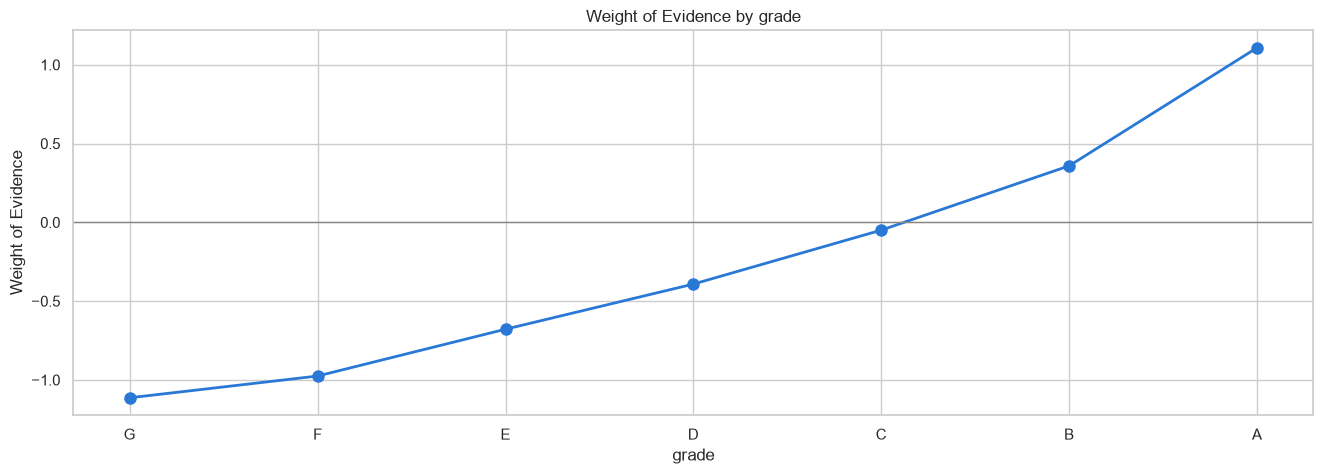

In [22]:
# woe_df = the WoE table of the variable we are looking at (we reuse this name for every variable)
woe_df = woe_table(loan_data_inputs_train['grade'], loan_data_targets_train, sort_by_woe=True)

# display() shows a table as a nicely formatted table inside Jupyter / Colab (print() would show plain text).
# A table on the LAST line of a cell is displayed automatically; in the middle of a cell we need display().
display(woe_df)
plot_by_woe(woe_df)

**How to read the chart:** each dot is one category. Higher means safer (relatively more good loans), lower means riskier, and the grey line at 0 is the average loan.
- A steady staircase, like this one, means a strong and sensible variable.
- A flat line close to 0 means the variable does not separate good from bad.
- Wild jumps usually mean categories that are too small (noise).

**What we see:** a perfect staircase. Grade A loans are 96.1% good (WoE +1.11), grade G loans only 72.8% good (WoE -1.11). IV = 0.29, one of our best variables.

**Decision:** keep all 7 grades as separate categories. They are large enough (even G has 2,654 loans), and the dummy columns `grade:A` ... `grade:G` already exist from Section 3.5. The riskiest category, G, will be the **reference category** (explained in Part 7).

#### `home_ownership`: does the borrower rent, own, or pay off a mortgage?
**What we expect:** renters are a bit riskier than home owners (owners usually have more stable finances).

,home_ownership,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,OTHER,137,109,28,0.795620,0.000367,0.000328,0.000687,-0.738602,NaN,NaN,inf
1,NONE,40,34,6,0.850000,0.000107,0.000102,0.000147,-0.363144,0.054380,0.375458,inf
2,RENT,150599,131604,18995,0.873870,0.403720,0.396099,0.465815,-0.162123,0.023870,0.201021,inf
3,OWN,33295,29717,3578,0.892536,0.089256,0.089442,0.087743,0.019170,0.018666,0.181294,inf
4,MORTGAGE,188956,170785,18171,0.903835,0.506546,0.514026,0.445608,0.142834,0.011298,0.123663,inf
5,ANY,1,1,0,1.000000,0.000003,0.000003,0.000000,inf,0.096165,inf,inf


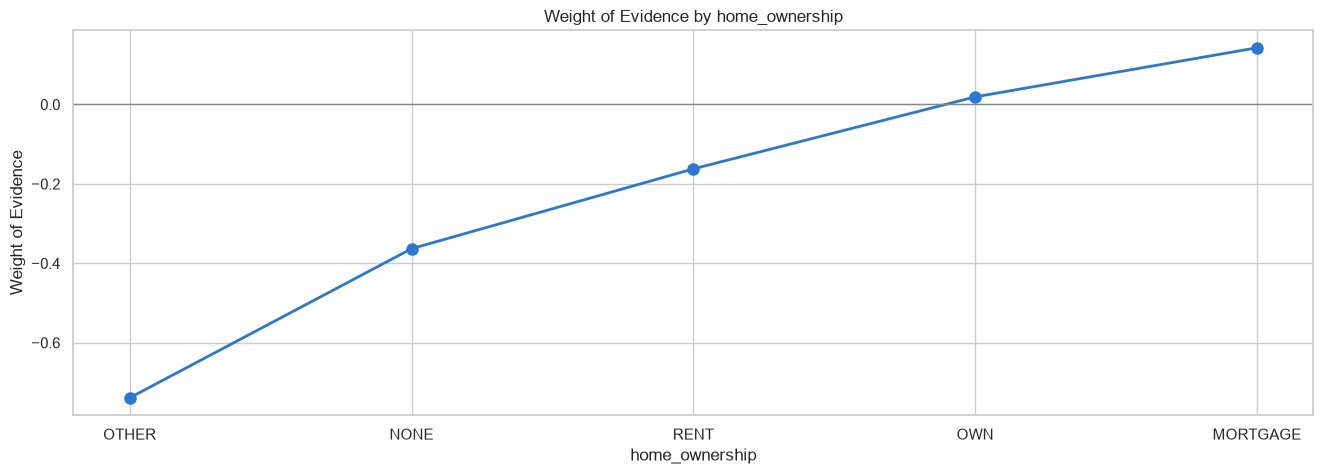

In [23]:
woe_df = woe_table(loan_data_inputs_train['home_ownership'], loan_data_targets_train, sort_by_woe=True)
display(woe_df)
plot_by_woe(woe_df)

**What we see:**
- `OTHER` (137 loans), `NONE` (40) and `ANY` (1 loan) are tiny.
- `ANY` has 1 loan and 0 bad loans, so its WoE is **+infinity**, and that makes the IV of the whole variable infinite (`inf`). This is the classic "category too small" problem.
- Among the big groups, `RENT` is the riskiest (87.4% good) and `MORTGAGE` the safest (90.4%).

**Decision:** merge `OTHER`, `NONE` and `ANY` into the riskiest big group, `RENT`. The result is three categories: `RENT_OTHER_NONE_ANY` (reference category), `OWN`, `MORTGAGE`.

**If we skip the merge:** the model would estimate a separate effect from a single loan (`ANY`), which is pure luck.

In [24]:
# New category: 1 if the borrower rents or is in one of the tiny groups, else 0
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['home_ownership:RENT_OTHER_NONE_ANY'] = np.where(df['home_ownership'].isin(['RENT', 'OTHER', 'NONE', 'ANY']), 1, 0)

#### `addr_state`: US state of the borrower
**What we expect:** some differences between states (local economy, local laws), but no natural order.

,addr_state,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,NE,13,6,7,0.461538,0.000035,0.000018,0.000172,-2.251896,NaN,NaN,inf
1,IA,13,10,3,0.769231,0.000035,0.000030,0.000074,-0.893772,0.307692,1.358123,inf
2,NV,5221,4514,707,0.864585,0.013996,0.013586,0.017338,-0.243837,0.095355,0.649935,inf
3,FL,25211,22080,3131,0.875808,0.067585,0.066456,0.076782,-0.144425,0.011223,0.099411,inf
4,HI,2001,1755,246,0.877061,0.005364,0.005282,0.006033,-0.132852,0.001253,0.011573,inf
5,AL,4671,4098,573,0.877328,0.012522,0.012334,0.014052,-0.130376,0.000267,0.002476,inf
6,NM,2075,1833,242,0.883373,0.005563,0.005517,0.005935,-0.072973,0.006045,0.057403,inf
7,VA,11366,10046,1320,0.883864,0.030470,0.030236,0.032370,-0.068202,0.000491,0.004771,inf
8,NY,32211,28474,3737,0.883984,0.086350,0.085701,0.091643,-0.067037,0.000120,0.001165,inf
9,OK,3284,2904,380,0.884287,0.008804,0.008740,0.009319,-0.064072,0.000304,0.002965,inf


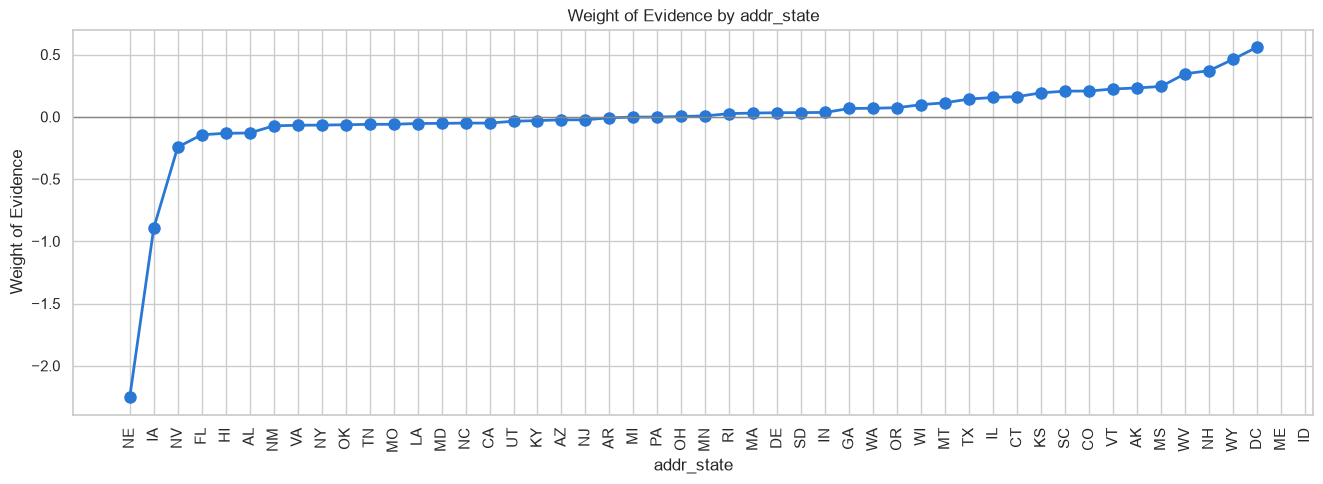

In [25]:
woe_df = woe_table(loan_data_inputs_train['addr_state'], loan_data_targets_train, sort_by_woe=True)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** both ends of the line are tiny states: `NE` and `IA` (13 loans each) at the risky end, `ME` and `ID` (2 and 10 loans, no bad loans at all, so WoE = `inf`) at the safe end. They make the chart jump and squeeze everything else into the middle. Let's leave out the two states at each end and zoom in.

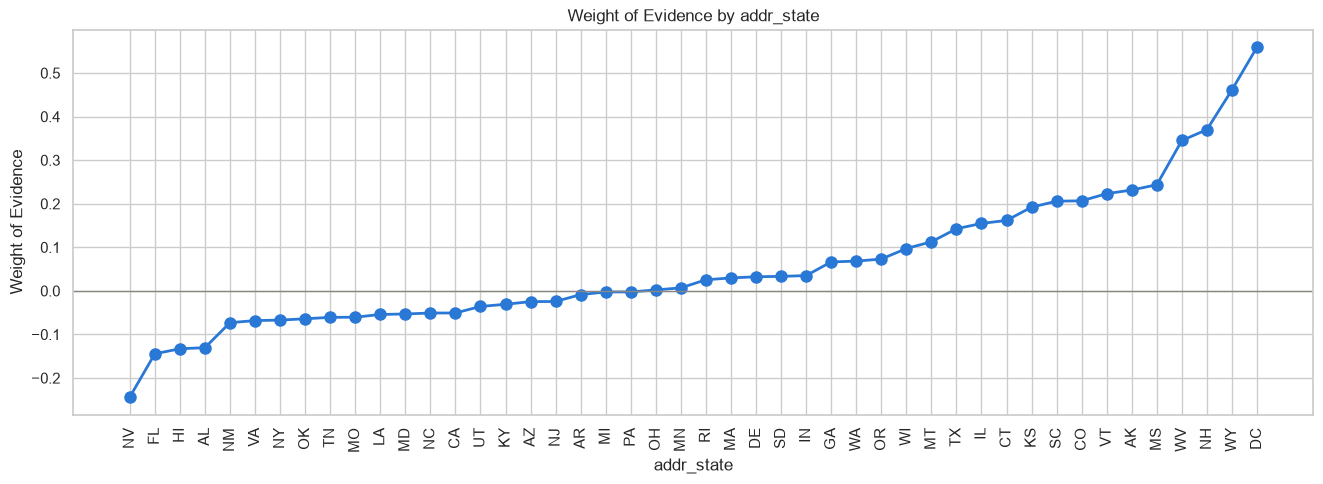

In [26]:
# .iloc[2:-2, :] -> all rows except the first 2 and the last 2
plot_by_woe(woe_df.iloc[2:-2, :], 90)

**Decision:** we follow the grouping of the original analysis, which puts states with similar WoE together until every group is large enough. Big states (`NY`, `CA`, `TX`) have enough loans to stay on their own:

| Group | States |
|---|---|
| ND_NE_IA_NV_FL_HI_AL (riskiest, reference) | North Dakota, Nebraska, Iowa, Nevada, Florida, Hawaii, Alabama |
| NM_VA | New Mexico, Virginia |
| NY | New York |
| OK_TN_MO_LA_MD_NC | Oklahoma, Tennessee, Missouri, Louisiana, Maryland, North Carolina |
| CA | California |
| UT_KY_AZ_NJ | Utah, Kentucky, Arizona, New Jersey |
| AR_MI_PA_OH_MN | Arkansas, Michigan, Pennsylvania, Ohio, Minnesota |
| RI_MA_DE_SD_IN | Rhode Island, Massachusetts, Delaware, South Dakota, Indiana |
| GA_WA_OR | Georgia, Washington, Oregon |
| WI_MT | Wisconsin, Montana |
| TX | Texas |
| IL_CT | Illinois, Connecticut |
| KS_SC_CO_VT_AK_MS | Kansas, South Carolina, Colorado, Vermont, Alaska, Mississippi |
| WV_NH_WY_DC_ME_ID (safest) | West Virginia, New Hampshire, Wyoming, Washington DC, Maine, Idaho |

**North Dakota (ND)** has no loans at all in this data (Lending Club did not lend there in 2007-2014). A future applicant from ND still needs a category, so we put it in the riskiest group, which is the cautious choice. `isin()` handles a state with zero loans automatically.

**Common beginner mistake:** forgetting categories that do not appear in the training data. When the model later meets them, the code crashes or silently gives 0 in every column.

In [27]:
# state_groups = name of each group -> list of the states in it
state_groups = {
    'ND_NE_IA_NV_FL_HI_AL': ['ND', 'NE', 'IA', 'NV', 'FL', 'HI', 'AL'],
    'NM_VA': ['NM', 'VA'],
    'NY': ['NY'],
    'OK_TN_MO_LA_MD_NC': ['OK', 'TN', 'MO', 'LA', 'MD', 'NC'],
    'CA': ['CA'],
    'UT_KY_AZ_NJ': ['UT', 'KY', 'AZ', 'NJ'],
    'AR_MI_PA_OH_MN': ['AR', 'MI', 'PA', 'OH', 'MN'],
    'RI_MA_DE_SD_IN': ['RI', 'MA', 'DE', 'SD', 'IN'],
    'GA_WA_OR': ['GA', 'WA', 'OR'],
    'WI_MT': ['WI', 'MT'],
    'TX': ['TX'],
    'IL_CT': ['IL', 'CT'],
    'KS_SC_CO_VT_AK_MS': ['KS', 'SC', 'CO', 'VT', 'AK', 'MS'],
    'WV_NH_WY_DC_ME_ID': ['WV', 'NH', 'WY', 'DC', 'ME', 'ID'],
}

# One new 0/1 column per group, e.g. 'addr_state:NM_VA' = 1 if the borrower lives in New Mexico or Virginia
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    for group_name, states in state_groups.items():
        df['addr_state:' + group_name] = np.where(df['addr_state'].isin(states), 1, 0)

#### `verification_status`: was the borrower's income checked?
**What we expect:** checked (verified) incomes should be safer.

,verification_status,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,Verified,134414,117314,17100,0.872781,0.360332,0.353090,0.419344,-0.171969,NaN,NaN,0.020384
1,Source Verified,120030,107537,12493,0.895918,0.321772,0.323663,0.306366,0.054922,0.023137,0.226891,0.020384
2,Not Verified,118584,107399,11185,0.905679,0.317896,0.323248,0.274290,0.164232,0.009761,0.109311,0.020384


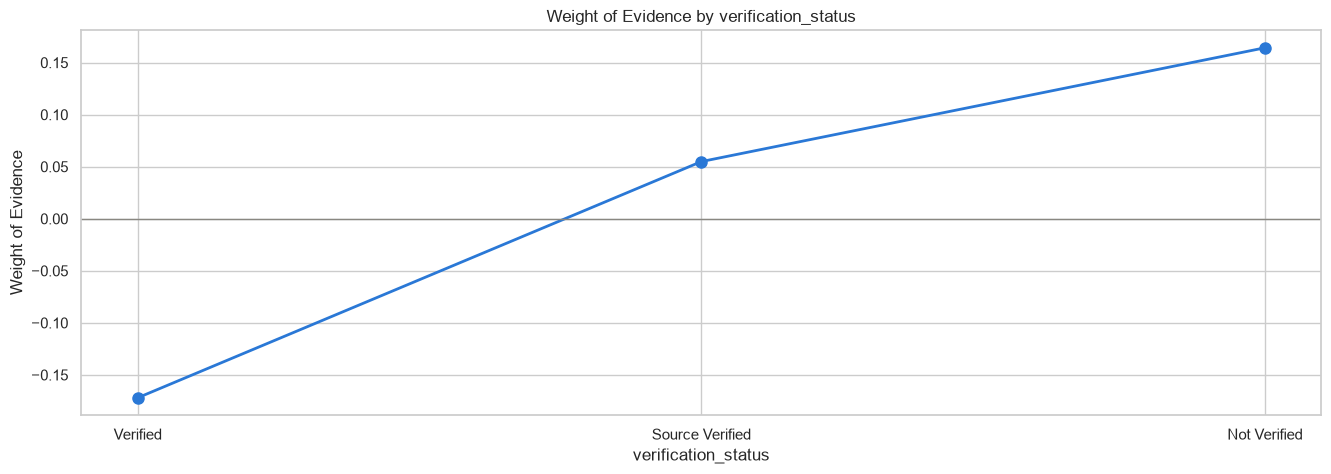

In [28]:
woe_df = woe_table(loan_data_inputs_train['verification_status'], loan_data_targets_train, sort_by_woe=True)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** the **opposite** of what we expected. `Verified` loans are the riskiest (87.3% good) and `Not Verified` the safest (90.6% good).
A likely reason: Lending Club mainly checked incomes when an application already looked risky or the loan was large, so "verified" is a sign that the lender was already worried.
IV = 0.020, a weak variable.

**Lesson:** do not force your expectations on the data, but always look for an explanation before trusting a surprising pattern.

**Decision:** keep the three categories as they are (`verification_status:...` dummies already exist). Reference category: `Verified` (riskiest).

#### `purpose`: what the borrower wants the money for

,purpose,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,small_business,5582,4388,1194,0.786098,0.014964,0.013207,0.029280,-0.796180,NaN,NaN,0.035418
1,educational,333,267,66,0.801802,0.000893,0.000804,0.001619,-0.700151,0.015704,0.096029,0.035418
2,moving,2392,2008,384,0.839465,0.006412,0.006044,0.009417,-0.443493,0.037663,0.256658,0.035418
3,house,1830,1574,256,0.860109,0.004906,0.004737,0.006278,-0.281547,0.020644,0.161946,0.035418
4,other,18884,16283,2601,0.862264,0.050624,0.049008,0.063784,-0.263519,0.002155,0.018028,0.035418
5,renewable_energy,281,243,38,0.864769,0.000753,0.000731,0.000932,-0.242270,0.002504,0.021250,0.035418
6,medical,3684,3199,485,0.868350,0.009876,0.009628,0.011894,-0.211300,0.003581,0.030969,0.035418
7,wedding,1887,1664,223,0.881823,0.005059,0.005008,0.005469,-0.087937,0.013473,0.123363,0.035418
8,vacation,1991,1757,234,0.882471,0.005337,0.005288,0.005738,-0.081703,0.000648,0.006234,0.035418
9,debt_consolidation,219183,194390,24793,0.886884,0.587578,0.585071,0.607999,-0.038440,0.004413,0.043263,0.035418


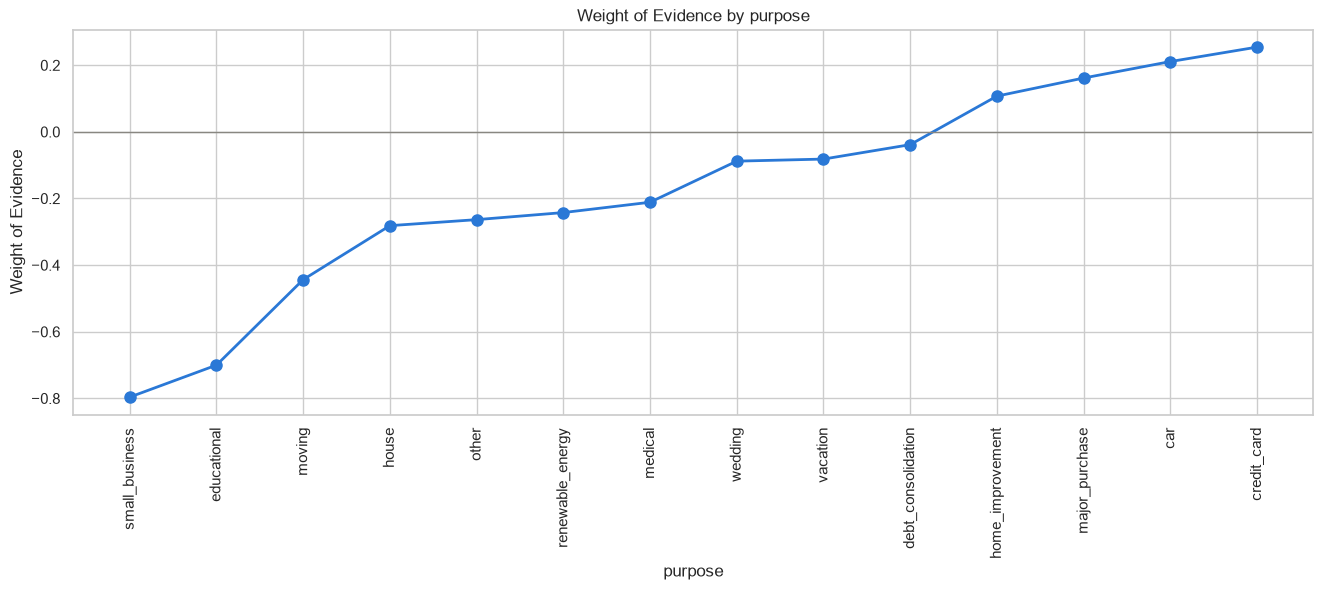

In [29]:
woe_df = woe_table(loan_data_inputs_train['purpose'], loan_data_targets_train, sort_by_woe=True)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** `small_business` (78.6% good) and `educational` (80.2%) are the riskiest; `credit_card` (91.3%) is the safest. `debt_consolidation` holds 59% of all loans and sits in the middle.

**Decision:** five groups. Each group is a run of **neighbours** in the sorted table with similar WoE:

| New category | Purposes inside | Share good |
|---|---|---|
| `small_business__educational` (riskiest, reference) | small business, educational | ≈ 79% |
| `moving__house__other__ren_energy__medical` | moving, house, other, renewable energy, medical | ≈ 86% |
| `wedding__vacation__debt_consolidation` | wedding, vacation, debt consolidation | ≈ 89% |
| `home_impr__major_purch__car` | home improvement, major purchase, car | ≈ 90% |
| `credit_card` | stays alone (safest, and large) | ≈ 91% |

**Common beginner mistake:** grouping categories by what "sounds similar" (for example "wedding" with "vacation" because both are fun) instead of by their WoE. The groups must follow the data.

In [30]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['purpose:small_business__educational'] = np.where(
        df['purpose'].isin(['small_business', 'educational']), 1, 0)
    df['purpose:moving__house__other__ren_energy__medical'] = np.where(
        df['purpose'].isin(['moving', 'house', 'other', 'renewable_energy', 'medical']), 1, 0)
    df['purpose:wedding__vacation__debt_consolidation'] = np.where(
        df['purpose'].isin(['wedding', 'vacation', 'debt_consolidation']), 1, 0)
    df['purpose:home_impr__major_purch__car'] = np.where(
        df['purpose'].isin(['home_improvement', 'major_purchase', 'car']), 1, 0)
    # 'purpose:credit_card' already exists from Section 3.5

#### `initial_list_status`: was the loan offered to investors in fractions (f) or as a whole (w)?

,initial_list_status,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,f,242514,213338,29176,0.879694,0.650123,0.642101,0.715484,-0.108214,NaN,NaN,0.02478
1,w,130514,118912,11602,0.911105,0.349877,0.357899,0.284516,0.229461,0.031412,0.337675,0.02478


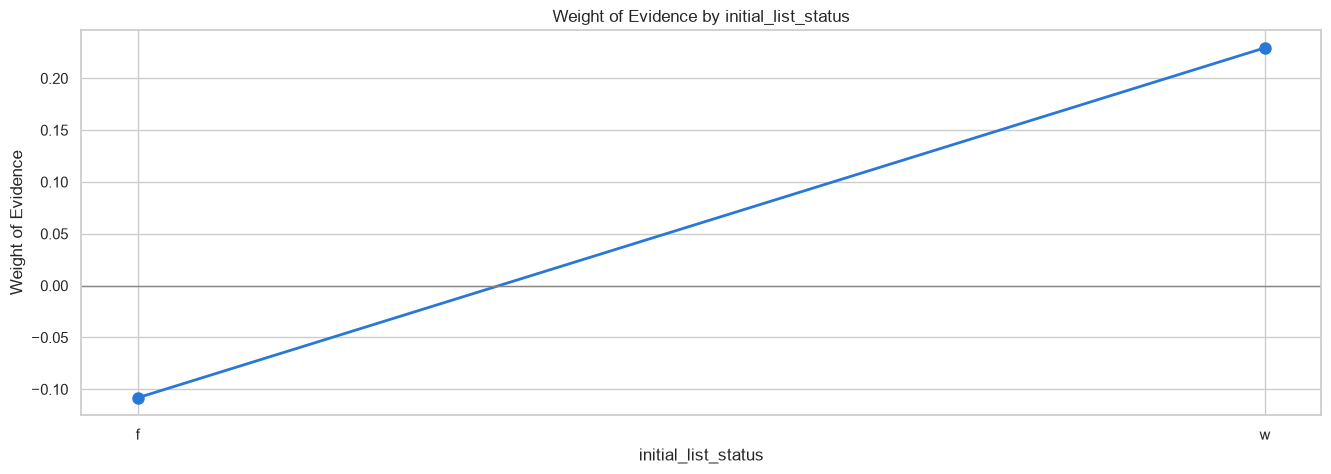

In [31]:
woe_df = woe_table(loan_data_inputs_train['initial_list_status'], loan_data_targets_train, sort_by_woe=True)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** `f` loans are 88.0% good and `w` loans 91.1%. IV = 0.025 (weak).
Note: whole-loan listing (`w`) only started around the end of 2012, so `w` loans are mostly *young* loans. Part of the difference is the "young loans look safe" effect from Part 4.

**Decision:** keep both categories (dummies already exist). Reference category: `f`.

### 6.6 Number variables (ordered, so we keep the natural order and do not sort by WoE)

**Note on `inf` in these tables:** the `IV` column of a detailed table often shows `inf`. One of the many tiny groups (for example the few borrowers with 16 late payments) has no bad loans, so its WoE is infinite, and so is the sum. That is expected at this stage. The IV that counts is the one of the **final** categories, computed in Part 7, and the notes below quote that one.

#### `term_int`: 36 or 60 monthly payments

,term_int,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,36,270419,244187,26232,0.902995,0.724929,0.73495,0.643288,0.133209,NaN,NaN,0.039434
1,60,102609,88063,14546,0.858239,0.275071,0.26505,0.356712,-0.297009,0.044756,0.430218,0.039434


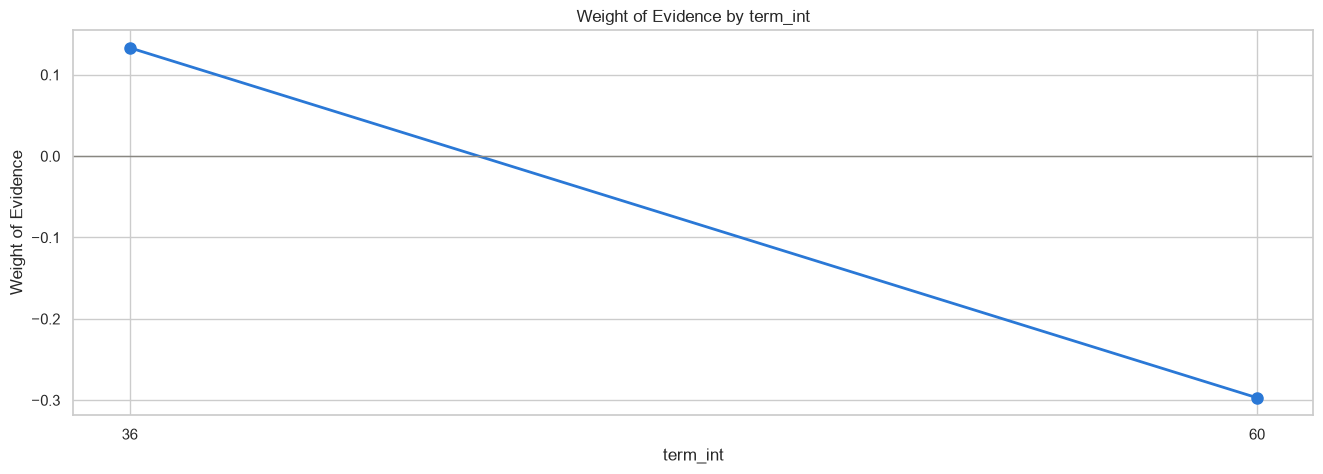

In [32]:
woe_df = woe_table(loan_data_inputs_train['term_int'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** 36-month loans are 90.3% good, 60-month loans only 85.8%. IV = 0.039 (weak, but clear).

**Decision:** two categories, `term:36` and `term:60`. Reference category: `term:60` (riskier).

In [33]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['term:36'] = np.where(df['term_int'] == 36, 1, 0)
    df['term:60'] = np.where(df['term_int'] == 60, 1, 0)

#### `emp_length_int`: years in the current job (0 to 10)

,emp_length_int,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0,45720,40069,5651,0.876400,0.122565,0.120599,0.138580,-0.138975,NaN,NaN,0.006506
1,1,23654,20981,2673,0.886996,0.063411,0.063148,0.065550,-0.037329,0.010596,0.101645,0.006506
2,2,33078,29471,3607,0.890955,0.088674,0.088701,0.088455,0.002785,0.003959,0.040114,0.006506
3,3,29205,26015,3190,0.890772,0.078292,0.078299,0.078228,0.000907,0.000183,0.001878,0.006506
4,4,22468,20011,2457,0.890644,0.060231,0.060229,0.060253,-0.000404,0.000128,0.001311,0.006506
5,5,24602,21766,2836,0.884725,0.065952,0.065511,0.069547,-0.059790,0.005920,0.059387,0.006506
6,6,20887,18462,2425,0.883899,0.055993,0.055567,0.059468,-0.067862,0.000826,0.008071,0.006506
7,7,21049,18680,2369,0.887453,0.056427,0.056223,0.058095,-0.032759,0.003554,0.035102,0.006506
8,8,17853,15887,1966,0.889878,0.047860,0.047816,0.048212,-0.008245,0.002425,0.024515,0.006506
9,9,14267,12650,1617,0.886662,0.038246,0.038074,0.039654,-0.040660,0.003217,0.032416,0.006506


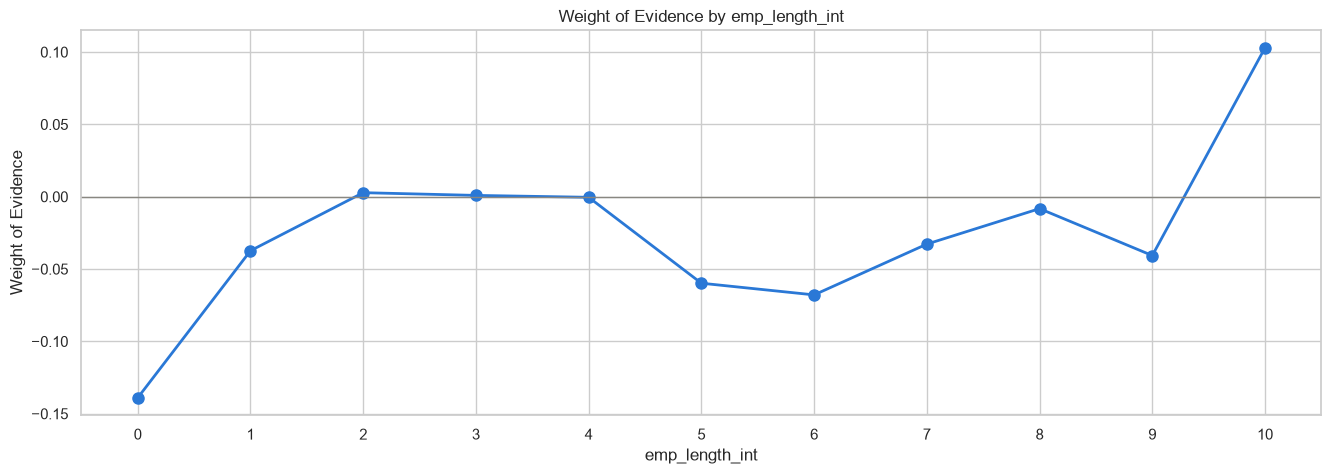

In [34]:
woe_df = woe_table(loan_data_inputs_train['emp_length_int'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** almost flat. Borrowers with less than a year (0) are 87.6% good and those with 10+ years are 90.0% good; everything in between is about 88.4% to 89.1%. IV = 0.006, "useless" by the rule of thumb.

**Decision:** six categories `0`, `1`, `2-4`, `5-6`, `7-9`, `10`. Expect this variable to be dropped in Part 7 because of its low IV.

In [35]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['emp_length:0'] = np.where(df['emp_length_int'] == 0, 1, 0)
    df['emp_length:1'] = np.where(df['emp_length_int'] == 1, 1, 0)
    df['emp_length:2-4'] = np.where((df['emp_length_int'] >= 2) & (df['emp_length_int'] <= 4), 1, 0)
    df['emp_length:5-6'] = np.where((df['emp_length_int'] >= 5) & (df['emp_length_int'] <= 6), 1, 0)
    df['emp_length:7-9'] = np.where((df['emp_length_int'] >= 7) & (df['emp_length_int'] <= 9), 1, 0)
    df['emp_length:10'] = np.where(df['emp_length_int'] == 10, 1, 0)

#### `mths_since_issue_d`: loan age (a trap!)
Months between the issue date and our fixed reference date. Fine classing: 50 equally wide intervals.

,mths_since_issue_d,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(35.91, 37.8]",28170,26543,1627,0.942244,0.075517,0.079889,0.039899,0.694283,NaN,NaN,0.113186
1,"(37.8, 39.6]",39636,36799,2837,0.928424,0.106255,0.110757,0.069572,0.464979,0.013820,0.229305,0.113186
2,"(39.6, 41.4]",38614,35420,3194,0.917284,0.103515,0.106606,0.078327,0.308258,0.011140,0.156721,0.113186
3,"(41.4, 43.2]",29038,26384,2654,0.908603,0.077844,0.079410,0.065084,0.198945,0.008681,0.109313,0.113186
4,"(43.2, 45.0]",28367,25581,2786,0.901787,0.076045,0.076993,0.068321,0.119498,0.006815,0.079447,0.113186
5,"(45.0, 46.8]",12165,10940,1225,0.899301,0.032611,0.032927,0.030041,0.091740,0.002486,0.027758,0.113186
6,"(46.8, 48.6]",24451,21979,2472,0.898900,0.065547,0.066152,0.060621,0.087315,0.000401,0.004425,0.113186
7,"(48.6, 50.4]",22969,20404,2565,0.888328,0.061574,0.061412,0.062902,-0.023972,0.010572,0.111287,0.113186
8,"(50.4, 52.2]",20640,18174,2466,0.880523,0.055331,0.054700,0.060474,-0.100350,0.007804,0.076378,0.113186
9,"(52.2, 54.0]",18312,15874,2438,0.866863,0.049090,0.047777,0.059787,-0.224240,0.013660,0.123890,0.113186


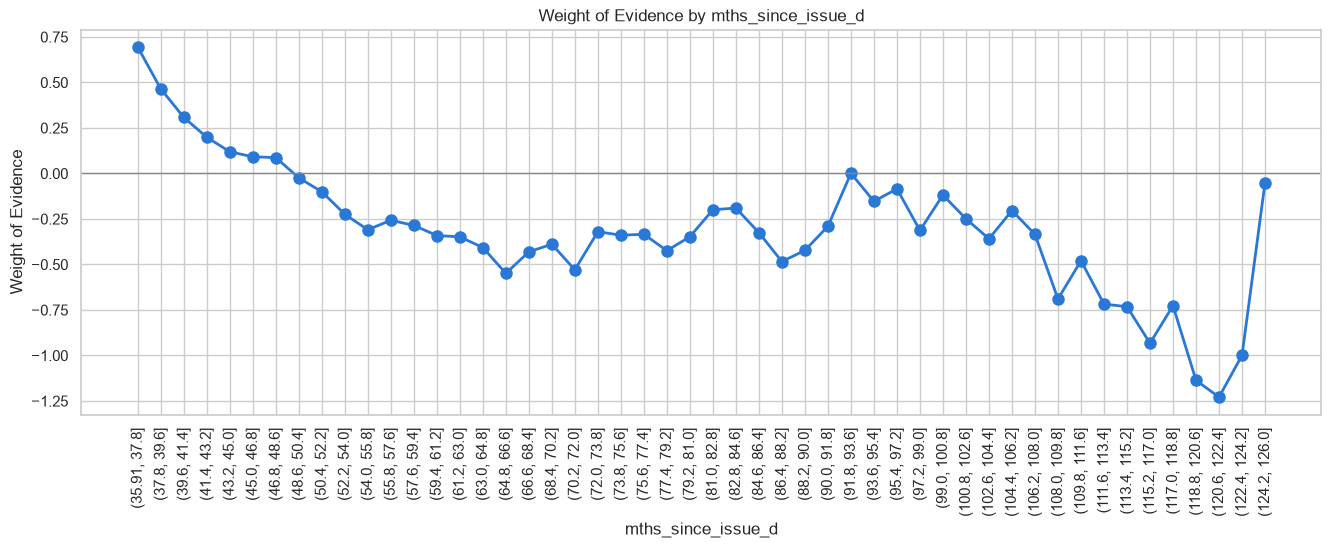

In [36]:
# pd.cut(column, 50) -> cut the range of values into 50 equally wide intervals (fine classing)
woe_df = woe_table(pd.cut(loan_data_inputs_train['mths_since_issue_d'], 50), loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** a strong pattern. The youngest loans are about 94% good and the oldest only about 70% to 75%. IV ≈ 0.11, "medium". It looks like a great predictor, but it is a **trap**:

1. **Young loans have not had time to default.** Many of them are `Current` and therefore counted as good (Part 4). The variable measures *how long we have been watching the loan*, not how risky the borrower is.
2. **It is meaningless for a new applicant.** At the moment of application the loan age is always 0, so every new applicant would land in the "safest" category and get an inflated score.

**Decision:** we do **not** use loan age in the PD model and create no categories for it. (When we tried adding it, the test AUC from Part 9 rose only from about 0.68 to about 0.70, and that small gain is fake.)

**Common beginner mistake:** keeping a variable because it has a high IV or raises the AUC, without asking two questions: *"Would I know this value at the moment of the decision?"* and *"Does it describe the borrower, or just the passing of time?"*

#### `int_rate`: the interest rate of the loan

,int_rate,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(5.399, 5.833]",785,755,30,0.961783,0.002104,0.002272,0.000736,1.127775,NaN,NaN,0.343349
1,"(5.833, 6.246]",8459,8293,166,0.980376,0.022677,0.024960,0.004071,1.813434,0.018592,0.685659,0.343349
2,"(6.246, 6.658]",7826,7603,223,0.971505,0.020980,0.022883,0.005469,1.431381,0.008871,0.382053,0.343349
3,"(6.658, 7.071]",1816,1767,49,0.973018,0.004868,0.005318,0.001202,1.487473,0.001512,0.056092,0.343349
4,"(7.071, 7.484]",3143,3069,74,0.976456,0.008426,0.009237,0.001815,1.627297,0.003438,0.139824,0.343349
5,"(7.484, 7.897]",12581,12107,474,0.962324,0.033727,0.036439,0.011624,1.142587,0.014131,0.484710,0.343349
6,"(7.897, 8.31]",9687,9196,491,0.949314,0.025969,0.027678,0.012041,0.832335,0.013011,0.310252,0.343349
7,"(8.31, 8.722]",6594,6365,229,0.965271,0.017677,0.019157,0.005616,1.227103,0.015958,0.394768,0.343349
8,"(8.722, 9.135]",9539,8942,597,0.937415,0.025572,0.026913,0.014640,0.608852,0.027857,0.618250,0.343349
9,"(9.135, 9.548]",6681,6440,241,0.963928,0.017910,0.019383,0.005910,1.187742,0.026513,0.578889,0.343349


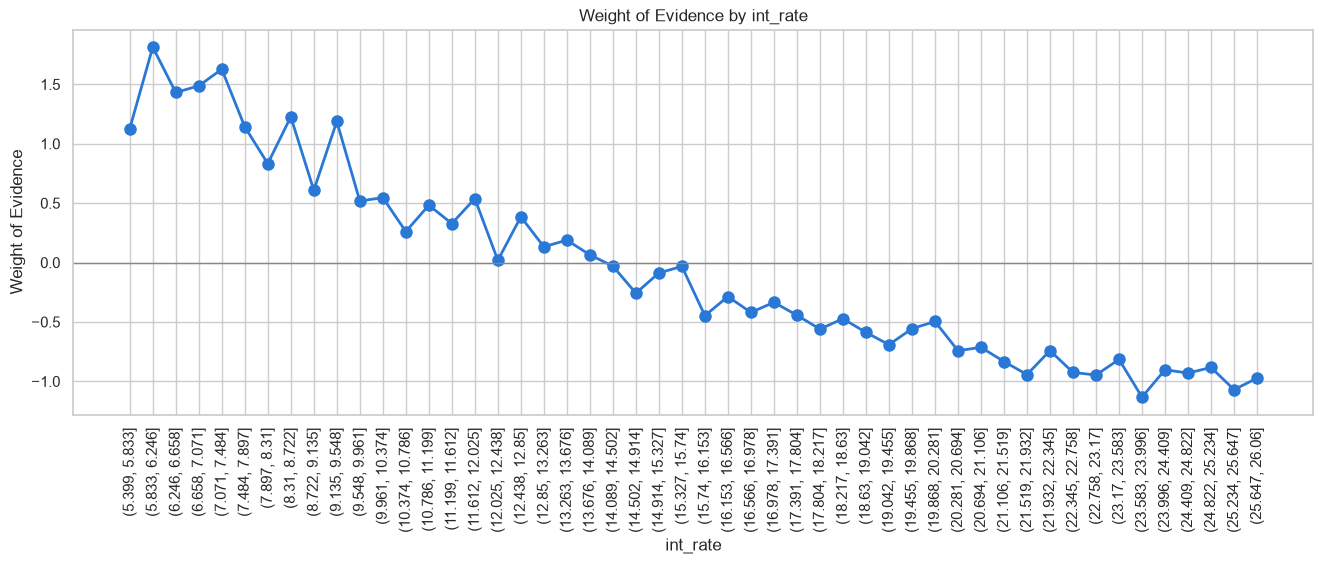

In [37]:
woe_df = woe_table(pd.cut(loan_data_inputs_train['int_rate'], 50), loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** a strong, steadily falling line. Loans below about 9.5% interest are 93% to 98% good; above about 20% they are only about 72% to 80% good. This makes sense: Lending Club charged riskier borrowers higher rates, so the rate already contains Lending Club's own risk assessment. IV ≈ 0.34 with 50 intervals (≈ 0.31 after merging into the 5 final categories), our strongest variable.

**Keep in mind:** `int_rate` and `grade` are *outputs* of Lending Club's own credit decision. Using them is fine for studying these loans. But a lender building a scorecard from scratch would not have them, and using a model built on the interest rate to *set* the interest rate would be circular.

**Decision:** five categories, with edges where the WoE line changes level: `<=9.548`, `9.548-12.025`, `12.025-15.74`, `15.74-20.281`, `>20.281` (reference category: riskiest). The odd-looking edges such as 9.548 are interval edges from the fine classing above.

In [38]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['int_rate:<=9.548'] = np.where(df['int_rate'] <= 9.548, 1, 0)
    df['int_rate:9.548-12.025'] = np.where((df['int_rate'] > 9.548) & (df['int_rate'] <= 12.025), 1, 0)
    df['int_rate:12.025-15.74'] = np.where((df['int_rate'] > 12.025) & (df['int_rate'] <= 15.74), 1, 0)
    df['int_rate:15.74-20.281'] = np.where((df['int_rate'] > 15.74) & (df['int_rate'] <= 20.281), 1, 0)
    df['int_rate:>20.281'] = np.where(df['int_rate'] > 20.281, 1, 0)

#### `funded_amnt`: the loan amount

,funded_amnt,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(465.5, 1190.0]",1224,1108,116,0.905229,0.003281,0.003335,0.002845,0.158977,NaN,NaN,0.014139
1,"(1190.0, 1880.0]",3028,2737,291,0.903897,0.008117,0.008238,0.007136,0.143549,0.001332,0.015427,0.014139
2,"(1880.0, 2570.0]",6018,5379,639,0.893819,0.016133,0.016190,0.015670,0.032608,0.010078,0.110941,0.014139
3,"(2570.0, 3260.0]",7248,6444,804,0.889073,0.019430,0.019395,0.019717,-0.016440,0.004746,0.049048,0.014139
4,"(3260.0, 3950.0]",4751,4236,515,0.891602,0.012736,0.012749,0.012629,0.009463,0.002529,0.025902,0.014139
5,"(3950.0, 4640.0]",9023,8039,984,0.890945,0.024189,0.024196,0.024131,0.002689,0.000656,0.006774,0.014139
6,"(4640.0, 5330.0]",15903,14188,1715,0.892159,0.042632,0.042703,0.042057,0.015238,0.001213,0.012549,0.014139
7,"(5330.0, 6020.0]",17236,15617,1619,0.906069,0.046206,0.047004,0.039703,0.168806,0.013910,0.153568,0.014139
8,"(6020.0, 6710.0]",6914,6137,777,0.887619,0.018535,0.018471,0.019054,-0.031094,0.018449,0.199900,0.014139
9,"(6710.0, 7400.0]",11806,10602,1204,0.898018,0.031649,0.031910,0.029526,0.077648,0.010399,0.108742,0.014139


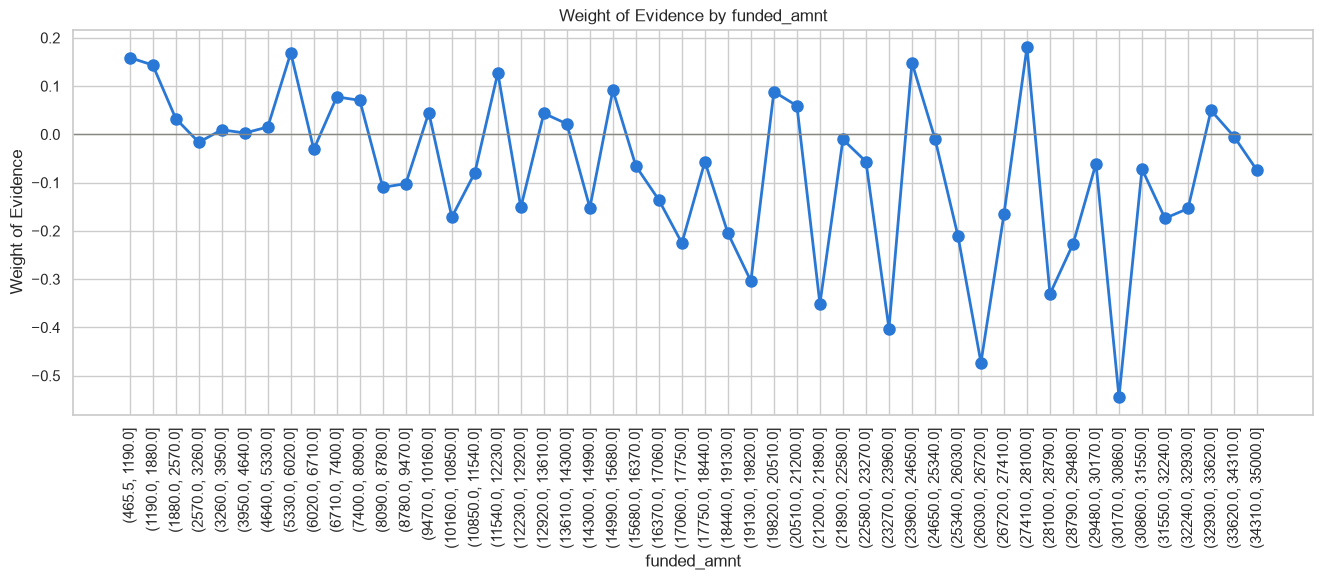

In [39]:
woe_df = woe_table(pd.cut(loan_data_inputs_train['funded_amnt'], 50), loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** the line jumps up and down. Most intervals are between about 85% and 91% good (the extremes, about 82% and 91%, are small groups); at most, larger loans are slightly riskier. On its own, the amount says little about the chance of default, and affordability is already covered by income, `dti` and the term.

**Decision:** not used in the PD model. (The amount matters a lot for **EAD** and Expected Loss, where we use it later.)

#### `mths_since_earliest_cr_line`: length of credit history when the loan was given
Fine classing on loans with up to 400 months (≈ 33 years) of history, which is about 97% of the loans. The few longer histories would only stretch the chart.

,mths_since_earliest_cr_line,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-0.4, 8.0]",36,29,7,0.805556,0.000099,0.000090,0.000176,-0.669722,NaN,NaN,0.031115
1,"(8.0, 16.0]",46,33,13,0.717391,0.000127,0.000102,0.000326,-1.159549,0.088164,0.489827,0.031115
2,"(16.0, 24.0]",70,51,19,0.728571,0.000193,0.000158,0.000477,-1.103721,0.011180,0.055828,0.031115
3,"(24.0, 32.0]",44,32,12,0.727273,0.000121,0.000099,0.000301,-1.110278,0.001299,0.006557,0.031115
4,"(32.0, 40.0]",1138,970,168,0.852373,0.003139,0.003006,0.004215,-0.337775,0.125100,0.772503,0.031115
5,"(40.0, 48.0]",2560,2192,368,0.856250,0.007062,0.006794,0.009232,-0.306621,0.003877,0.031155,0.031115
6,"(48.0, 56.0]",3137,2637,500,0.840612,0.008654,0.008173,0.012543,-0.428318,0.015638,0.121698,0.031115
7,"(56.0, 64.0]",4262,3640,622,0.854059,0.011757,0.011282,0.015604,-0.324309,0.013447,0.104010,0.031115
8,"(64.0, 72.0]",5474,4614,860,0.842894,0.015101,0.014301,0.021574,-0.411189,0.011165,0.086881,0.031115
9,"(72.0, 80.0]",7072,6121,951,0.865526,0.019509,0.018972,0.023857,-0.229141,0.022632,0.182049,0.031115


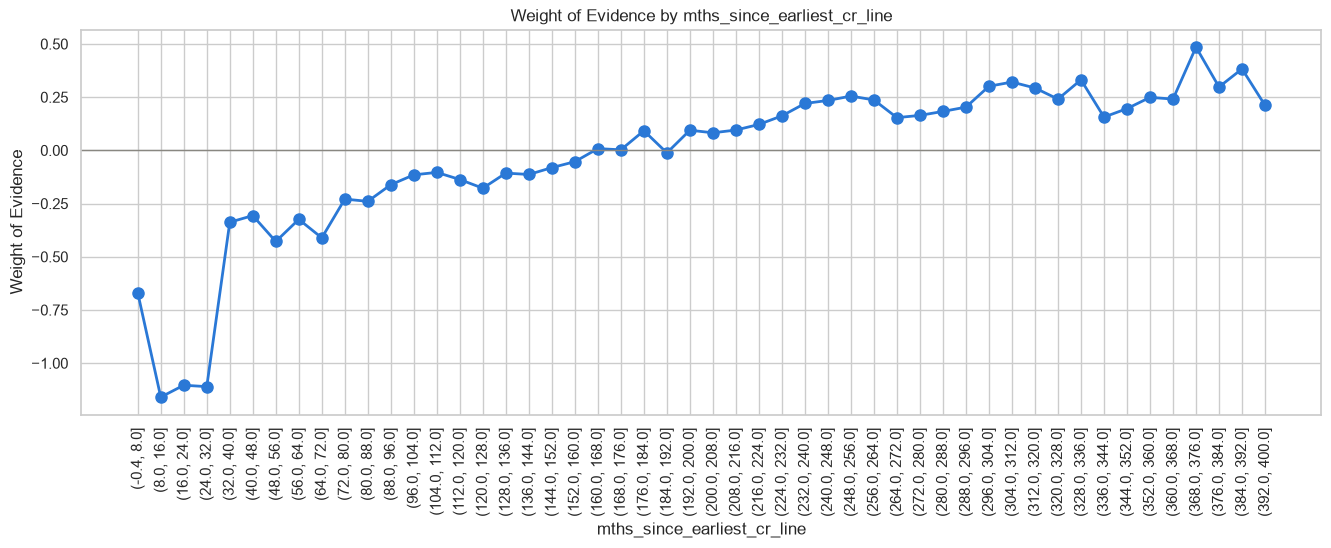

In [40]:
# up_to_400 = True for loans with at most 400 months of credit history
up_to_400 = loan_data_inputs_train['mths_since_earliest_cr_line'] <= 400
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[up_to_400, 'mths_since_earliest_cr_line'], 50),
                   loan_data_targets_train[up_to_400])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** short credit histories are risky. Under 3 years about 72% to 80% of loans are good (these are tiny groups), and 3 to 6 years about 84% to 86%. The good share then rises steadily to about 91% for histories of 20+ years.

**Decision:** six categories in months, with the years in brackets: `<=72` (up to 6 years, reference category), `73-96` (6-8), `97-160` (8-13), `161-240` (13-20), `241-300` (20-25), `>300` (more than 25 years).
(These edges are new. The original version of this notebook measured credit history up to December 2017 instead of up to the loan date, so its edges no longer fit; see Section 3.3.)

In [41]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    months = df['mths_since_earliest_cr_line']    # short nickname, to keep the lines readable
    df['mths_since_earliest_cr_line:<=72'] = np.where(months <= 72, 1, 0)
    df['mths_since_earliest_cr_line:73-96'] = np.where((months >= 73) & (months <= 96), 1, 0)
    df['mths_since_earliest_cr_line:97-160'] = np.where((months >= 97) & (months <= 160), 1, 0)
    df['mths_since_earliest_cr_line:161-240'] = np.where((months >= 161) & (months <= 240), 1, 0)
    df['mths_since_earliest_cr_line:241-300'] = np.where((months >= 241) & (months <= 300), 1, 0)
    df['mths_since_earliest_cr_line:>300'] = np.where(months > 300, 1, 0)

#### `delinq_2yrs`: times the borrower was 30+ days late in the last 2 years

,delinq_2yrs,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0.0,306417,272864,33553,0.890499,0.821432,0.821261,0.822821,-0.001898,NaN,NaN,inf
1,1.0,44927,40131,4796,0.893249,0.120439,0.120786,0.117612,0.026622,0.002750,2.851964e-02,inf
2,2.0,13118,11662,1456,0.889007,0.035166,0.035100,0.035706,-0.017102,0.004242,4.372412e-02,inf
3,3.0,4550,4019,531,0.883297,0.012197,0.012096,0.013022,-0.073719,0.005711,5.661637e-02,inf
4,4.0,1868,1679,189,0.898822,0.005008,0.005053,0.004635,0.086462,0.015526,1.601803e-01,inf
5,5.0,966,852,114,0.881988,0.002590,0.002564,0.002796,-0.086357,0.016835,1.728186e-01,inf
6,6.0,501,452,49,0.902196,0.001343,0.001360,0.001202,0.124117,0.020208,2.104738e-01,inf
7,7.0,279,240,39,0.860215,0.000748,0.000722,0.000956,-0.280668,0.041981,4.047846e-01,inf
8,8.0,148,134,14,0.905405,0.000397,0.000403,0.000343,0.161037,0.045190,4.417052e-01,inf
9,9.0,89,79,10,0.887640,0.000239,0.000238,0.000245,-0.030882,0.017765,1.919197e-01,inf


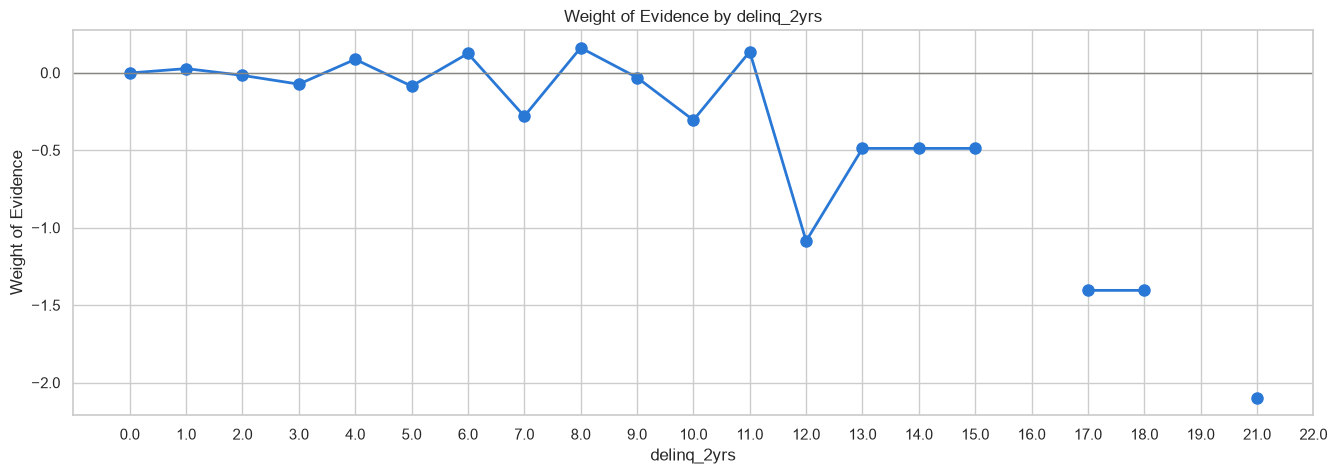

In [42]:
woe_df = woe_table(loan_data_inputs_train['delinq_2yrs'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** flat. Borrowers with 0, 1, 2 or 3 past late payments are all about 88% to 89% good; larger values are tiny groups that jump around. IV of the final categories ≈ 0.

**Why is past behaviour not predictive here?** Our data only contains **approved** loans. A borrower with several recent late payments was usually approved only if they were strong in other ways (high income, low debt), so among approved borrowers the late payments no longer separate good from bad. This is called **selection bias**: the data has been filtered by an earlier decision.

**Decision:** categories `0`, `1-3`, `>=4`. Expect it to be dropped in Part 7.

In [43]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['delinq_2yrs:0'] = np.where(df['delinq_2yrs'] == 0, 1, 0)
    df['delinq_2yrs:1-3'] = np.where((df['delinq_2yrs'] >= 1) & (df['delinq_2yrs'] <= 3), 1, 0)
    df['delinq_2yrs:>=4'] = np.where(df['delinq_2yrs'] >= 4, 1, 0)

#### `inq_last_6mths`: credit enquiries in the last 6 months

,inq_last_6mths,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0.0,193232,175531,17701,0.908395,0.518009,0.528310,0.434082,0.196450,NaN,NaN,inf
1,1.0,104163,92179,11984,0.884950,0.279236,0.277439,0.293884,-0.057585,0.023446,0.254035,inf
2,2.0,46214,39938,6276,0.864197,0.123889,0.120205,0.153907,-0.247150,0.020753,0.189564,inf
3,3.0,20040,16827,3213,0.839671,0.053723,0.050646,0.078792,-0.441965,0.024526,0.194816,inf
4,4.0,5810,4929,881,0.848365,0.015575,0.014835,0.021605,-0.375911,0.008694,0.066054,inf
5,5.0,2217,1829,388,0.824989,0.005943,0.005505,0.009515,-0.547226,0.023376,0.171314,inf
6,6.0,977,770,207,0.788127,0.002619,0.002318,0.005076,-0.784073,0.036862,0.236848,inf
7,7.0,159,108,51,0.679245,0.000426,0.000325,0.001251,-1.347439,0.108882,0.563366,inf
8,8.0,101,65,36,0.643564,0.000271,0.000196,0.000883,-1.506877,0.035681,0.159437,inf
9,9.0,43,29,14,0.674419,0.000115,0.000087,0.000343,-1.369506,0.030854,0.137370,inf


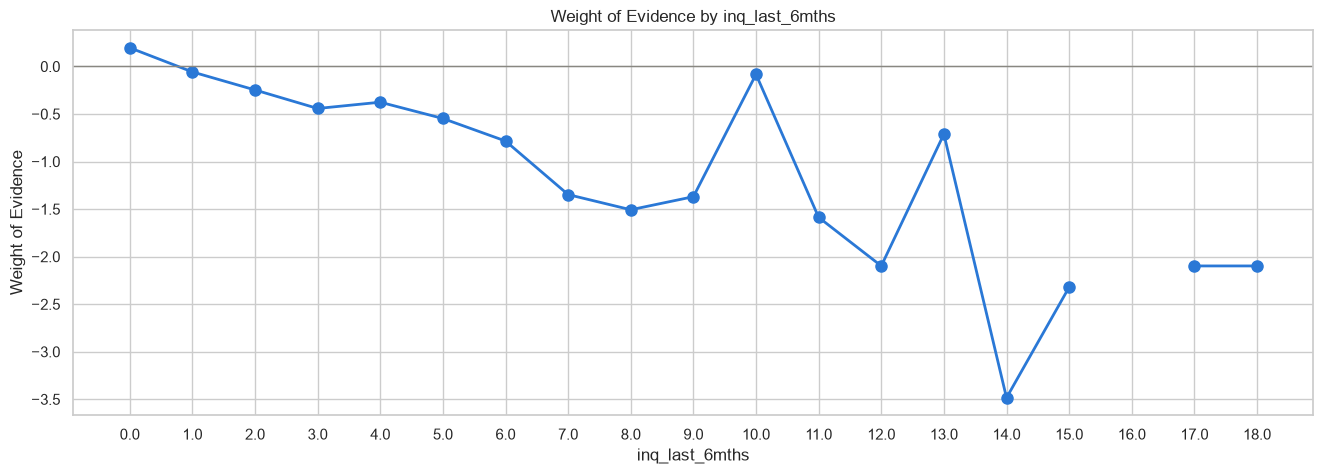

In [44]:
woe_df = woe_table(loan_data_inputs_train['inq_last_6mths'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** a clear pattern. With 0 enquiries 90.8% of loans are good, with 1 88.5%, 2 86.4%, 3 84.0%, and with 6 only 78.8%. Many recent applications for credit can mean the borrower urgently needs money ("credit hungry"). IV of the final categories ≈ 0.05.

**Decision:** categories `0`, `1-2`, `3-6`, `>6` (reference category: the riskiest).

In [45]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['inq_last_6mths:0'] = np.where(df['inq_last_6mths'] == 0, 1, 0)
    df['inq_last_6mths:1-2'] = np.where((df['inq_last_6mths'] >= 1) & (df['inq_last_6mths'] <= 2), 1, 0)
    df['inq_last_6mths:3-6'] = np.where((df['inq_last_6mths'] >= 3) & (df['inq_last_6mths'] <= 6), 1, 0)
    df['inq_last_6mths:>6'] = np.where(df['inq_last_6mths'] >= 7, 1, 0)

#### `open_acc`: number of open credit accounts

,open_acc,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0.0,29,22,7,0.758621,0.000078,0.000066,0.000172,-0.952613,NaN,NaN,inf
1,1.0,110,96,14,0.872727,0.000295,0.000289,0.000343,-0.172454,0.114107,0.780159,inf
2,2.0,1456,1231,225,0.845467,0.003903,0.003705,0.005518,-0.398263,0.027260,0.225809,inf
3,3.0,4378,3825,553,0.873687,0.011736,0.011512,0.013561,-0.163789,0.028220,0.234474,inf
4,4.0,10028,8940,1088,0.891504,0.026883,0.026907,0.026681,0.008449,0.017817,0.172239,inf
5,5.0,17141,15277,1864,0.891255,0.045951,0.045980,0.045711,0.005879,0.000249,0.002571,inf
6,6.0,24621,21971,2650,0.892368,0.066003,0.066128,0.064986,0.017419,0.001113,0.011540,inf
7,7.0,30169,26897,3272,0.891544,0.080876,0.080954,0.080239,0.008868,0.000824,0.008550,inf
8,8.0,33579,29920,3659,0.891033,0.090017,0.090053,0.089730,0.003592,0.000511,0.005276,inf
9,9.0,35251,31345,3906,0.889195,0.094500,0.094342,0.095787,-0.015204,0.001838,0.018796,inf


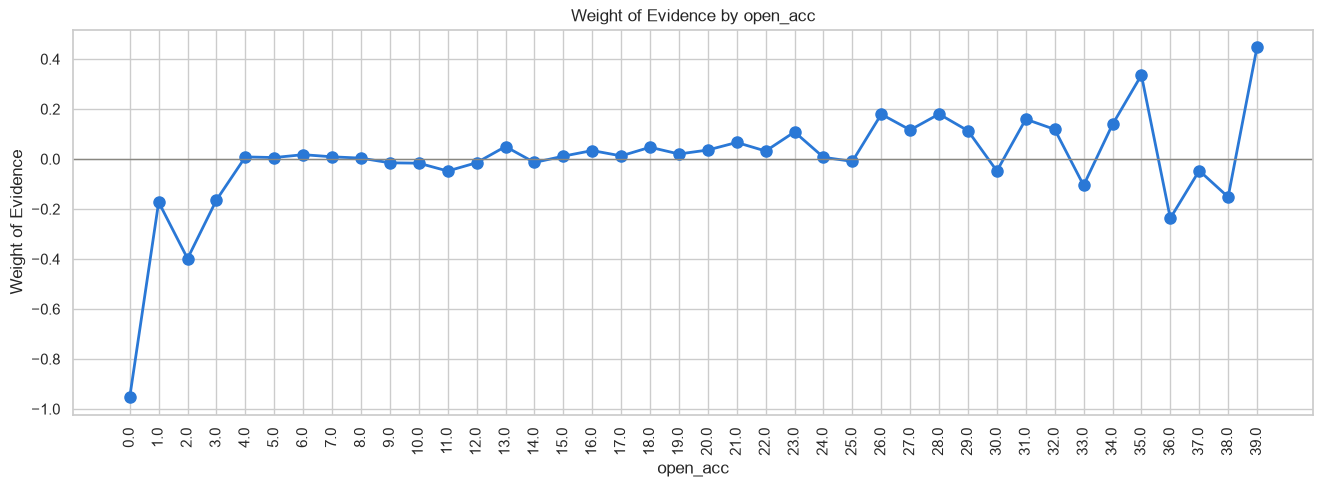

In [46]:
woe_df = woe_table(loan_data_inputs_train['open_acc'], loan_data_targets_train)
display(woe_df)
# only the first 40 values: higher numbers of accounts are very rare and make the chart unreadable
plot_by_woe(woe_df.iloc[:40, :], 90)

**What we see:** flat at about 89% good, apart from very small groups with 0 to 3 accounts. IV of the final categories ≈ 0.001.

**Decision:** categories `0`, `1-3`, `4-12`, `13-17`, `18-22`, `23-25`, `26-30`, `>=31`. Expect it to be dropped in Part 7.

In [47]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['open_acc:0'] = np.where(df['open_acc'] == 0, 1, 0)
    df['open_acc:1-3'] = np.where((df['open_acc'] >= 1) & (df['open_acc'] <= 3), 1, 0)
    df['open_acc:4-12'] = np.where((df['open_acc'] >= 4) & (df['open_acc'] <= 12), 1, 0)
    df['open_acc:13-17'] = np.where((df['open_acc'] >= 13) & (df['open_acc'] <= 17), 1, 0)
    df['open_acc:18-22'] = np.where((df['open_acc'] >= 18) & (df['open_acc'] <= 22), 1, 0)
    df['open_acc:23-25'] = np.where((df['open_acc'] >= 23) & (df['open_acc'] <= 25), 1, 0)
    df['open_acc:26-30'] = np.where((df['open_acc'] >= 26) & (df['open_acc'] <= 30), 1, 0)
    df['open_acc:>=31'] = np.where(df['open_acc'] >= 31, 1, 0)

#### `pub_rec`: number of negative public records (bankruptcies, tax liens, ...)

,pub_rec,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0.0,323999,288340,35659,0.889941,0.868565,0.867840,0.874467,-0.007606,NaN,NaN,inf
1,1.0,42381,37864,4517,0.893419,0.113613,0.113962,0.110771,0.028408,0.003478,0.036014,inf
2,2.0,4527,4089,438,0.903247,0.012136,0.012307,0.010741,0.136092,0.009828,0.107684,inf
3,3.0,1280,1178,102,0.920312,0.003431,0.003546,0.002501,0.348856,0.017065,0.212764,inf
4,4.0,408,377,31,0.924020,0.001094,0.001135,0.000760,0.400513,0.003707,0.051657,inf
5,5.0,203,185,18,0.911330,0.000544,0.000557,0.000441,0.232239,0.012690,0.168274,inf
6,6.0,117,109,8,0.931624,0.000314,0.000328,0.000196,0.514161,0.020294,0.281922,inf
7,7.0,48,46,2,0.958333,0.000129,0.000138,0.000049,1.037749,0.026709,0.523588,inf
8,8.0,24,24,0,1.000000,0.000064,0.000072,0.000000,inf,0.041667,inf,inf
9,9.0,14,11,3,0.785714,0.000038,0.000033,0.000074,-0.798462,0.214286,inf,inf


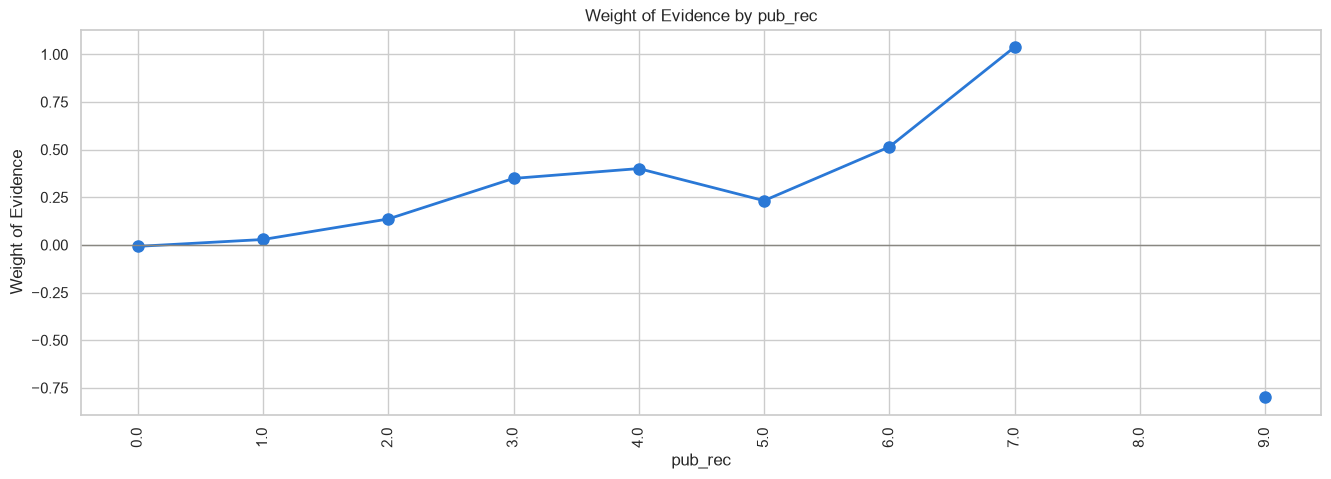

In [48]:
woe_df = woe_table(loan_data_inputs_train['pub_rec'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** flat, and borrowers with more records are, if anything, slightly *safer*. This is selection bias again: approved borrowers with records had to be strong in other ways. IV of the final categories ≈ 0.001.

**Decision:** categories `0-2`, `3-4`, `>=5`. Expect it to be dropped in Part 7.

In [49]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['pub_rec:0-2'] = np.where(df['pub_rec'] <= 2, 1, 0)
    df['pub_rec:3-4'] = np.where((df['pub_rec'] >= 3) & (df['pub_rec'] <= 4), 1, 0)
    df['pub_rec:>=5'] = np.where(df['pub_rec'] >= 5, 1, 0)

#### `total_acc`: total number of credit accounts ever

,total_acc,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-0.15, 3.0]",459,372,87,0.810458,0.001230,0.001120,0.002134,-0.644759,NaN,NaN,inf
1,"(3.0, 6.0]",6004,5192,812,0.864757,0.016095,0.015627,0.019913,-0.242371,0.054299,0.402388,inf
2,"(6.0, 9.0]",15047,13138,1909,0.873131,0.040337,0.039543,0.046814,-0.168816,0.008374,0.073555,inf
3,"(9.0, 12.0]",25169,22181,2988,0.881283,0.067472,0.066760,0.073275,-0.093113,0.008152,0.075703,inf
4,"(12.0, 15.0]",33651,29656,3995,0.881281,0.090210,0.089258,0.097969,-0.093124,0.000001,0.000011,inf
5,"(15.0, 18.0]",38711,34347,4364,0.887267,0.103775,0.103377,0.107018,-0.034619,0.005986,0.058505,inf
6,"(18.0, 21.0]",40599,35977,4622,0.886155,0.108836,0.108283,0.113345,-0.045693,0.001112,0.011073,inf
7,"(21.0, 24.0]",40163,35805,4358,0.891492,0.107668,0.107765,0.106871,0.008329,0.005337,0.054022,inf
8,"(24.0, 27.0]",36286,32492,3794,0.895442,0.097274,0.097794,0.093040,0.049828,0.003950,0.041499,inf
9,"(27.0, 30.0]",31775,28569,3206,0.899103,0.085181,0.085986,0.078621,0.089553,0.003661,0.039725,inf


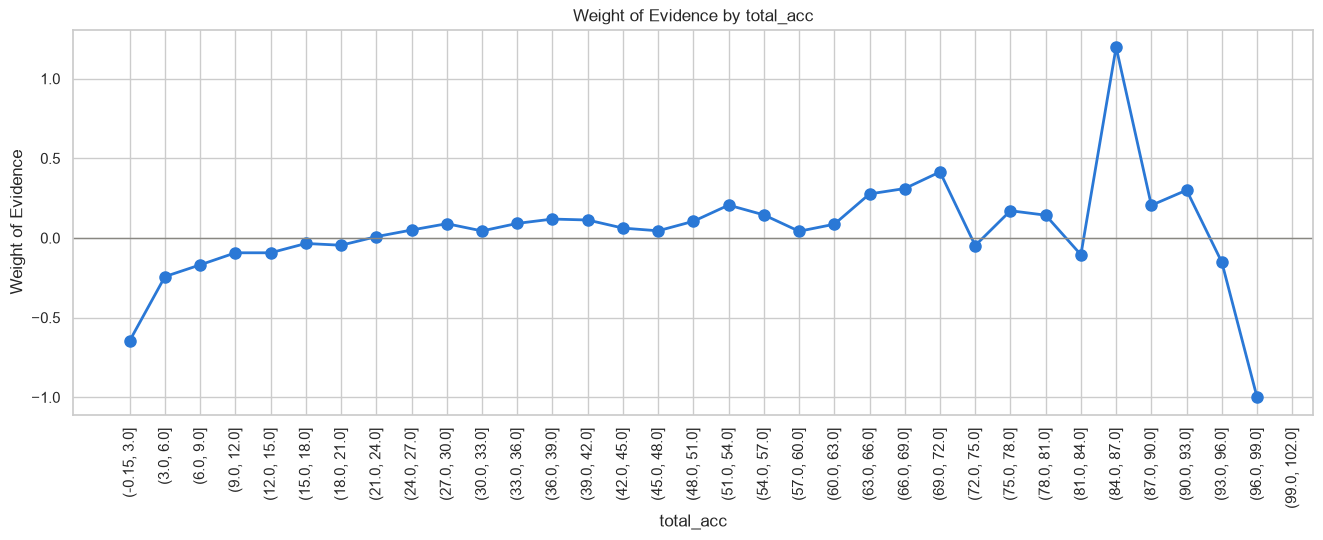

In [50]:
woe_df = woe_table(pd.cut(loan_data_inputs_train['total_acc'], 50), loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** a gentle rise. Borrowers with very few accounts (up to 3) are 81% good; those with many are about 90% good. IV of the final categories ≈ 0.004 (useless).

**Decision:** categories `<=27`, `28-51`, `>=52`. Expect it to be dropped in Part 7.

In [51]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['total_acc:<=27'] = np.where(df['total_acc'] <= 27, 1, 0)
    df['total_acc:28-51'] = np.where((df['total_acc'] >= 28) & (df['total_acc'] <= 51), 1, 0)
    df['total_acc:>=52'] = np.where(df['total_acc'] >= 52, 1, 0)

#### `acc_now_delinq`: accounts on which the borrower is late right now

,acc_now_delinq,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,0.0,371682,331038,40644,0.890648,0.996392,0.996352,0.996714,-0.000363,NaN,NaN,inf
1,1.0,1263,1136,127,0.899446,0.003386,0.003419,0.003114,0.093337,0.008797,0.093700,inf
2,2.0,70,65,5,0.928571,0.000188,0.000196,0.000123,0.467204,0.029126,0.373868,inf
3,3.0,7,6,1,0.857143,0.000019,0.000018,0.000025,-0.305986,0.071429,0.773190,inf
4,4.0,4,4,0,1.000000,0.000011,0.000012,0.000000,inf,0.142857,inf,inf
5,5.0,2,1,1,0.500000,0.000005,0.000003,0.000025,-2.097745,0.500000,inf,inf


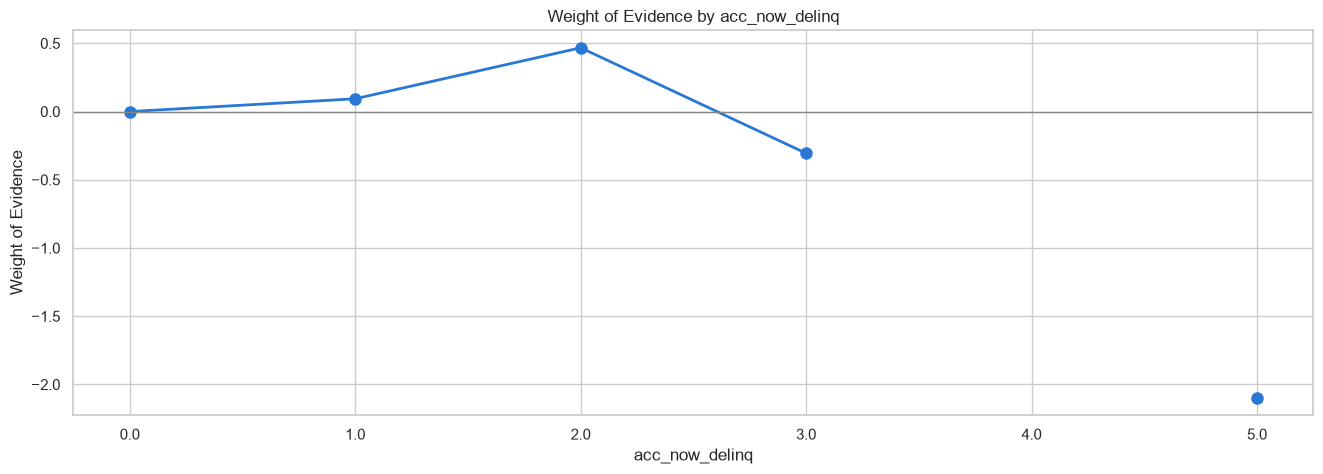

In [52]:
woe_df = woe_table(loan_data_inputs_train['acc_now_delinq'], loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df)

**What we see:** 99.6% of borrowers have 0, and the groups with 1+ are small and noisy (one has WoE = `inf`). IV of the final categories ≈ 0.

**Decision:** categories `0` and `>=1`. Expect it to be dropped in Part 7.

In [53]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    df['acc_now_delinq:0'] = np.where(df['acc_now_delinq'] == 0, 1, 0)
    df['acc_now_delinq:>=1'] = np.where(df['acc_now_delinq'] >= 1, 1, 0)

#### `total_rev_hi_lim`: total credit limit on revolving accounts (credit cards etc.)
70,276 loans have no value here (Section 3.6). Before deciding how to fill them, let's ask **why** they are empty.

In [54]:
# share_missing_by_year = share of loans with an empty credit limit, for each year the loans were given
share_missing_by_year = (loan_data_inputs_train['total_rev_hi_lim'].isnull()
                         .groupby(loan_data_inputs_train['issue_d_date'].dt.year).mean())
display(share_missing_by_year.round(3).to_frame('share_missing'))

# is_missing = True for loans with an empty credit limit
is_missing = loan_data_inputs_train['total_rev_hi_lim'].isnull()
print('Bad rate when the credit limit is missing    :', round(1 - loan_data_targets_train[is_missing].mean(), 4))
print('Bad rate when the credit limit is not missing:', round(1 - loan_data_targets_train[~is_missing].mean(), 4))

,share_missing
issue_d_date,
2007,1.000
2008,1.000
2009,1.000
2010,1.000
2011,1.000
2012,0.521
2013,0.000
2014,0.000


Bad rate when the credit limit is missing    : 0.1555
Bad rate when the credit limit is not missing: 0.1011


**What we see:** the value is missing for **every** loan given in 2007-2011 and for about half of the 2012 loans; Lending Club simply did not collect it back then. So "missing" really means "an old loan", and old loans had much more time to go bad (bad rate ≈ 15.5% against ≈ 10.1%).

**Why that is a problem:** whatever we do with the empty values brings the loan-age trap (see `mths_since_issue_d` above) back in through the back door:
- a `Missing` category would simply mean "old loan";
- filling with a number puts the old, riskier loans into some categories. The first version of this notebook filled with the loan amount, and then more than half of the "up to $5K" category were filled-in old loans, making low limits look riskier than they really are.

Let's still look at the loans that do have a value. Some limits reach almost $10 million, so we zoom into limits up to $250,000 and cut them into 50 intervals of $5,000.

,total_rev_hi_lim,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-249.8, 4996.0]",10011,8793,1218,0.878334,0.031666,0.030945,0.038067,-0.207132,NaN,NaN,0.036633
1,"(4996.0, 9992.0]",36039,31874,4165,0.884431,0.113996,0.112175,0.130173,-0.148803,0.006097,0.058329,0.036633
2,"(9992.0, 14988.0]",46252,41015,5237,0.886772,0.146301,0.144345,0.163677,-0.125688,0.002342,0.023115,0.036633
3,"(14988.0, 19984.0]",43940,39018,4922,0.887984,0.138988,0.137317,0.153832,-0.113569,0.001211,0.012119,0.036633
4,"(19984.0, 24980.0]",36632,32768,3864,0.894518,0.115872,0.115321,0.120765,-0.046128,0.006535,0.067441,0.036633
5,"(24980.0, 29976.0]",29750,26639,3111,0.895429,0.094103,0.093751,0.097231,-0.036445,0.000910,0.009683,0.036633
6,"(29976.0, 34972.0]",23509,21134,2375,0.898975,0.074362,0.074377,0.074228,0.002008,0.003546,0.038454,0.036633
7,"(34972.0, 39968.0]",18614,16941,1673,0.910121,0.058879,0.059621,0.052288,0.131241,0.011147,0.129233,0.036633
8,"(39968.0, 44964.0]",14720,13461,1259,0.914470,0.046561,0.047374,0.039349,0.185602,0.004349,0.054361,0.036633
9,"(44964.0, 49960.0]",11580,10558,1022,0.911744,0.036629,0.037157,0.031941,0.151245,0.002726,0.034356,0.036633


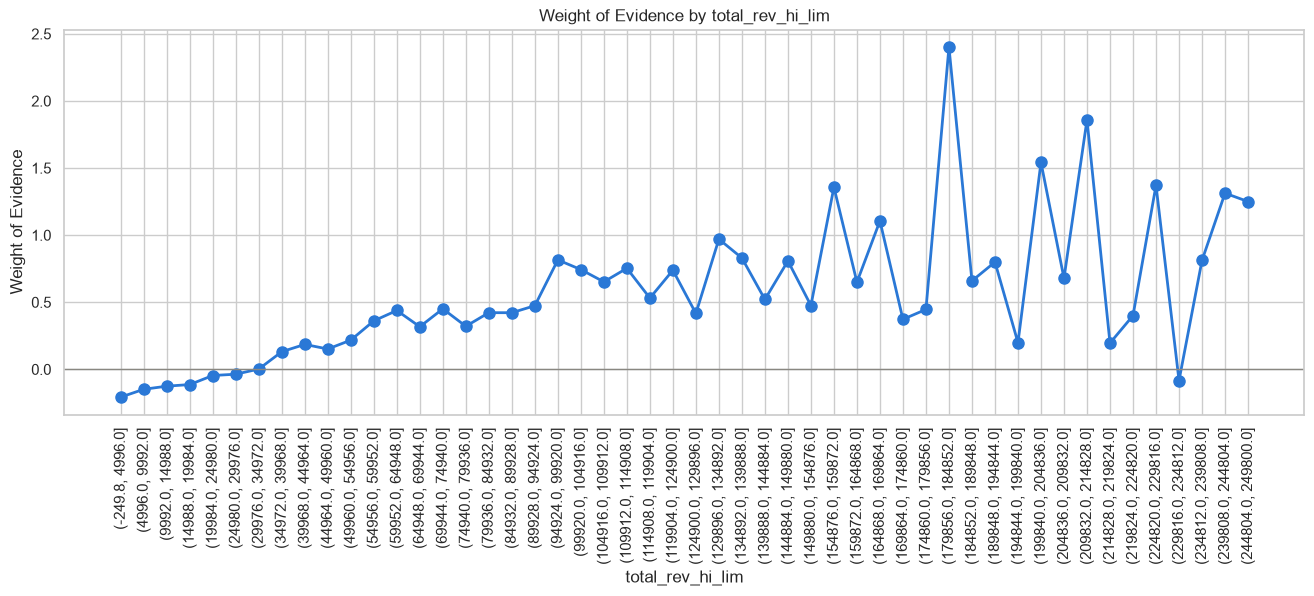

In [55]:
# has_limit_up_to_250k = True for loans that have a credit limit, and it is at most $250,000
has_limit_up_to_250k = loan_data_inputs_train['total_rev_hi_lim'] <= 250000    # empty values give False
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[has_limit_up_to_250k, 'total_rev_hi_lim'], 50),
                   loan_data_targets_train[has_limit_up_to_250k])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** among loans with a value, higher credit limits do go with safer borrowers (banks give high limits to people they already trust), but the signal is weak.

**Decision:** we do **not** use `total_rev_hi_lim` in our models. Its weak signal is not worth smuggling the loan-age effect back in. In a dataset where the limit is recorded for every loan, it would be a sensible variable.

**Common beginner mistake:** filling missing values without asking *why* they are missing. When the reason is linked to time or to the outcome, the filled-in values carry a hidden message, and the model will happily learn it.

#### `installment`: the monthly payment

,installment,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(14.276, 43.556]",1812,1642,170,0.906181,0.004858,0.004942,0.004169,0.170127,NaN,NaN,0.013497
1,"(43.556, 71.443]",4841,4345,496,0.897542,0.012978,0.013078,0.012163,0.072460,0.008639,0.097667,0.013497
2,"(71.443, 99.329]",6824,6094,730,0.893025,0.018294,0.018342,0.017902,0.024270,0.004517,0.048190,0.013497
3,"(99.329, 127.216]",9138,8136,1002,0.890348,0.024497,0.024488,0.024572,-0.003444,0.002677,0.027715,0.013497
4,"(127.216, 155.102]",10040,9001,1039,0.896514,0.026915,0.027091,0.025479,0.061332,0.006166,0.064776,0.013497
5,"(155.102, 182.988]",16816,15037,1779,0.894208,0.045080,0.045258,0.043626,0.036717,0.002306,0.024615,0.013497
6,"(182.988, 210.875]",17216,15577,1639,0.904798,0.046152,0.046883,0.040193,0.153964,0.010590,0.117247,0.013497
7,"(210.875, 238.761]",15090,13587,1503,0.900398,0.040453,0.040894,0.036858,0.103905,0.004400,0.050059,0.013497
8,"(238.761, 266.648]",18842,16984,1858,0.901391,0.050511,0.051118,0.045564,0.115026,0.000993,0.011121,0.013497
9,"(266.648, 294.534]",20100,17911,2189,0.891095,0.053883,0.053908,0.053681,0.004225,0.010296,0.110801,0.013497


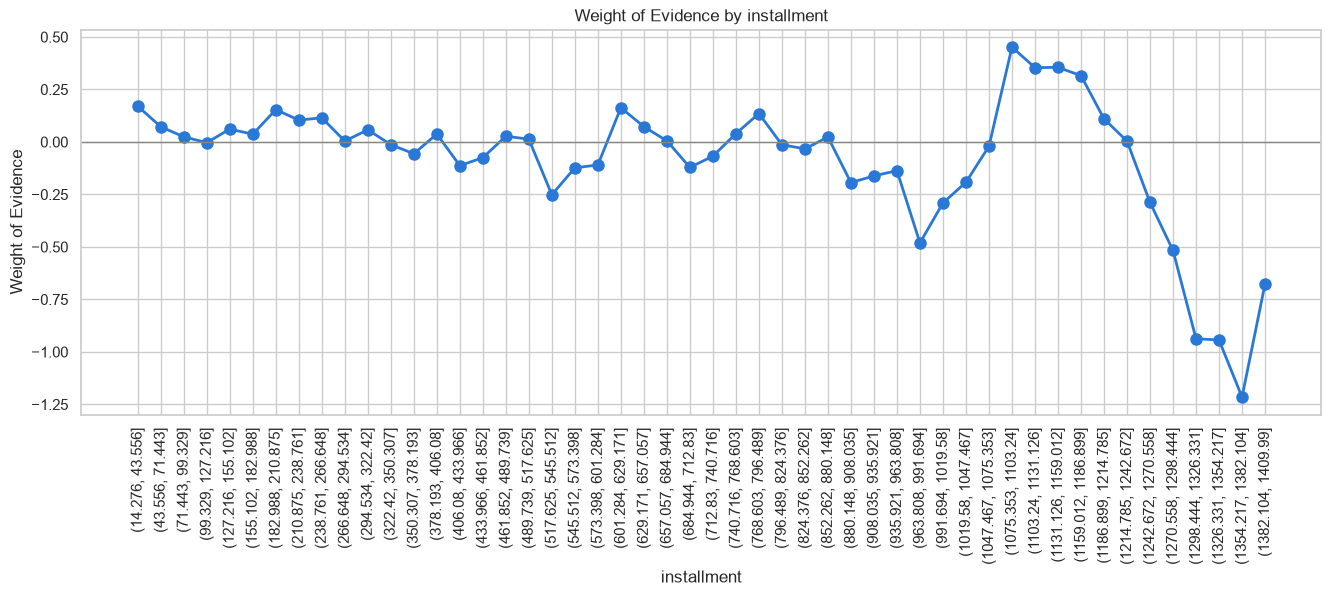

In [56]:
woe_df = woe_table(pd.cut(loan_data_inputs_train['installment'], 50), loan_data_targets_train)
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** a weak, noisy pattern.

**Decision:** not used. The monthly payment is almost completely determined by the amount, the interest rate and the term (we already use `int_rate` and `term`), so it would repeat information the model already has.

**Common beginner mistake:** adding variables that are just combinations of other variables. They add no new information and make the model's coefficients unstable (this is called **multicollinearity**).

#### `annual_inc`: yearly income

In [57]:
woe_df = woe_table(pd.cut(loan_data_inputs_train['annual_inc'], 50), loan_data_targets_train)
display(woe_df.head(10))

,annual_inc,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-5243.882, 144693.64]",351904,312690,39214,0.888566,0.943372,0.941129,0.961646,-0.021567,NaN,NaN,inf
1,"(144693.64, 287491.28]",19004,17587,1417,0.925437,0.050945,0.052933,0.034749,0.420873,0.036871,0.442440,inf
2,"(287491.28, 430288.92]",1525,1419,106,0.930492,0.004088,0.004271,0.002599,0.496524,0.005055,0.075651,inf
3,"(430288.92, 573086.56]",332,312,20,0.939759,0.000890,0.000939,0.000490,0.649526,0.009267,0.153002,inf
4,"(573086.56, 715884.2]",112,99,13,0.883929,0.000300,0.000298,0.000319,-0.067574,0.055830,0.717100,inf
5,"(715884.2, 858681.84]",65,58,7,0.892308,0.000174,0.000175,0.000172,0.016788,0.008379,0.084362,inf
6,"(858681.84, 1001479.48]",39,38,1,0.974359,0.000105,0.000114,0.000025,1.539841,0.082051,1.523053,inf
7,"(1001479.48, 1144277.12]",10,10,0,1.000000,0.000027,0.000030,0.000000,inf,0.025641,inf,inf
8,"(1144277.12, 1287074.76]",12,12,0,1.000000,0.000032,0.000036,0.000000,inf,0.000000,NaN,inf
9,"(1287074.76, 1429872.4]",6,6,0,1.000000,0.000016,0.000018,0.000000,inf,0.000000,NaN,inf


**What we see:** the first interval alone holds about 94% of all loans. A handful of incomes in the millions stretch the scale so much that 50 equal intervals become useless. This is the outlier problem from Section 6.3.

**Fix:** zoom in on incomes up to $140,000 and put all higher incomes into one category.

,annual_inc,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(1757.896, 4658.08]",15,12,3,0.800000,0.000043,0.000038,0.000077,-0.689458,NaN,NaN,0.049818
1,"(4658.08, 7420.16]",40,30,10,0.750000,0.000114,0.000096,0.000256,-0.977140,0.050000,0.287682,0.049818
2,"(7420.16, 10182.24]",287,251,36,0.874564,0.000818,0.000805,0.000920,-0.133818,0.124564,0.843322,0.049818
3,"(10182.24, 12944.32]",547,453,94,0.828154,0.001558,0.001452,0.002402,-0.503155,0.046411,0.369337,0.049818
4,"(12944.32, 15706.4]",1210,1005,205,0.830579,0.003447,0.003222,0.005238,-0.486019,0.002425,0.017135,0.049818
5,"(15706.4, 18468.48]",1522,1290,232,0.847569,0.004335,0.004136,0.005928,-0.360092,0.016990,0.125927,0.049818
6,"(18468.48, 21230.56]",2928,2505,423,0.855533,0.008340,0.008031,0.010809,-0.297080,0.007964,0.063012,0.049818
7,"(21230.56, 23992.64]",2495,2107,388,0.844489,0.007107,0.006755,0.009914,-0.383737,0.011044,0.086657,0.049818
8,"(23992.64, 26754.72]",7016,5954,1062,0.848632,0.019985,0.019088,0.027137,-0.351843,0.004143,0.031894,0.049818
9,"(26754.72, 29516.8]",5643,4838,805,0.857345,0.016074,0.015510,0.020570,-0.282338,0.008714,0.069505,0.049818


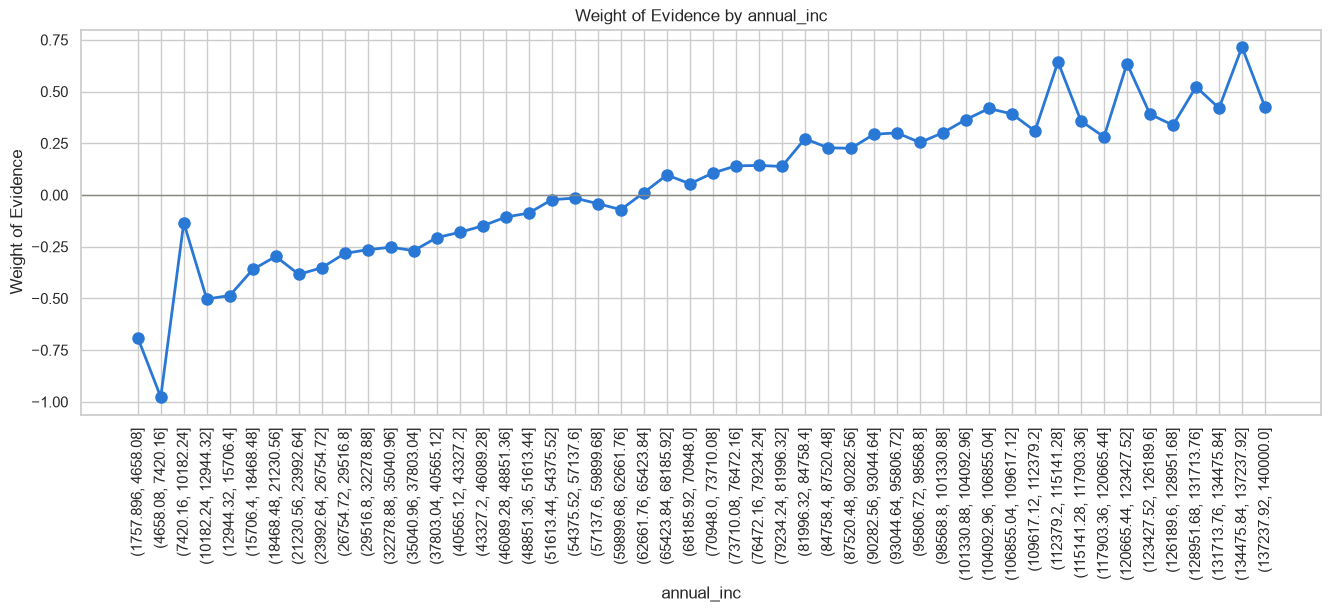

In [58]:
# up_to_140k = True for borrowers with a yearly income of at most $140,000
up_to_140k = loan_data_inputs_train['annual_inc'] <= 140000
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[up_to_140k, 'annual_inc'], 50),
                   loan_data_targets_train[up_to_140k])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** the higher the income, the safer the loan, with a fairly steady rise. IV ≈ 0.05.

**Decision:** 12 categories: `<=20K` (reference category), then steps of $10,000 up to `90K-100K`, then `100K-120K`, `120K-140K`, and `>140K` for all higher incomes (they are few).

In [59]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    income = df['annual_inc']
    df['annual_inc:<=20K'] = np.where(income <= 20000, 1, 0)
    df['annual_inc:20K-30K'] = np.where((income > 20000) & (income <= 30000), 1, 0)
    df['annual_inc:30K-40K'] = np.where((income > 30000) & (income <= 40000), 1, 0)
    df['annual_inc:40K-50K'] = np.where((income > 40000) & (income <= 50000), 1, 0)
    df['annual_inc:50K-60K'] = np.where((income > 50000) & (income <= 60000), 1, 0)
    df['annual_inc:60K-70K'] = np.where((income > 60000) & (income <= 70000), 1, 0)
    df['annual_inc:70K-80K'] = np.where((income > 70000) & (income <= 80000), 1, 0)
    df['annual_inc:80K-90K'] = np.where((income > 80000) & (income <= 90000), 1, 0)
    df['annual_inc:90K-100K'] = np.where((income > 90000) & (income <= 100000), 1, 0)
    df['annual_inc:100K-120K'] = np.where((income > 100000) & (income <= 120000), 1, 0)
    df['annual_inc:120K-140K'] = np.where((income > 120000) & (income <= 140000), 1, 0)
    df['annual_inc:>140K'] = np.where(income > 140000, 1, 0)

#### `mths_since_last_delinq`: months since the last late payment (empty = never late)
An empty value means "never late", which is valuable information, so it gets its own category `Missing`. We look at the WoE of the borrowers who **do** have a value.

Share of training loans with no late payment ever (empty value): 0.537


,mths_since_last_delinq,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-0.188, 3.76]",5277,4599,678,0.871518,0.030531,0.029814,0.036481,-0.201825,NaN,NaN,inf
1,"(3.76, 7.52]",11167,9912,1255,0.887615,0.064608,0.064256,0.067528,-0.049661,0.016097,0.152164,inf
2,"(7.52, 11.28]",13306,11880,1426,0.892830,0.076983,0.077014,0.076729,0.003711,0.005215,0.053372,inf
3,"(11.28, 15.04]",13216,11747,1469,0.888847,0.076462,0.076152,0.079042,-0.037256,0.003983,0.040967,inf
4,"(15.04, 18.8]",9337,8356,981,0.894934,0.054020,0.054169,0.052785,0.025891,0.006087,0.063147,inf
5,"(18.8, 22.56]",11641,10392,1249,0.892707,0.067350,0.067368,0.067205,0.002421,0.002227,0.023470,inf
6,"(22.56, 26.32]",10887,9758,1129,0.896298,0.062988,0.063258,0.060748,0.040483,0.003592,0.038062,inf
7,"(26.32, 30.08]",10560,9452,1108,0.895076,0.061096,0.061274,0.059618,0.027398,0.001223,0.013085,inf
8,"(30.08, 33.84]",7576,6835,741,0.902191,0.043832,0.044309,0.039871,0.105539,0.007115,0.078141,inf
9,"(33.84, 37.6]",9795,8790,1005,0.897397,0.056670,0.056982,0.054076,0.052355,0.004794,0.053184,inf


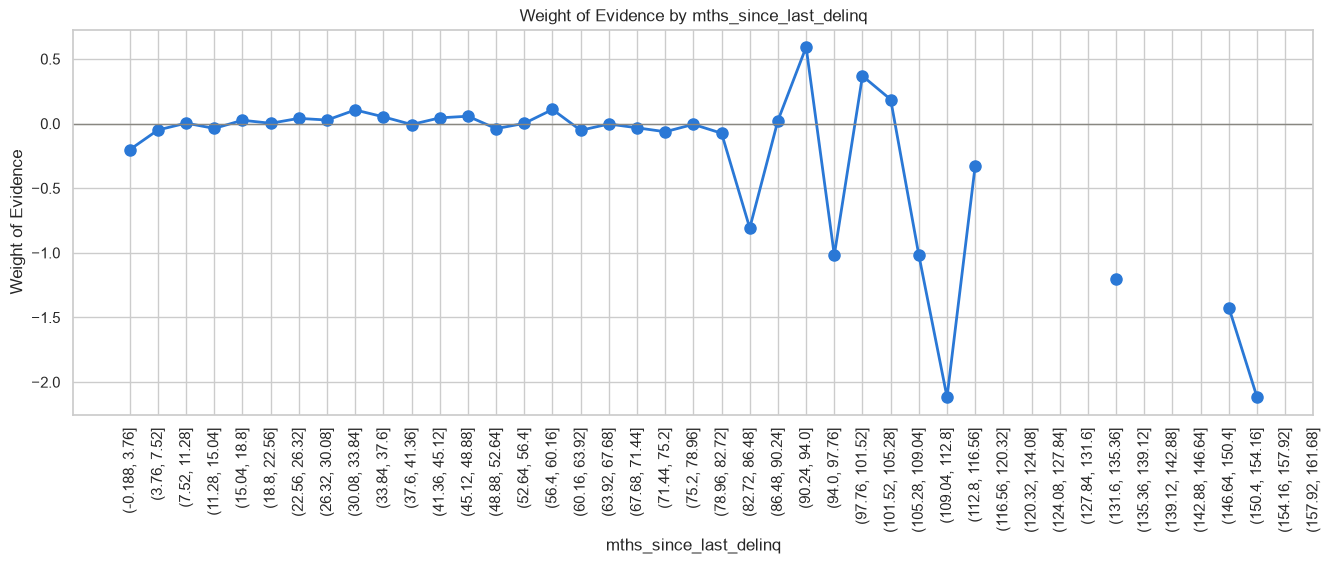

In [60]:
print('Share of training loans with no late payment ever (empty value):',
      round(loan_data_inputs_train['mths_since_last_delinq'].isnull().mean(), 3))

# has_value = True where the borrower was late at least once (the value is not empty)
has_value = loan_data_inputs_train['mths_since_last_delinq'].notnull()
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[has_value, 'mths_since_last_delinq'], 50),
                   loan_data_targets_train[has_value])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** mostly flat at about 89% good. Only a very recent late payment (0-3 months ago) is a bit riskier. IV of the final categories ≈ 0.001.

**Decision:** categories `Missing`, `0-3` (reference category), `4-30`, `31-56`, `>=57`. Expect it to be dropped in Part 7.

**Common beginner mistake:** filling these empty values with 0. That would turn "never late" into "late this month", the opposite meaning.

In [61]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    months = df['mths_since_last_delinq']
    df['mths_since_last_delinq:Missing'] = np.where(months.isnull(), 1, 0)
    df['mths_since_last_delinq:0-3'] = np.where((months >= 0) & (months <= 3), 1, 0)
    df['mths_since_last_delinq:4-30'] = np.where((months >= 4) & (months <= 30), 1, 0)
    df['mths_since_last_delinq:31-56'] = np.where((months >= 31) & (months <= 56), 1, 0)
    df['mths_since_last_delinq:>=57'] = np.where(months >= 57, 1, 0)

#### `dti`: debt-to-income ratio (monthly debt payments ÷ monthly income, in %)

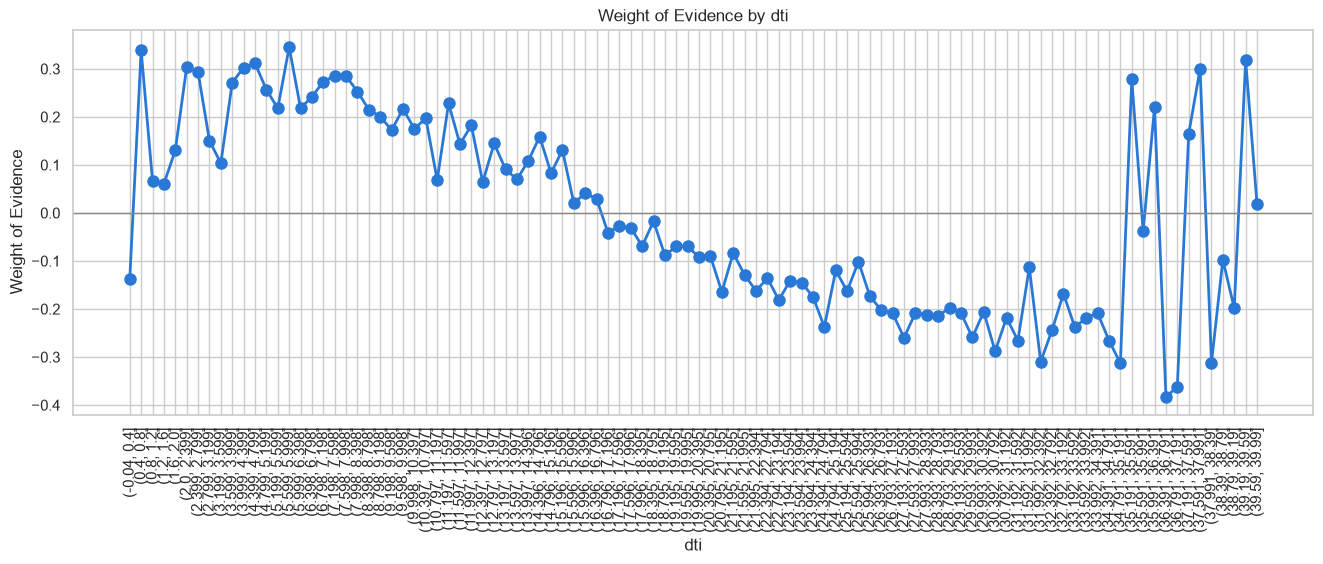

Share of loans with dti above 35: 0.0077


In [62]:
# First look: 100 intervals over the full range
woe_df = woe_table(pd.cut(loan_data_inputs_train['dti'], 100), loan_data_targets_train)
plot_by_woe(woe_df, 90)
print('Share of loans with dti above 35:', round((loan_data_inputs_train['dti'] > 35).mean(), 4))

Very few loans (about 0.8%) have a `dti` above 35, so we zoom in on `dti` up to 35 and look at the loans above 35 separately afterwards.

,dti,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-0.035, 0.7]",1366,1222,144,0.894583,0.003690,0.003707,0.003560,0.040465,NaN,NaN,0.027289
1,"(0.7, 1.4]",1664,1486,178,0.893029,0.004496,0.004507,0.004400,0.024094,0.001554,0.016371,0.027289
2,"(1.4, 2.1]",1986,1813,173,0.912890,0.005365,0.005499,0.004276,0.251481,0.019861,0.227387,0.027289
3,"(2.1, 2.8]",2594,2369,225,0.913261,0.007008,0.007186,0.005562,0.256157,0.000371,0.004676,0.027289
4,"(2.8, 3.5]",3135,2831,304,0.903030,0.008470,0.008587,0.007515,0.133392,0.010231,0.122765,0.027289
5,"(3.5, 4.2]",3844,3520,324,0.915713,0.010385,0.010677,0.008009,0.287507,0.012682,0.154115,0.027289
6,"(4.2, 4.9]",4595,4200,395,0.914037,0.012414,0.012739,0.009764,0.265988,0.001676,0.021519,0.027289
7,"(4.9, 5.6]",5312,4848,464,0.912651,0.014351,0.014705,0.011470,0.248471,0.001386,0.017517,0.027289
8,"(5.6, 6.3]",5927,5422,505,0.914797,0.016013,0.016446,0.012483,0.275696,0.002146,0.027225,0.027289
9,"(6.3, 7.0]",6482,5909,573,0.911601,0.017512,0.017923,0.014164,0.235381,0.003195,0.040315,0.027289


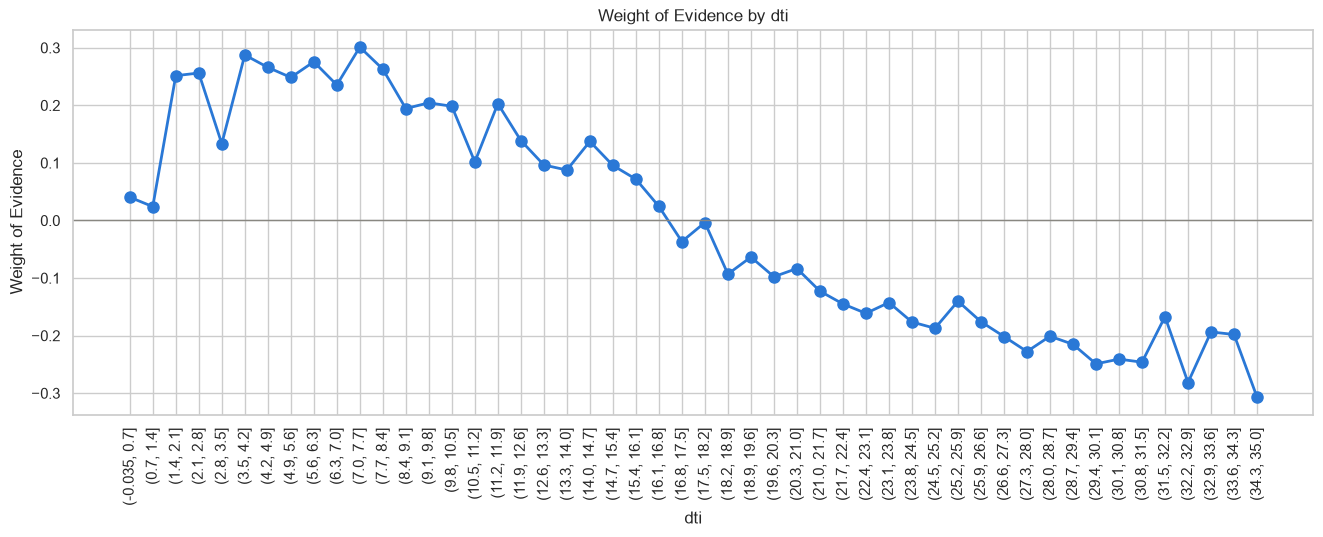

In [63]:
# up_to_35 = True for loans with a debt-to-income ratio of at most 35
up_to_35 = loan_data_inputs_train['dti'] <= 35
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[up_to_35, 'dti'], 50), loan_data_targets_train[up_to_35])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** the more of their income borrowers already spend on debt, the riskier the loan. The good share falls from about 91% at low `dti` to about 86% near 35.

But what about the 0.8% of loans **above 35**? Let's check *when* they were given:

In [64]:
# Year in which the loans with a dti above 35 were given
above_35 = loan_data_inputs_train['dti'] > 35
loan_data_inputs_train.loc[above_35, 'issue_d_date'].dt.year.value_counts()

issue_d_date
2014    2882
Name: count, dtype: int64

**What we see:** every single one is from 2014 (Lending Club only allowed a `dti` above 35 from then on), so they are young loans, most of them still running. Kept as a separate category, they would look *safe* just because they have not had time to default: the loan-age trap again.

**Decision:** eight categories, based on the original analysis with two changes:
- `>35` is merged into the riskiest group, giving `>22.4`;
- the two very narrow bands `20.3-21.7` and `21.7-22.4` (only 1.4 and 0.7 points wide, too narrow to be reliable) are merged into `20.3-22.4`.

Categories: `<=1.4`, `1.4-3.5`, `3.5-7.7`, `7.7-10.5`, `10.5-16.1`, `16.1-20.3`, `20.3-22.4`, `>22.4`. IV of the final categories ≈ 0.03.

In [65]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    dti = df['dti']
    df['dti:<=1.4'] = np.where(dti <= 1.4, 1, 0)
    df['dti:1.4-3.5'] = np.where((dti > 1.4) & (dti <= 3.5), 1, 0)
    df['dti:3.5-7.7'] = np.where((dti > 3.5) & (dti <= 7.7), 1, 0)
    df['dti:7.7-10.5'] = np.where((dti > 7.7) & (dti <= 10.5), 1, 0)
    df['dti:10.5-16.1'] = np.where((dti > 10.5) & (dti <= 16.1), 1, 0)
    df['dti:16.1-20.3'] = np.where((dti > 16.1) & (dti <= 20.3), 1, 0)
    df['dti:20.3-22.4'] = np.where((dti > 20.3) & (dti <= 22.4), 1, 0)
    df['dti:>22.4'] = np.where(dti > 22.4, 1, 0)

#### `mths_since_last_record`: months since the last negative public record (empty = none)

Share of training loans with no public record (empty value): 0.866


,mths_since_last_record,n_obs,n_good,n_bad,prop_good,prop_n_obs,prop_n_good,prop_n_bad,WoE,diff_prop_good,diff_WoE,IV
0,"(-0.121, 2.42]",1086,830,256,0.764273,0.021691,0.018569,0.047672,-0.942830,NaN,NaN,0.080659
1,"(2.42, 4.84]",76,68,8,0.894737,0.001518,0.001521,0.001490,0.020988,0.130464,0.963818,0.080659
2,"(4.84, 7.26]",163,149,14,0.914110,0.003256,0.003334,0.002607,0.245810,0.019374,0.224823,0.080659
3,"(7.26, 9.68]",156,141,15,0.903846,0.003116,0.003155,0.002793,0.121631,0.010264,0.124179,0.080659
4,"(9.68, 12.1]",292,265,27,0.907534,0.005832,0.005929,0.005028,0.164814,0.003688,0.043183,0.080659
5,"(12.1, 14.52]",207,190,17,0.917874,0.004134,0.004251,0.003166,0.294732,0.010340,0.129918,0.080659
6,"(14.52, 16.94]",210,195,15,0.928571,0.004194,0.004363,0.002793,0.445871,0.010697,0.151139,0.080659
7,"(16.94, 19.36]",334,303,31,0.907186,0.006671,0.006779,0.005773,0.160667,0.021386,0.285204,0.080659
8,"(19.36, 21.78]",283,265,18,0.936396,0.005652,0.005929,0.003352,0.570280,0.029210,0.409612,0.080659
9,"(21.78, 24.2]",455,409,46,0.898901,0.009088,0.009151,0.008566,0.065995,0.037495,0.504284,0.080659


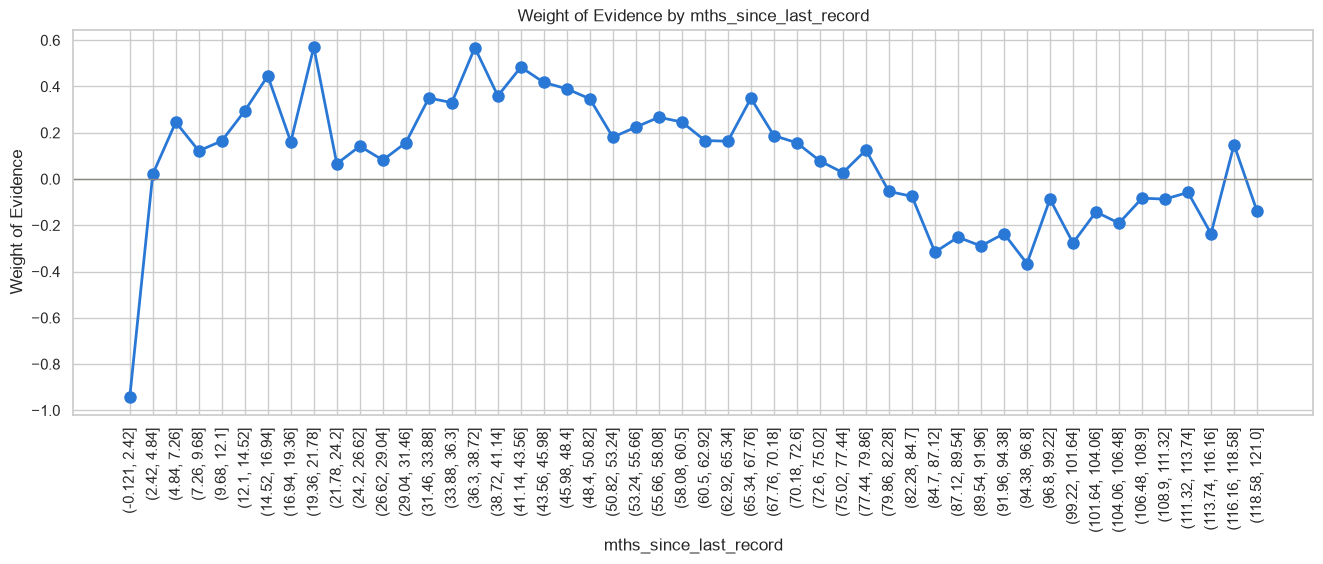

In [66]:
print('Share of training loans with no public record (empty value):',
      round(loan_data_inputs_train['mths_since_last_record'].isnull().mean(), 3))

has_value = loan_data_inputs_train['mths_since_last_record'].notnull()
woe_df = woe_table(pd.cut(loan_data_inputs_train.loc[has_value, 'mths_since_last_record'], 50),
                   loan_data_targets_train[has_value])
display(woe_df)
plot_by_woe(woe_df, 90)

**What we see:** a public record in the last 0-2 months is a strong warning sign (only about 76% of those loans are good); after that the good share is mostly between 85% and 94%. Among the 13% of borrowers who have a record, the IV is about 0.08; but over **all** loans, most of which are in `Missing`, the IV of the final categories is only ≈ 0.01.

**Decision:** categories `Missing`, `0-2` (reference category), `3-20`, `21-31`, `32-80`, `81-86`, `>86`. Expect it to be dropped in Part 7.

In [67]:
for df in [loan_data_inputs_train, loan_data_inputs_test]:
    months = df['mths_since_last_record']
    df['mths_since_last_record:Missing'] = np.where(months.isnull(), 1, 0)
    df['mths_since_last_record:0-2'] = np.where((months >= 0) & (months <= 2), 1, 0)
    df['mths_since_last_record:3-20'] = np.where((months >= 3) & (months <= 20), 1, 0)
    df['mths_since_last_record:21-31'] = np.where((months >= 21) & (months <= 31), 1, 0)
    df['mths_since_last_record:32-80'] = np.where((months >= 32) & (months <= 80), 1, 0)
    df['mths_since_last_record:81-86'] = np.where((months >= 81) & (months <= 86), 1, 0)
    df['mths_since_last_record:>86'] = np.where(months > 86, 1, 0)

## 7. PD model: choose the final variables and the reference categories

### 7.1 All candidate variables and their categories
`categories_by_variable` is a **dictionary**: for each candidate variable (the key) it stores the list of its final categories (the value). We use it to check the categories, to compute the IV of each variable, and to build the model inputs.

Not in the list: `mths_since_issue_d` (loan age, a trap), `total_rev_hi_lim` (its missing values smuggle loan age back in), and `funded_amnt` and `installment` (no useful pattern).

In [68]:
# categories_by_variable = candidate variable -> list of ALL its final categories (dummy columns)
categories_by_variable = {
    'grade': ['grade:A', 'grade:B', 'grade:C', 'grade:D', 'grade:E', 'grade:F', 'grade:G'],
    'home_ownership': ['home_ownership:RENT_OTHER_NONE_ANY', 'home_ownership:OWN', 'home_ownership:MORTGAGE'],
    'addr_state': ['addr_state:ND_NE_IA_NV_FL_HI_AL', 'addr_state:NM_VA', 'addr_state:NY',
                   'addr_state:OK_TN_MO_LA_MD_NC', 'addr_state:CA', 'addr_state:UT_KY_AZ_NJ',
                   'addr_state:AR_MI_PA_OH_MN', 'addr_state:RI_MA_DE_SD_IN', 'addr_state:GA_WA_OR',
                   'addr_state:WI_MT', 'addr_state:TX', 'addr_state:IL_CT',
                   'addr_state:KS_SC_CO_VT_AK_MS', 'addr_state:WV_NH_WY_DC_ME_ID'],
    'verification_status': ['verification_status:Not Verified', 'verification_status:Source Verified',
                            'verification_status:Verified'],
    'purpose': ['purpose:small_business__educational', 'purpose:moving__house__other__ren_energy__medical',
                'purpose:wedding__vacation__debt_consolidation', 'purpose:home_impr__major_purch__car',
                'purpose:credit_card'],
    'initial_list_status': ['initial_list_status:f', 'initial_list_status:w'],
    'term': ['term:36', 'term:60'],
    'emp_length': ['emp_length:0', 'emp_length:1', 'emp_length:2-4', 'emp_length:5-6', 'emp_length:7-9',
                   'emp_length:10'],
    'int_rate': ['int_rate:<=9.548', 'int_rate:9.548-12.025', 'int_rate:12.025-15.74', 'int_rate:15.74-20.281',
                 'int_rate:>20.281'],
    'mths_since_earliest_cr_line': ['mths_since_earliest_cr_line:<=72', 'mths_since_earliest_cr_line:73-96',
                                    'mths_since_earliest_cr_line:97-160', 'mths_since_earliest_cr_line:161-240',
                                    'mths_since_earliest_cr_line:241-300', 'mths_since_earliest_cr_line:>300'],
    'delinq_2yrs': ['delinq_2yrs:0', 'delinq_2yrs:1-3', 'delinq_2yrs:>=4'],
    'inq_last_6mths': ['inq_last_6mths:0', 'inq_last_6mths:1-2', 'inq_last_6mths:3-6', 'inq_last_6mths:>6'],
    'open_acc': ['open_acc:0', 'open_acc:1-3', 'open_acc:4-12', 'open_acc:13-17', 'open_acc:18-22',
                 'open_acc:23-25', 'open_acc:26-30', 'open_acc:>=31'],
    'pub_rec': ['pub_rec:0-2', 'pub_rec:3-4', 'pub_rec:>=5'],
    'total_acc': ['total_acc:<=27', 'total_acc:28-51', 'total_acc:>=52'],
    'acc_now_delinq': ['acc_now_delinq:0', 'acc_now_delinq:>=1'],
    'annual_inc': ['annual_inc:<=20K', 'annual_inc:20K-30K', 'annual_inc:30K-40K', 'annual_inc:40K-50K',
                   'annual_inc:50K-60K', 'annual_inc:60K-70K', 'annual_inc:70K-80K', 'annual_inc:80K-90K',
                   'annual_inc:90K-100K', 'annual_inc:100K-120K', 'annual_inc:120K-140K', 'annual_inc:>140K'],
    'mths_since_last_delinq': ['mths_since_last_delinq:Missing', 'mths_since_last_delinq:0-3',
                               'mths_since_last_delinq:4-30', 'mths_since_last_delinq:31-56',
                               'mths_since_last_delinq:>=57'],
    'dti': ['dti:<=1.4', 'dti:1.4-3.5', 'dti:3.5-7.7', 'dti:7.7-10.5', 'dti:10.5-16.1', 'dti:16.1-20.3',
            'dti:20.3-22.4', 'dti:>22.4'],
    'mths_since_last_record': ['mths_since_last_record:Missing', 'mths_since_last_record:0-2',
                               'mths_since_last_record:3-20', 'mths_since_last_record:21-31',
                               'mths_since_last_record:32-80', 'mths_since_last_record:81-86',
                               'mths_since_last_record:>86'],
}
print('Candidate variables:', len(categories_by_variable))

Candidate variables: 20


### 7.2 Safety check: is every loan in exactly one category?

For every variable, add up its dummy columns row by row. The result must be exactly **1** for every loan, in both the training and the test data:
- **0** means the loan fell into a gap between our ranges.
- **2** means two ranges overlap.

**If we skip it:** a gap or overlap goes unnoticed, and some loans get a wrong or missing category. The model will not complain; the results will just be quietly wrong.

In [69]:
# all_ok stays True only if every variable passes the check in both data sets
all_ok = True
for variable, columns in categories_by_variable.items():
    for data_name, df in [('training', loan_data_inputs_train), ('test', loan_data_inputs_test)]:
        categories_per_loan = df[columns].sum(axis=1)     # row by row: how many categories is the loan in?
        if not (categories_per_loan == 1).all():
            all_ok = False
            print('PROBLEM in', variable, '(' + data_name + ' data):', categories_per_loan.value_counts().to_dict())

print('Every loan is in exactly one category of every variable:', all_ok)

Every loan is in exactly one category of every variable: True


### 7.3 Information Value of every variable and its riskiest category

For each variable we rebuild one "category" column from its dummies, compute the WoE table again (now on the **final** categories) and read off:
- the **IV** of the variable, and
- its **riskiest category** (lowest WoE), which becomes its reference category (Section 7.4).

In [70]:
iv_rows = []                  # one small dictionary per variable, turned into a table at the end
reference_categories = {}     # variable -> its reference (riskiest) category

for variable, columns in categories_by_variable.items():
    # idxmax(axis=1) gives, for each loan, the NAME of the column that holds the 1 (e.g. 'grade:B')
    category_of_each_loan = loan_data_inputs_train[columns].idxmax(axis=1)
    category_of_each_loan.name = variable

    woe_df = woe_table(category_of_each_loan, loan_data_targets_train, sort_by_woe=True)

    reference_categories[variable] = woe_df.iloc[0, 0]    # first row after sorting = lowest WoE = riskiest
    iv_rows.append({'variable': variable,
                    'IV': woe_df['IV'].iloc[0],
                    'n_categories': len(columns),
                    'reference_category': woe_df.iloc[0, 0]})

# iv_summary = one row per variable, strongest first
iv_summary = pd.DataFrame(iv_rows).sort_values('IV', ascending=False).reset_index(drop=True)

# Translate the IV into words with the rule of thumb from Section 6.1
iv_summary['predictive_power'] = pd.cut(iv_summary['IV'],
                                        bins=[0, 0.02, 0.1, 0.3, 0.5, np.inf],
                                        labels=['useless', 'weak', 'medium', 'strong', 'suspicious'],
                                        right=False)
iv_summary

,variable,IV,n_categories,reference_category,predictive_power
0,int_rate,0.313602,5,int_rate:>20.281,strong
1,grade,0.288636,7,grade:G,medium
2,annual_inc,0.054766,12,annual_inc:<=20K,weak
3,inq_last_6mths,0.046685,4,inq_last_6mths:>6,weak
4,term,0.039434,2,term:60,weak
5,purpose,0.034998,5,purpose:small_business__educational,weak
6,mths_since_earliest_cr_line,0.028845,6,mths_since_earliest_cr_line:<=72,weak
7,dti,0.025436,8,dti:>22.4,weak
8,initial_list_status,0.024780,2,initial_list_status:f,weak
9,home_ownership,0.021221,3,home_ownership:RENT_OTHER_NONE_ANY,weak


**How to read the table:** `int_rate` (IV ≈ 0.31) and `grade` (≈ 0.29) are by far the strongest variables; about 9 variables are below 0.02 ("useless"). No variable is "suspicious" (> 0.5), so there are no signs of data leakage.

### 7.4 Why we leave one category out: the dummy variable trap

Take `term`: every loan has either `term:36 = 1` or `term:60 = 1`, so **term:36 + term:60 = 1 for every loan**. The model's intercept is also a column of 1s. If we give the model both dummies **and** the intercept, one column can be built exactly from the others (intercept = term:36 + term:60). The model then cannot decide how to split the effect between them. There are endless equally good answers, and the calculation fails (a "singular matrix" error) or gives nonsense. This is the **dummy variable trap**.

**Solution:** for every variable, leave **one** category out. This **reference category** becomes the baseline, and every other category's coefficient means "how much safer (or riskier) than the reference".

**Which category?** The **riskiest** one (lowest WoE). Then the coefficients mostly come out positive ("safer than the worst group"), and the scorecard is easy to read: the reference category gets 0 points and better categories get extra points.

**If we skip it:** the model cannot be estimated, or its coefficients are meaningless.

**Common beginner mistake:** dropping the reference category and then forgetting it exists. It is still a real category: in the scorecard (Part 10) it comes back with 0 points.

### 7.5 Keep only the useful variables

**What we do:** keep the variables with IV ≥ 0.02 and drop the "useless" ones.

**Why IV and not p-values?** With 373,000 loans, even a tiny, practically worthless effect becomes "statistically significant" (p < 0.05). IV measures how much a variable actually separates good from bad loans. We still check the p-values after fitting (Part 8).

**If we skip it:** useless variables add noise, make the scorecard longer and harder to explain, and can make the model less stable on new data.

**Common beginner mistake:** believing that more variables always means a better model. The 9 dropped variables would add 42 more dummy columns but almost no extra separating power.

In [71]:
# MIN_IV = the smallest Information Value a variable needs to enter the model (rule of thumb)
MIN_IV = 0.02

# selected_variables = variables we keep; dropped_variables = variables we leave out
selected_variables = iv_summary.loc[iv_summary['IV'] >= MIN_IV, 'variable'].tolist()
dropped_variables = iv_summary.loc[iv_summary['IV'] < MIN_IV, 'variable'].tolist()

print('Selected variables (' + str(len(selected_variables)) + '):', selected_variables)
print()
print('Dropped because IV < 0.02 (' + str(len(dropped_variables)) + '):', dropped_variables)

Selected variables (11): ['int_rate', 'grade', 'annual_inc', 'inq_last_6mths', 'term', 'purpose', 'mths_since_earliest_cr_line', 'dti', 'initial_list_status', 'home_ownership', 'verification_status']

Dropped because IV < 0.02 (9): ['addr_state', 'mths_since_last_record', 'emp_length', 'total_acc', 'open_acc', 'mths_since_last_delinq', 'pub_rec', 'acc_now_delinq', 'delinq_2yrs']


### 7.6 Build the model inputs

`features` = every category of the selected variables **except** each variable's reference category.

`sm.add_constant()` adds a column of 1s called `const`. Its coefficient is the **intercept**: the starting point of the model, i.e. the log-odds of being good for a borrower who sits in the reference (riskiest) category of every variable.

**Common beginner mistake:** forgetting the constant. `sm.Logit` and `sm.OLS` do **not** add an intercept by themselves (scikit-learn's models do). Without it, the model is forced through zero and the coefficients are wrong.

In [72]:
# features = the dummy columns that go into the model
features = []
for variable in selected_variables:
    for category in categories_by_variable[variable]:
        if category != reference_categories[variable]:     # leave the reference category out
            features.append(category)

print('Number of model inputs (dummy columns):', len(features))

# pd_inputs_train / pd_inputs_test = the PD model inputs + the 'const' column of 1s
#   .astype(float) -> statsmodels works with decimal numbers
pd_inputs_train = sm.add_constant(loan_data_inputs_train[features].astype(float))
pd_inputs_test = sm.add_constant(loan_data_inputs_test[features].astype(float))

pd_inputs_train.head()

Number of model inputs (dummy columns): 46


,const,int_rate:<=9.548,int_rate:9.548-12.025,int_rate:12.025-15.74,int_rate:15.74-20.281,grade:A,grade:B,grade:C,grade:D,grade:E,grade:F,annual_inc:20K-30K,annual_inc:30K-40K,annual_inc:40K-50K,annual_inc:50K-60K,annual_inc:60K-70K,annual_inc:70K-80K,annual_inc:80K-90K,annual_inc:90K-100K,annual_inc:100K-120K,annual_inc:120K-140K,annual_inc:>140K,inq_last_6mths:0,inq_last_6mths:1-2,inq_last_6mths:3-6,term:36,purpose:moving__house__other__ren_energy__medical,purpose:wedding__vacation__debt_consolidation,purpose:home_impr__major_purch__car,purpose:credit_card,mths_since_earliest_cr_line:73-96,mths_since_earliest_cr_line:97-160,mths_since_earliest_cr_line:161-240,mths_since_earliest_cr_line:241-300,mths_since_earliest_cr_line:>300,dti:<=1.4,dti:1.4-3.5,dti:3.5-7.7,dti:7.7-10.5,dti:10.5-16.1,dti:16.1-20.3,dti:20.3-22.4,initial_list_status:w,home_ownership:OWN,home_ownership:MORTGAGE,verification_status:Not Verified,verification_status:Source Verified
427211,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
206088,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
136020,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
412305,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36159,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 8. PD model: logistic regression

### 8.1 The idea in plain English
Logistic regression turns a list of yes/no facts about a borrower into a **probability**, in two steps:

1. **Add up:** start from the intercept and add the coefficient of every category the borrower belongs to:
   `z = intercept + coefficient(grade:B) + coefficient(term:36) + ...`
2. **Squeeze into 0 to 1:** convert the total with the S-shaped *logistic (sigmoid)* function:
   `P(good) = 1 / (1 + e^(-z))`.
   A large positive `z` gives a probability close to 1 (very likely good); a large negative `z` gives one close to 0.

**Odds** = P(good) / P(bad). Odds of 9 mean "9 good loans for every bad one" (90% good). `z` is the logarithm of the odds (the **log-odds**).

**How to read a coefficient:**
- positive → the category is **safer** than the variable's reference category
- negative → **riskier** than the reference category
- **odds ratio** = e^coefficient → by how many *times* the odds of being good change. An odds ratio of 2 means "twice the odds of being good compared with the reference category, everything else being equal".

**p-value:** if the category truly had no effect, how often would we see an effect at least this big just by chance? A p-value below 0.05 means "less than 5% of the time", and the effect is then called **statistically significant**. (It is *not* the probability that the effect is real.)

**Why logistic regression and not a fancier model?** It is transparent: every coefficient can be explained to a customer, a manager or a regulator, and it converts directly into a scorecard. Banks and regulators value this more than a small gain in accuracy.

**If we used ordinary (linear) regression instead:** it could predict "probabilities" below 0 or above 1, which make no sense.

**Common beginner mistakes:**
1. Reading a coefficient as a probability. A coefficient of 0.5 does **not** mean "+50% chance"; it changes the log-odds.
2. Forgetting that this model predicts **P(good)**: PD = 1 − P(good).
3. Reading a p-value above 0.05 as proof of "no effect". It only means "not enough evidence".

In [73]:
# sm.Logit(targets, inputs) sets up the logistic regression; .fit() finds the best coefficients
#   disp=False -> do not print the progress of the calculation
pd_model = sm.Logit(loan_data_targets_train, pd_inputs_train).fit(disp=False)
print('Model fitted with', len(pd_model.params), 'coefficients (including the intercept).')

Model fitted with 47 coefficients (including the intercept).


### 8.2 The coefficients

`pd_model.summary()` prints the full statistical report. Below we build a simpler table with the columns we need.

In [74]:
# pd_summary = one row per model input
pd_summary = pd.DataFrame({
    'coefficient': pd_model.params,          # effect on the log-odds of being GOOD
    'odds_ratio': np.exp(pd_model.params),   # e^coefficient: how many times the odds of being good change
    'p_value': pd_model.pvalues,             # chance of seeing such an effect if there were no real effect
})
pd_summary['significant'] = pd_summary['p_value'] < 0.05
pd_summary.round(4)

,coefficient,odds_ratio,p_value,significant
const,-1.2218,0.2947,0.0000,True
int_rate:<=9.548,1.4427,4.2321,0.0000,True
int_rate:9.548-12.025,0.7975,2.2200,0.0000,True
int_rate:12.025-15.74,0.4736,1.6057,0.0000,True
int_rate:15.74-20.281,0.1427,1.1534,0.0000,True
grade:A,0.4204,1.5225,0.0000,True
grade:B,0.5407,1.7172,0.0000,True
grade:C,0.4960,1.6422,0.0000,True
grade:D,0.4261,1.5313,0.0000,True
grade:E,0.2968,1.3455,0.0000,True


### 8.3 Check the p-values, one variable at a time

**Rule:** a variable stays in the model if **at least one** of its categories is significant (p < 0.05). We keep or drop **whole variables**, never single categories, because the categories of a variable only make sense together. Removing one category would silently merge it into the reference category.

**Careful:** testing many categories one by one makes a "significant" result by pure luck more likely (with 11 categories, the chance that at least one passes by luck is about 40%). A stricter method is one **likelihood-ratio test** per variable: refit the model without the variable and check how much worse it gets. Here every variable's smallest p-value is so tiny (far below 0.000001) that luck is not a concern.

In [75]:
p_check_rows = []    # one small dictionary per variable, turned into a table at the end
for variable in selected_variables:
    # p-values of this variable's categories (every category except the reference category)
    p_values = pd_summary.loc[pd_summary.index.str.startswith(variable + ':'), 'p_value']
    p_check_rows.append({'variable': variable,
                         'smallest_p_value': p_values.min(),
                         'keep (smallest p < 0.05)': p_values.min() < 0.05})

pd.DataFrame(p_check_rows)

,variable,smallest_p_value,keep (smallest p < 0.05)
0,int_rate,8.418486e-89,True
1,grade,1.606320e-20,True
2,annual_inc,6.082395e-33,True
3,inq_last_6mths,1.066312e-23,True
4,term,4.871733e-14,True
5,purpose,5.849801e-80,True
6,mths_since_earliest_cr_line,2.252228e-18,True
7,dti,2.405007e-27,True
8,initial_list_status,3.013328e-138,True
9,home_ownership,1.478171e-32,True


**How to read the result:** every selected variable has at least one category with a tiny p-value, so all of them stay and no refitting is needed. A few single categories are not significant (for example `annual_inc:20K-30K`): their effect is simply not different enough from the reference category, which is fine.

### 8.4 Interpreting the coefficients: examples
- `int_rate:<=9.548` has the largest coefficient (≈ 1.44, odds ratio ≈ 4.2). A loan with an interest rate of at most 9.548% has about **4 times the odds of being good** compared with a loan above 20.281% (the reference category), when everything else is the same.
- `inq_last_6mths:0` (≈ 1.14, odds ratio ≈ 3.1): no credit enquiries in the last 6 months triples the odds of being good, compared with more than 6 enquiries.
- `term:36` (≈ 0.10, odds ratio ≈ 1.11): a 36-month loan has about 11% higher odds of being good than a 60-month loan.
- The four `purpose` groups now rise steadily (≈ 0.53, 0.57, 0.60, 0.68 compared with small business / educational), the same order as their WoE in Part 6.

**Why are the `grade` coefficients not in a neat A > B > ... > G order?** Because `grade` and `int_rate` carry almost the same information: Lending Club set the interest rate from the grade. Once the model knows the rate, the grade adds only a little, and how the effect is split between the two becomes unstable. This is **multicollinearity**. The *combined* effect is still sensible (grade A loans nearly always also have a low rate), so predictions are fine.

**Common beginner mistake:** interpreting each coefficient on its own when two variables measure the same thing.

## 9. PD model: how good is it? (validation on the test data)

Now we open the sealed exam paper: the 93,257 test loans that the model has never seen.

### 9.1 Predictions for the test loans

In [76]:
# pd_results_test = one row per test loan: the true answer and the model's predictions
pd_results_test = pd.DataFrame({'good_bad': loan_data_targets_test})
pd_results_test['P_good'] = pd_model.predict(pd_inputs_test)    # probability that the loan is good
pd_results_test['PD'] = 1 - pd_results_test['P_good']             # probability of default
pd_results_test['is_bad'] = 1 - pd_results_test['good_bad']       # 1 = bad loan (easier for the measures below)

pd_results_test.head()

,good_bad,P_good,PD,is_bad
362514,1,0.897123,0.102877,0
288564,1,0.832102,0.167898,0
213591,1,0.921458,0.078542,0
263083,1,0.915742,0.084258,0
165001,1,0.969907,0.030093,0


**How to read it:** for the first loan the model says P(good) ≈ 0.90, so its PD ≈ 0.10: out of 100 borrowers like this one, about 10 would default.

### 9.2 Why "accuracy" is the wrong measure here

To turn a probability into a yes/no decision we need a **threshold**: call the loan "good" if P(good) is above it. A **confusion matrix** counts how often each decision was right or wrong. For a threshold of 0.9:

In [77]:
# Confusion matrix for threshold 0.9: rows = what really happened, columns = what the model says
predicted = np.where(pd_results_test['P_good'] > 0.9, 'predicted good', 'predicted bad')
actual = np.where(pd_results_test['good_bad'] == 1, 'actually good', 'actually bad')
pd.crosstab(actual, predicted)

col_0,predicted bad,predicted good
row_0,,
actually bad,7372,2818
actually good,38001,45066


In [78]:
# The same idea for several thresholds
n_bad_loans = pd_results_test['is_bad'].sum()           # number of bad loans in the test data
actually_bad = pd_results_test['is_bad'] == 1           # True for every loan that really went bad

threshold_rows = []                                     # one row of results per threshold
for threshold in [0.5, 0.8, 0.85, 0.9]:
    predicted_bad = pd_results_test['P_good'] <= threshold            # the model rejects these loans
    threshold_rows.append({
        'threshold': threshold,
        'bad loans caught': (actually_bad & predicted_bad).sum(),
        'share of bad loans caught': round((actually_bad & predicted_bad).sum() / n_bad_loans, 3),
        'good loans wrongly rejected': (~actually_bad & predicted_bad).sum(),    # ~ means "not"
        'accuracy': round((predicted_bad == actually_bad).mean(), 3),
    })

pd.DataFrame(threshold_rows)

,threshold,bad loans caught,share of bad loans caught,good loans wrongly rejected,accuracy
0,0.50,8,0.001,10,0.891
1,0.80,2077,0.204,6648,0.842
2,0.85,4377,0.430,16914,0.756
3,0.90,7372,0.723,38001,0.562


**How to read the table:**
- With the usual threshold of 0.5, the model calls almost **every** loan good. Accuracy is 89%, yet it catches almost none of the ~10,000 bad loans.
- With 0.9 it catches about 72% of the bad loans, but it also rejects about 38,000 good customers, and accuracy drops to about 56%.

So **accuracy goes down exactly when the model becomes useful**. With imbalanced data (89% good), accuracy mostly rewards saying "good". The best threshold is a **business decision** (how many good customers are we willing to lose to avoid one bad loan?), which we return to with the scorecard cut-offs in Part 10.

**Common beginner mistake:** reporting accuracy for an imbalanced problem, or using the default threshold of 0.5 without thinking.

### 9.3 ROC curve and AUC: quality across all thresholds

Instead of picking one threshold, the **ROC curve** tries all of them. For each threshold it plots:
- **true positive rate** = share of bad loans caught (we want this high), against
- **false positive rate** = share of good loans wrongly flagged as bad (we want this low).

**AUC** (Area Under the ROC Curve) sums the curve up in one number, with a very intuitive meaning:
> Pick one random bad loan and one random good loan. AUC is the chance that the model gives the **bad** loan the **higher** PD.

| AUC | Meaning |
|---|---|
| 0.5 | no better than flipping a coin (the dashed diagonal) |
| 0.6 to 0.7 | fair |
| 0.7 to 0.8 | good (typical for application scorecards) |
| above 0.8 | very good; above 0.9, check for leakage |
| below 0.5 | worse than random, usually a sign that good and bad were swapped |

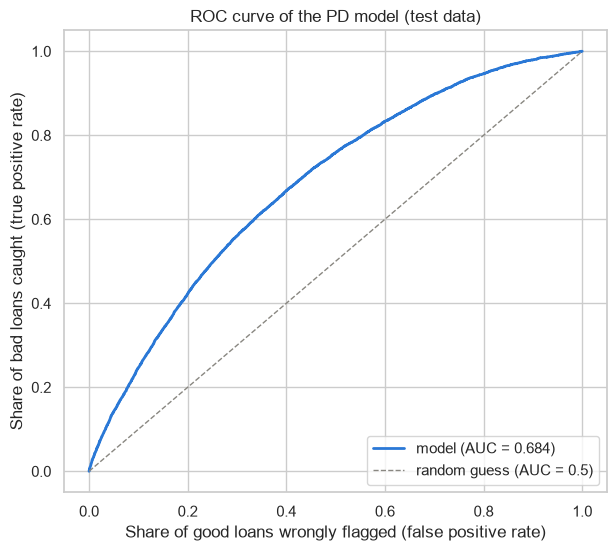

AUC: 0.6839


In [79]:
# plot_roc(true_values, scores, title, positive_label, negative_label)
#   true_values : 1 for the class we want to catch (e.g. bad loans), 0 for the others
#   scores      : the model's score, HIGHER = more likely to be class 1 (e.g. the PD)
# Draws the ROC curve and returns the AUC.
def plot_roc(true_values, scores, title, positive_label, negative_label):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(true_values, scores)
    auc = roc_auc_score(true_values, scores)

    plt.figure(figsize=(7, 6))
    plt.plot(false_positive_rate, true_positive_rate, linewidth=2, color=MAIN_COLOR,
             label='model (AUC = ' + str(round(auc, 3)) + ')')
    plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1, color=GREY, label='random guess (AUC = 0.5)')
    plt.xlabel('Share of ' + negative_label + ' wrongly flagged (false positive rate)')
    plt.ylabel('Share of ' + positive_label + ' caught (true positive rate)')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()
    return auc


# AUROC = the AUC of the PD model on the test data
AUROC = plot_roc(pd_results_test['is_bad'], pd_results_test['PD'],
                 'ROC curve of the PD model (test data)', 'bad loans', 'good loans')
print('AUC:', round(AUROC, 4))

**Overfitting check:** compare the AUC on the training data with the AUC on the test data. If the model had memorised the training loans (overfitting), it would score clearly better on them than on the unseen test loans, for example 0.80 against 0.68.

In [80]:
# PD of the training loans, and the AUC on the training data
pd_train = 1 - pd_model.predict(pd_inputs_train)
AUROC_train = roc_auc_score(1 - loan_data_targets_train, pd_train)

print('AUC on the training data:', round(AUROC_train, 4))
print('AUC on the test data    :', round(AUROC, 4))

AUC on the training data: 0.6798
AUC on the test data    : 0.6839


### 9.4 Gini coefficient

**Gini = 2 × AUC − 1.** It is the same information as AUC on a 0-to-1 scale where 0 = random and 1 = perfect. Banks often report Gini instead of AUC.

In [81]:
Gini = AUROC * 2 - 1
print('Gini:', round(Gini, 4))

Gini: 0.3679


### 9.5 Kolmogorov-Smirnov (KS) statistic

Sort the loans from the lowest to the highest PD and walk up the list. At every point, measure what share of **all good** loans and what share of **all bad** loans we have passed. A good model passes the good loans first (they have low PD), so the two curves separate.

**KS = the largest gap between the two curves.** 0 means no separation and 1 means perfect separation; in credit scoring, roughly 0.2 to 0.5 is common.

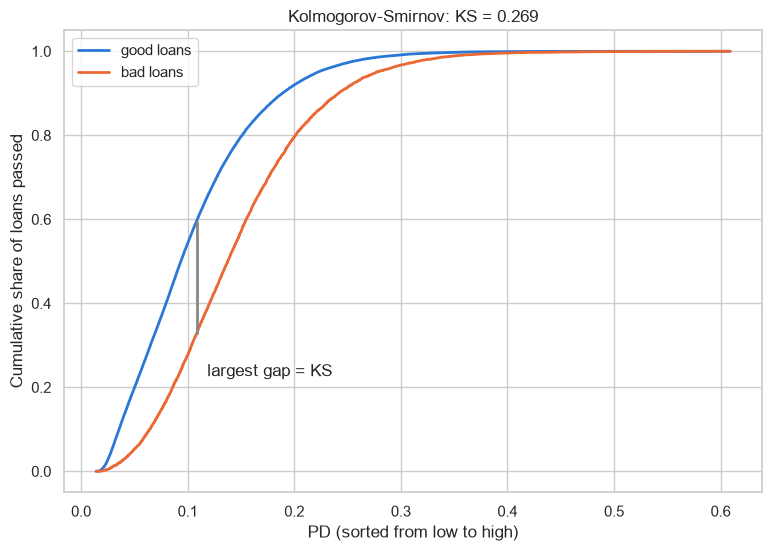

KS: 0.2686


In [82]:
# Sort the test loans from the lowest to the highest PD
ks_data = pd_results_test.sort_values('PD')

# Running share of all good loans and of all bad loans that we have passed (from 0 to 1)
ks_data['cumulative_share_good'] = ks_data['good_bad'].cumsum() / ks_data['good_bad'].sum()
ks_data['cumulative_share_bad'] = ks_data['is_bad'].cumsum() / ks_data['is_bad'].sum()

KS = (ks_data['cumulative_share_good'] - ks_data['cumulative_share_bad']).max()

# ks_point = the loan (row) where the gap between the two curves is the largest
ks_point = (ks_data['cumulative_share_good'] - ks_data['cumulative_share_bad']).idxmax()

plt.figure(figsize=(9, 6))
plt.plot(ks_data['PD'], ks_data['cumulative_share_good'], linewidth=2, color=MAIN_COLOR, label='good loans')
plt.plot(ks_data['PD'], ks_data['cumulative_share_bad'], linewidth=2, color=SECOND_COLOR, label='bad loans')
# grey vertical line = the KS gap
plt.vlines(ks_data.loc[ks_point, 'PD'], ks_data.loc[ks_point, 'cumulative_share_bad'],
           ks_data.loc[ks_point, 'cumulative_share_good'], color=GREY, linewidth=2)
plt.text(ks_data.loc[ks_point, 'PD'] + 0.01, ks_data.loc[ks_point, 'cumulative_share_bad'] - 0.1,
         'largest gap = KS')
plt.xlabel('PD (sorted from low to high)')
plt.ylabel('Cumulative share of loans passed')
plt.title('Kolmogorov-Smirnov: KS = ' + str(round(KS, 3)))
plt.legend()
plt.show()

print('KS:', round(KS, 4))

### 9.6 Calibration: does a PD of 10% really mean 10%?

AUC, Gini and KS measure **ranking**: are bad loans given higher PDs than good ones? A bank also needs the PD **level** to be right, because it multiplies PD by money in the Expected Loss. We cut the test loans into 10 equally big groups by PD (`pd.qcut`) and compare the average predicted PD with the actual bad rate in each group.

**If we skip it:** a model can rank loans perfectly and still predict PDs that are twice too high or too low. Prices and provisions would then be wrong.

,n_loans,average_predicted_PD,actual_bad_rate
PD_group,,,
1,9326,0.0289,0.0242
2,9326,0.0448,0.0410
3,9325,0.0606,0.0614
4,9326,0.0760,0.0760
5,9326,0.0905,0.0865
6,9328,0.1058,0.1074
7,9323,0.1232,0.1211
8,9325,0.1448,0.1532
9,9326,0.1755,0.1859


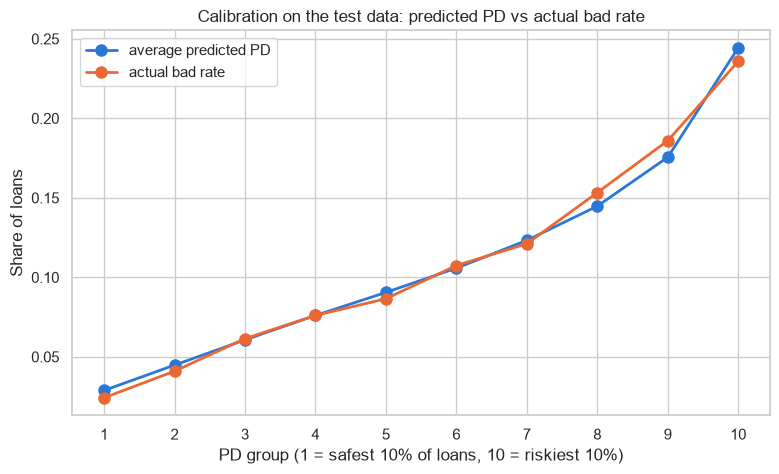

In [83]:
# PD_group = 1 (lowest PD, safest 10% of loans) ... 10 (highest PD, riskiest 10%)
pd_results_test['PD_group'] = pd.qcut(pd_results_test['PD'], 10, labels=range(1, 11))

# calibration = one row per PD group: number of loans, average predicted PD, actual share of bad loans
calibration = pd_results_test.groupby('PD_group', observed=True).agg(
    n_loans=('PD', 'count'),
    average_predicted_PD=('PD', 'mean'),
    actual_bad_rate=('is_bad', 'mean'))
display(calibration.round(4))

plt.figure(figsize=(9, 5))
plt.plot(calibration.index.astype(int), calibration['average_predicted_PD'], marker='o', markersize=8,
         linewidth=2, color=MAIN_COLOR, label='average predicted PD')
plt.plot(calibration.index.astype(int), calibration['actual_bad_rate'], marker='o', markersize=8,
         linewidth=2, color=SECOND_COLOR, label='actual bad rate')
plt.xticks(range(1, 11))
plt.xlabel('PD group (1 = safest 10% of loans, 10 = riskiest 10%)')
plt.ylabel('Share of loans')
plt.title('Calibration on the test data: predicted PD vs actual bad rate')
plt.legend()
plt.show()

**How to read it:** the two lines lie almost on top of each other. In each group, the PD the model predicts is close to the share of loans that really went bad. The bad rate rises steadily from the safest group to the riskiest one, so the model both ranks and calibrates well.

### 9.7 Summary of the PD model

| Measure | What it tells us | Our model (test data) |
|---|---|---|
| AUC | chance a random bad loan gets a higher PD than a random good one | ≈ 0.68 (fair) |
| Gini | 2 × AUC − 1 | ≈ 0.37 |
| KS | largest gap between the good and bad curves | ≈ 0.27 |
| Calibration | predicted PD vs actual bad rate | close in all 10 groups |

The model is useful but not spectacular. That is normal for this dataset: these are loans that Lending Club had **already approved**, so the riskiest applicants were rejected before they reached our data. The training AUC (Section 9.3) is about the same as the test AUC, so the model is **not overfitting**.

## 10. Scorecard: from probabilities to credit scores

### 10.1 The idea
A **scorecard** turns the model into simple points, on the same 300 to 850 range as the well-known FICO credit score:
- every category of every variable gets a number of **points**,
- a borrower's **credit score** = starting points (from the intercept) + the points of each category they belong to,
- a **higher score = safer** borrower.

**Why:** a loan officer, a customer or a regulator can read and check a points table. Nobody needs to understand logistic regression to use it, and the score converts back to exactly the model's PD (up to rounding).

### 10.2 How the points are calculated

1. Collect all coefficients, and add every reference category with coefficient 0.
2. For every variable, find its **smallest** and its **largest** coefficient. Adding up all the smallest coefficients (plus the intercept) gives the worst possible borrower (`min_sum_coef`); adding up all the largest gives the best possible borrower (`max_sum_coef`).
3. Stretch the coefficients so that the worst possible borrower scores exactly 300 and the best exactly 850:
   - category points = coefficient × (850 − 300) ÷ (max_sum_coef − min_sum_coef)
   - intercept points = (intercept − min_sum_coef) × (850 − 300) ÷ (max_sum_coef − min_sum_coef) + 300
4. Round the points to whole numbers.

**Common beginner mistakes:**
1. Forgetting the reference categories. They must be in the table with 0 points; otherwise some borrowers get no points for that variable.
2. Leaving the intercept out of the minimum and maximum sums. The scores then do not run from 300 to 850.
3. Comparing our score with a real FICO score. Only the 300-850 range is borrowed: a 650 here means something different from a FICO 650, or from a 650 of another version of this model. (Industry scorecards often fix instead how many points double the odds of being good, the "points to double the odds", or PDO.)

In [84]:
# MIN_SCORE / MAX_SCORE = the range of our credit score (the same range as the FICO score)
MIN_SCORE = 300
MAX_SCORE = 850

# 1. The model's coefficients ('const' is the intercept)
scorecard = pd.DataFrame({'feature': pd_model.params.index, 'coefficient': pd_model.params.values})

# 2. Add the reference categories with coefficient 0 (they were left out of the model on purpose)
reference_rows = pd.DataFrame({'feature': [reference_categories[v] for v in selected_variables],
                               'coefficient': 0.0})
scorecard = pd.concat([scorecard, reference_rows], ignore_index=True)

# The original variable of each feature = the text before ':'  (e.g. 'grade:A' -> 'grade')
scorecard['variable'] = scorecard['feature'].str.split(':').str[0]
scorecard.loc[scorecard['feature'] == 'const', 'variable'] = 'Intercept'

# 3. Worst and best possible borrower (the intercept counts in both sums)
min_sum_coef = scorecard.groupby('variable')['coefficient'].min().sum()
max_sum_coef = scorecard.groupby('variable')['coefficient'].max().sum()
print('min_sum_coef:', round(min_sum_coef, 4), '  max_sum_coef:', round(max_sum_coef, 4))

# points_per_unit = how many score points one unit of coefficient is worth
points_per_unit = (MAX_SCORE - MIN_SCORE) / (max_sum_coef - min_sum_coef)

scorecard['points'] = scorecard['coefficient'] * points_per_unit
is_intercept = scorecard['feature'] == 'const'     # True only in the intercept row
scorecard.loc[is_intercept, 'points'] = ((scorecard.loc[is_intercept, 'coefficient'] - min_sum_coef)
                                         * points_per_unit + MIN_SCORE)

# 4. Whole points
scorecard['points'] = scorecard['points'].round().astype(int)

# Check: the lowest and highest score anybody can get
print('Lowest possible score :', scorecard.groupby('variable')['points'].min().sum())
print('Highest possible score:', scorecard.groupby('variable')['points'].max().sum())

min_sum_coef: -1.2644   max_sum_coef: 4.3601
Lowest possible score : 300
Highest possible score: 849


**How to read the check:** the lowest and highest possible scores are 300 and 850, give or take 1 point from rounding each category to whole points.

### 10.3 The scorecard

In [85]:
# Sort by variable, then by points, so each variable reads from its worst to its best category
scorecard[['variable', 'feature', 'coefficient', 'points']].sort_values(['variable', 'points']).reset_index(drop=True)

,variable,feature,coefficient,points
0,Intercept,const,-1.221778,304
1,annual_inc,annual_inc:20K-30K,-0.042672,-4
2,annual_inc,annual_inc:<=20K,0.000000,0
3,annual_inc,annual_inc:30K-40K,0.024755,2
4,annual_inc,annual_inc:40K-50K,0.123439,12
5,annual_inc,annual_inc:50K-60K,0.192027,19
6,annual_inc,annual_inc:60K-70K,0.272440,27
7,annual_inc,annual_inc:70K-80K,0.345428,34
8,annual_inc,annual_inc:80K-90K,0.425772,42
9,annual_inc,annual_inc:90K-100K,0.452559,44


**How to read the scorecard:** every borrower starts with the `const` (intercept) points, then collects the points of exactly one category per variable. For example, an interest rate of at most 9.548% earns the most points of any category, while the reference categories earn 0. A category can even get a few **negative** points: `annual_inc:20K-30K` gets about −4, because the model found it slightly riskier than the reference category `<=20K` once all the other variables are taken into account (the difference is small and not significant, so merging the two categories would be a sensible simplification).

### 10.4 Score every test loan

In [86]:
# points = a lookup table: feature name -> points
points = scorecard.set_index('feature')['points']

# all_categories = every category of the selected variables, INCLUDING the reference categories
all_categories = []
for variable in selected_variables:
    for category in categories_by_variable[variable]:
        all_categories.append(category)

# Score = intercept points + the points of every category the loan belongs to.
#   Each loan has a 1 in exactly one category per variable, so .dot() (multiply each 0/1 by
#   that category's points and add everything up) collects exactly the right points.
pd_results_test['score'] = loan_data_inputs_test[all_categories].dot(points[all_categories]) + points['const']

pd_results_test['score'].describe()

count    93257.000000
mean       645.626055
std         67.555506
min        381.000000
25%        598.000000
50%        641.000000
75%        691.000000
max        839.000000
Name: score, dtype: float64

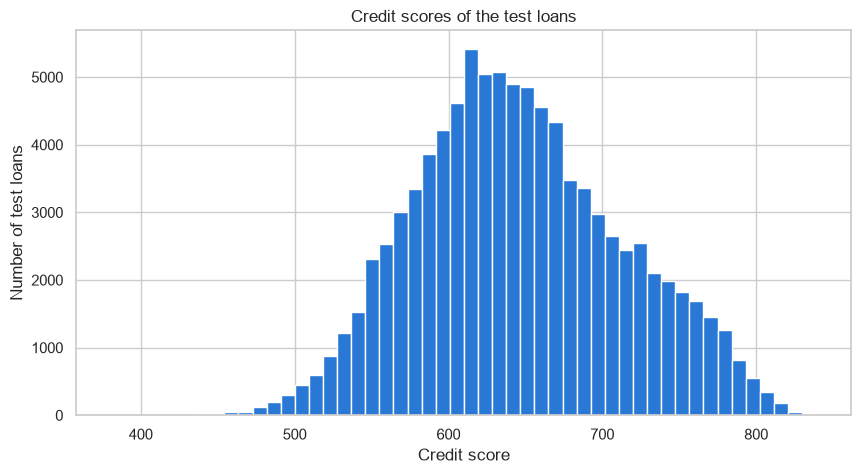

In [87]:
# Distribution of the scores of the test loans
plt.figure(figsize=(10, 5))
plt.hist(pd_results_test['score'], bins=50, color=MAIN_COLOR, edgecolor='white')
plt.xlabel('Credit score')
plt.ylabel('Number of test loans')
plt.title('Credit scores of the test loans')
plt.show()

### 10.5 Does a higher score really mean a safer loan?
We group the test loans into score bands and look at the share of bad loans in each band.

,n_loans,bad_rate
score_band,,
<=500,781,0.3470
501-550,5765,0.2378
551-600,18182,0.1798
601-650,27223,0.1121
651-700,21076,0.0731
701-750,12719,0.0402
>750,7511,0.0230


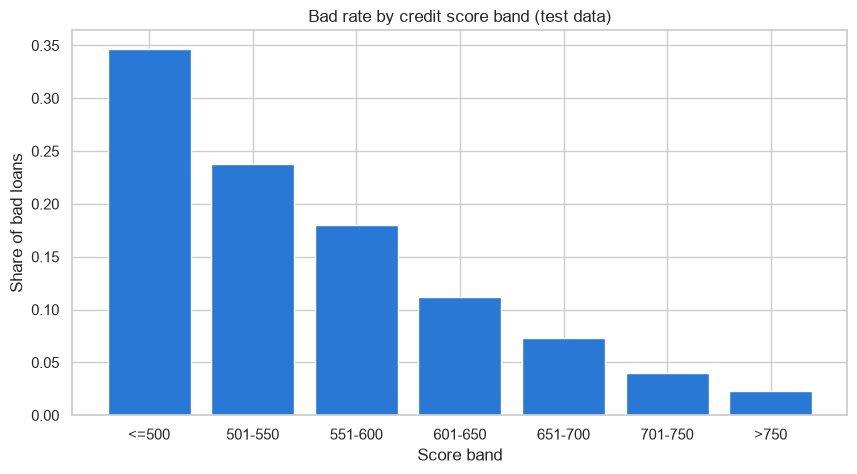

In [88]:
# score_band = the score range each loan falls into
pd_results_test['score_band'] = pd.cut(pd_results_test['score'],
                                       bins=[0, 500, 550, 600, 650, 700, 750, 900],
                                       labels=['<=500', '501-550', '551-600', '601-650', '651-700', '701-750', '>750'])

# score_bands = one row per score band: number of loans and share of bad loans
score_bands = pd_results_test.groupby('score_band', observed=True).agg(
    n_loans=('score', 'count'),
    bad_rate=('is_bad', 'mean'))
display(score_bands.round(4))

plt.figure(figsize=(10, 5))
plt.bar(score_bands.index.astype(str), score_bands['bad_rate'], color=MAIN_COLOR, edgecolor='white')
plt.xlabel('Score band')
plt.ylabel('Share of bad loans')
plt.title('Bad rate by credit score band (test data)')
plt.show()

**How to read it:** the bad rate falls steadily as the score rises, from about 35% in the lowest band to about 2% in the highest. The score ranks borrowers the way it should.

### 10.6 Choosing a cut-off: the approval decision
A lender approves applications with a score **at or above a cut-off** and rejects the rest. The cut-off is a **business trade-off**:
- a higher cut-off → fewer bad loans, but fewer customers (less income), and good customers are turned away;
- a lower cut-off → more customers, but more defaults.

In [89]:
cutoff_rows = []     # one row of results per cut-off score
for cutoff in [500, 550, 600, 650, 700]:
    approved = pd_results_test['score'] >= cutoff     # True for the loans we would approve
    cutoff_rows.append({
        'cut-off score': cutoff,
        'approval rate': round(approved.mean(), 3),                                        # share of loans approved
        'bad rate of approved': round(pd_results_test.loc[approved, 'is_bad'].mean(), 4),
        'bad rate of rejected': round(pd_results_test.loc[~approved, 'is_bad'].mean(), 4),
    })

pd.DataFrame(cutoff_rows)

,cut-off score,approval rate,bad rate of approved,bad rate of rejected
0,500,0.992,0.1074,0.3369
1,550,0.932,0.0990,0.2505
2,600,0.740,0.0776,0.1994
3,650,0.449,0.0541,0.1542
4,700,0.221,0.0345,0.1304


**How to read it:** each row is one possible policy. Moving the cut-off up lowers the approval rate and lowers the bad rate among the approved loans. For example, a cut-off of 600 approves about 74% of these loans, and the bad rate among them drops from 10.9% (approve everybody) to about 7.8%. A lender would pick the row where the profit from good loans best outweighs the losses from bad ones.

**Remember:** all these loans were already approved by Lending Club. A real cut-off would be set on *all applications*, including the ones that were rejected and therefore never appear in our data.

### 10.7 From a score back to a PD
Because the scorecard is just the model's coefficients rescaled, every score corresponds to exactly one PD:

In [90]:
# Undo the scaling (score -> sum of coefficients), then apply the logistic function -> P(good) -> PD
score_examples = pd.DataFrame({'score': [300, 400, 500, 550, 600, 650, 700, 750, 800, 850]})
sum_of_coefficients = ((score_examples['score'] - MIN_SCORE) / (MAX_SCORE - MIN_SCORE)
                       * (max_sum_coef - min_sum_coef) + min_sum_coef)
score_examples['PD'] = 1 - 1 / (1 + np.exp(-sum_of_coefficients))
score_examples.round(4)

,score,PD
0,300,0.7798
1,400,0.5602
2,500,0.3141
3,550,0.2155
4,600,0.1414
5,650,0.0899
6,700,0.0559
7,750,0.0343
8,800,0.0209
9,850,0.0126


**How to read it:** the higher the score, the lower the probability of default. A score of 650 means a PD of about 9%, and a score of 500 a PD of about 31%. A lender can publish a simple table like this one without showing anyone the model itself.

## 11. LGD model: how much do we lose when a borrower defaults?

### 11.1 The idea
When a loan is **charged off** (written off), the lender still tries to get some money back: it sells the debt or hands it to a collection agency. The amount collected is in `recoveries`, and the agency's fee is in `collection_recovery_fee`.

- **Amount owed at default** = funded amount − principal already repaid (`funded_amnt − total_rec_prncp`). This is the money at risk at the moment of default.
- **Recovery rate** = (recoveries − collection fee) ÷ amount owed at default: the share of the money at risk that came back, after paying the collector.
- **LGD** (Loss Given Default) = 1 − recovery rate: the share that is lost.

Example: $8,000 is owed when the borrower defaults; $1,000 is collected and the agency keeps $100. Recovery rate = (1,000 − 100) ÷ 8,000 ≈ 0.11, so LGD ≈ 0.89.

**Why divide by the amount owed (and not by the amount lent)?** Because Expected Loss multiplies LGD by EAD, the amount owed at default. LGD must therefore be a share *of that same amount*. Dividing by the original loan amount and then multiplying by EAD would shrink the recoveries twice.

**Which loans?** Only loans that were **charged off**: `Charged Off` and `Does not meet the credit policy. Status:Charged Off`. For them the recovery process has (mostly) happened. Loans with status `Default` are left out because they are not charged off yet, so their recoveries are still 0.

**If we skip this filter:** recoveries only exist for charged-off loans. Training on all loans would teach the model that "nobody recovers anything", because healthy loans have nothing to recover.

**Common beginner mistakes:**
1. Mixing up LGD and recovery rate. The model below predicts the **recovery rate**; LGD = 1 − recovery rate.
2. Using gross recoveries. The collector's fee is money the lender never sees.

### 11.2 Extra preparation: missing values as information
Unlike the PD model, the LGD and EAD models use the **numbers** directly (no WoE categories; regressions can use numbers as they are). But the two columns with "empty means never" still need care:

- New 0/1 **flag** columns: `never_delinquent` (1 = never late) and `never_public_record` (1 = no public record).
- New `..._filled` columns, where the empty months are replaced by 0. The flag tells the model that these 0s mean "never", not "this month".

We create **new** columns and leave the original ones untouched. Overwriting them would silently break the `Missing` categories of Part 6 if someone re-ran those cells later.

**If we just filled with 0 (without a flag):** "never late" would look exactly like "late this month", the opposite meaning (see Section 3.6).

In [91]:
# Flags: 1 = the value was empty (the event never happened), 0 = we know the value
loan_data['never_delinquent'] = np.where(loan_data['mths_since_last_delinq'].isnull(), 1, 0)
loan_data['never_public_record'] = np.where(loan_data['mths_since_last_record'].isnull(), 1, 0)

# New columns with the empty cells replaced by 0 (the flags above carry the "never" information)
loan_data['mths_since_last_delinq_filled'] = loan_data['mths_since_last_delinq'].fillna(0)
loan_data['mths_since_last_record_filled'] = loan_data['mths_since_last_record'].fillna(0)

# loan_data_defaults = only the charged-off loans (a real copy, so changes do not touch loan_data)
charged_off_statuses = ['Charged Off', 'Does not meet the credit policy. Status:Charged Off']
loan_data_defaults = loan_data[loan_data['loan_status'].isin(charged_off_statuses)].copy()
print('Charged-off loans:', len(loan_data_defaults))

Charged-off loans: 43236


### 11.3 The target: recovery rate

In [92]:
# amount_owed_at_default = money still owed when the loan defaulted (needed for LGD and for EAD)
loan_data_defaults['amount_owed_at_default'] = loan_data_defaults['funded_amnt'] - loan_data_defaults['total_rec_prncp']

# recovery_rate = share of the amount owed that came back, after the collection agency's fee
loan_data_defaults['recovery_rate'] = ((loan_data_defaults['recoveries'] - loan_data_defaults['collection_recovery_fee'])
                                       / loan_data_defaults['amount_owed_at_default'])

# A few loans recovered more than was owed (late fees and interest): a share above 1 makes no sense, so cap at 1
print('Loans with a recovery rate above 1:', (loan_data_defaults['recovery_rate'] > 1).sum())
loan_data_defaults['recovery_rate'] = loan_data_defaults['recovery_rate'].clip(0, 1)

loan_data_defaults['recovery_rate'].describe()

Loans with a recovery rate above 1: 32


count    43236.000000
mean         0.073651
std          0.098901
min          0.000000
25%          0.000000
50%          0.044940
75%          0.140612
max          1.000000
Name: recovery_rate, dtype: float64

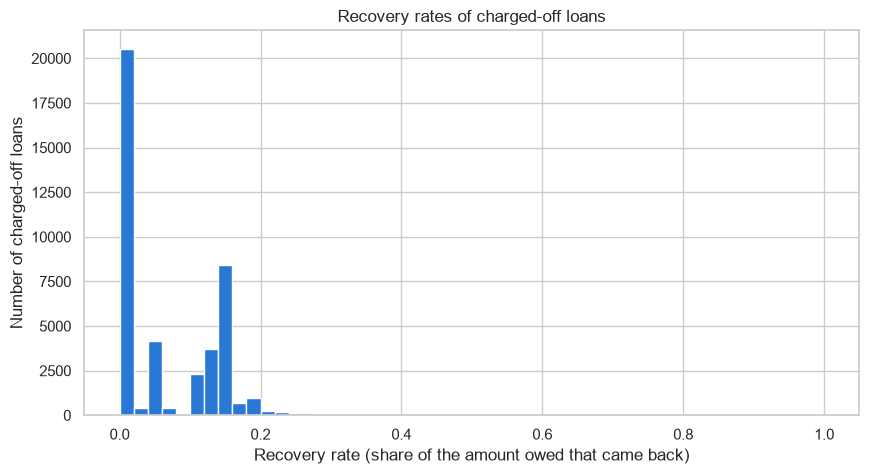

Share of charged-off loans with NOTHING recovered: 0.436


In [93]:
plt.figure(figsize=(10, 5))
plt.hist(loan_data_defaults['recovery_rate'], bins=50, color=MAIN_COLOR, edgecolor='white')
plt.xlabel('Recovery rate (share of the amount owed that came back)')
plt.ylabel('Number of charged-off loans')
plt.title('Recovery rates of charged-off loans')
plt.show()

print('Share of charged-off loans with NOTHING recovered:',
      round((loan_data_defaults['recovery_rate'] == 0).mean(), 3))

**How to read it:** on average only about 7% of the amount owed is recovered (so LGD ≈ 93%). And about **44% of the charged-off loans recovered nothing at all**: the huge bar at 0.

### 11.4 Why two stages?
One straight-line (linear) regression cannot handle a target where almost half of the values are exactly 0. It would predict small positive numbers for everybody and never a true zero. So we split the question in two:

| Stage | Question | Model | Data |
|---|---|---|---|
| 1 | Will **anything** be recovered? (yes / no) | logistic regression | all charged-off loans |
| 2 | If yes, **how much**? (share recovered) | linear regression | only loans with recovery > 0 |

**Combined:** expected recovery rate = P(anything recovered) × predicted recovery rate if something is recovered. In words: "the chance of recovering something" × "how much, when we do".

**If we skip the two stages:** a single linear regression would be pulled down by the zeros and badly describe both groups.

**Common beginner mistake:** using a model that ignores the shape of the target. Always plot the target first, as we did above.

In [94]:
# recovery_rate_0_1 = target of stage 1: 1 if something was recovered, 0 if nothing
loan_data_defaults['recovery_rate_0_1'] = np.where(loan_data_defaults['recovery_rate'] > 0, 1, 0)
loan_data_defaults['recovery_rate_0_1'].value_counts()

recovery_rate_0_1
1    24371
0    18865
Name: count, dtype: int64

### 11.5 Inputs of the LGD (and EAD) models
- **Numbers** used as they are: loan amount, term, interest rate, employment length, income, dti, credit history and the other credit-file counts (with the two flags from Section 11.2).
- **Dummy variables** for the categories, each with **one reference category left out** (the dummy variable trap from Part 7): `grade` (reference: G), `home_ownership` (reference: RENT and the tiny OTHER/NONE/ANY groups), `verification_status` (reference: Verified), `purpose` (reference: credit_card), `initial_list_status` (reference: f).

Left out: `installment` (almost completely determined by amount, rate and term; see Part 6), `addr_state` (50 states is too many for about 43,000 loans), loan age, and `total_rev_hi_lim` (both bring the loan-age trap in; see Part 6).

In [95]:
# lgd_ead_features = the inputs of the LGD and EAD models
lgd_ead_features = [
    # --- numbers ---
    'funded_amnt', 'term_int', 'int_rate', 'emp_length_int', 'annual_inc', 'dti',
    'mths_since_earliest_cr_line', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec',
    'total_acc', 'acc_now_delinq',
    'mths_since_last_delinq_filled', 'never_delinquent', 'mths_since_last_record_filled', 'never_public_record',
    # --- dummy variables (the reference category of each variable is left out) ---
    'grade:A', 'grade:B', 'grade:C', 'grade:D', 'grade:E', 'grade:F',
    'home_ownership:MORTGAGE', 'home_ownership:OWN',
    'verification_status:Not Verified', 'verification_status:Source Verified',
    'purpose:car', 'purpose:debt_consolidation', 'purpose:educational', 'purpose:home_improvement',
    'purpose:house', 'purpose:major_purchase', 'purpose:medical', 'purpose:moving', 'purpose:other',
    'purpose:renewable_energy', 'purpose:small_business', 'purpose:vacation', 'purpose:wedding',
    'initial_list_status:w',
]
print('Number of LGD/EAD inputs:', len(lgd_ead_features))

Number of LGD/EAD inputs: 41


### 11.6 Training and test split (again)
Same idea as Part 5: 80% of the charged-off loans to build the models, 20% to test them.

In [96]:
# lgd_train / lgd_test = the charged-off loans used to build (80%) and to test (20%) the LGD and EAD models
lgd_train, lgd_test = train_test_split(loan_data_defaults, test_size=0.2, random_state=42)

# Model inputs with the 'const' column of 1s for the intercept
lgd_inputs_train = sm.add_constant(lgd_train[lgd_ead_features].astype(float))
lgd_inputs_test = sm.add_constant(lgd_test[lgd_ead_features].astype(float))

print('Training loans:', len(lgd_train), '   Test loans:', len(lgd_test))

Training loans: 34588    Test loans: 8648


### 11.7 Stage 1: will anything be recovered? (logistic regression)
Exactly the same technique as the PD model, with a different target: 1 = something recovered, 0 = nothing.

In [97]:
# lgd_stage_1 = logistic regression: probability that something will be recovered
lgd_stage_1 = sm.Logit(lgd_train['recovery_rate_0_1'], lgd_inputs_train).fit(disp=False)

# lgd_stage_1_summary = coefficient and p-value of every input
#   more decimals, because for variables measured in dollars the effect of ONE dollar is tiny
lgd_stage_1_summary = pd.DataFrame({'coefficient': lgd_stage_1.params, 'p_value': lgd_stage_1.pvalues})
lgd_stage_1_summary.round(6)

,coefficient,p_value
const,-0.538275,0.024051
funded_amnt,0.000006,0.000593
term_int,0.003101,0.014041
int_rate,0.059825,0.000000
emp_length_int,0.001127,0.718749
annual_inc,0.000001,0.000999
dti,-0.016154,0.000000
mths_since_earliest_cr_line,-0.001020,0.000000
delinq_2yrs,0.003208,0.866867
inq_last_6mths,0.038481,0.000039


**How to read some coefficients:**
- `grade:A` is clearly positive: defaulted loans from good grades are more likely to recover something (compared with grade G).
- `initial_list_status:w` is strongly negative. Whole loans (`w`) are mostly young loans from 2013-2014, and their collection process was often not finished when the data was collected (the "incomplete recoveries" limitation in Part 14).
- Coefficients of dollar variables (`funded_amnt`, `annual_inc`) look tiny (for example 0.000006) because they are the effect of **one single dollar**. Multiplied by $10,000 the effect is clearly visible.

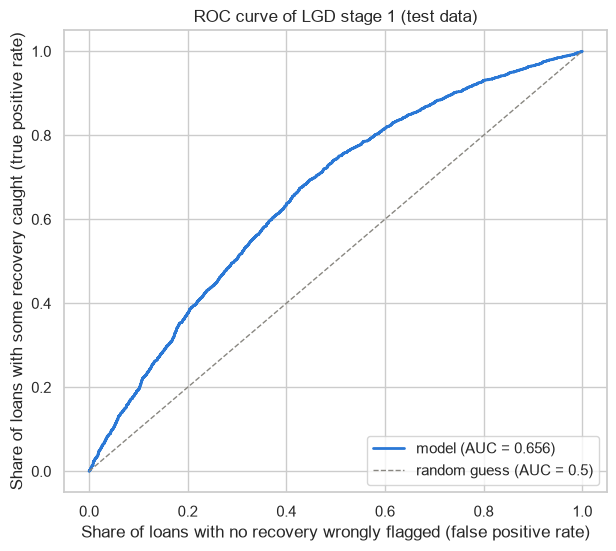

AUC of stage 1: 0.656


In [98]:
# Probability that something will be recovered, for the test loans
lgd_test_results = pd.DataFrame({'actual_recovery_rate': lgd_test['recovery_rate'],
                                 'actual_recovered_0_1': lgd_test['recovery_rate_0_1']})
lgd_test_results['P_recovery'] = lgd_stage_1.predict(lgd_inputs_test)

# AUROC_stage_1 = the AUC of stage 1 on the test loans
AUROC_stage_1 = plot_roc(lgd_test_results['actual_recovered_0_1'], lgd_test_results['P_recovery'],
                         'ROC curve of LGD stage 1 (test data)',
                         'loans with some recovery', 'loans with no recovery')
print('AUC of stage 1:', round(AUROC_stage_1, 4))

**How to read it:** an AUC of about 0.66 means the model separates "something recovered" from "nothing recovered" clearly better than chance, but far from perfectly. Recoveries depend a lot on things that are not in the application data, such as the collection agency's effort or the borrower's situation years later.

### 11.8 Stage 2: how much is recovered? (linear regression)

**Linear regression** in plain English: predict a **number** as a weighted sum of the inputs:
`recovery rate = intercept + coefficient₁ × input₁ + coefficient₂ × input₂ + ...`
It chooses the coefficients that make the squared differences between actual and predicted values as small as possible (**OLS** = Ordinary Least Squares).

**R²** (R-squared) = the share of the ups and downs in the target that the model explains: 0 = nothing, 1 = everything. LGD models typically have a low R², because recoveries are hard to predict from application data.

**Common beginner mistakes:**
1. Training stage 2 on all charged-off loans. Stage 2 must only see loans with recovery > 0, because the zeros are stage 1's job.
2. Trusting predictions outside 0 to 1. A straight line can go below 0 or above 1, so we cut (clip) predictions to that range.

In [99]:
# Stage 2 uses only the loans where something was recovered
stage_2_train = lgd_train[lgd_train['recovery_rate_0_1'] == 1]
stage_2_test = lgd_test[lgd_test['recovery_rate_0_1'] == 1]

# lgd_stage_2 = linear regression (OLS): recovery rate of the loans where something was recovered
lgd_stage_2 = sm.OLS(stage_2_train['recovery_rate'],
                     sm.add_constant(stage_2_train[lgd_ead_features].astype(float))).fit()

print('Stage 2 R-squared on the training data:', round(lgd_stage_2.rsquared, 4))

# Check on the test loans with recovery > 0: how close are the predictions to the actual recovery rates?
#   a.corr(b) = correlation between two columns: 1 = move perfectly together, 0 = no relationship
stage_2_predicted = lgd_stage_2.predict(sm.add_constant(stage_2_test[lgd_ead_features].astype(float)))
print('Correlation between actual and predicted recovery rate (test):',
      round(stage_2_test['recovery_rate'].corr(stage_2_predicted), 4))

Stage 2 R-squared on the training data:

 0.0278
Correlation between actual and predicted recovery rate (test): 0.1436


**How to read it:** R² ≈ 0.03 is very low. The inputs explain only a tiny part of *how much* is recovered. The **correlation** between actual and predicted values (from -1 to 1, where 0 means no relationship) is about 0.14: positive, but weak. This is typical for LGD models built only from application data, because the amount recovered depends on what happens years after the application.

### 11.9 Combine the two stages

In [100]:
# Stage 2 prediction for ALL test loans (also those that recovered nothing)
lgd_test_results['recovery_if_any'] = lgd_stage_2.predict(lgd_inputs_test)

# expected recovery rate = P(something recovered) x (how much, if something is recovered), kept between 0 and 1
lgd_test_results['predicted_recovery_rate'] = (lgd_test_results['P_recovery']
                                               * lgd_test_results['recovery_if_any']).clip(0, 1)
lgd_test_results['predicted_LGD'] = 1 - lgd_test_results['predicted_recovery_rate']

print('Average actual recovery rate   :', round(lgd_test_results['actual_recovery_rate'].mean(), 4))
print('Average predicted recovery rate:', round(lgd_test_results['predicted_recovery_rate'].mean(), 4))
print('Correlation actual vs predicted:',
      round(lgd_test_results['actual_recovery_rate'].corr(lgd_test_results['predicted_recovery_rate']), 4))

lgd_test_results.head()

Average actual recovery rate   : 0.0745
Average predicted recovery rate: 0.0732
Correlation actual vs predicted: 0.1377


,actual_recovery_rate,actual_recovered_0_1,P_recovery,recovery_if_any,predicted_recovery_rate,predicted_LGD
178928,0.005418,1,0.364750,0.161675,0.058971,0.941029
69814,0.256291,1,0.618718,0.115599,0.071523,0.928477
101396,0.000000,0,0.685854,0.138568,0.095038,0.904962
463268,0.143337,1,0.581602,0.117785,0.068504,0.931496
253729,0.000000,0,0.627810,0.123785,0.077714,0.922286


**How to read it:** on average the model gets the recovery rate right (predicted ≈ 7.3%, actual ≈ 7.5%), which is what matters most for Expected Loss over a whole portfolio. For single loans the predictions are rough (correlation ≈ 0.14).

**Why "probability × amount" and not "0 or 1 × amount"?** Some versions of this method first turn stage 1 into a hard yes/no (threshold 0.5) and then multiply. Using the **probability** gives the statistically *expected* recovery and, on this data, a better match: the 0/1 version predicts an average recovery of about 9.2% (too high) and correlates less with the actual values (≈ 0.12).

## 12. EAD model: how much is still owed at the moment of default?

### 12.1 The idea
Borrowers repay part of the loan before they default. The **Credit Conversion Factor (CCF)** measures the share of the original amount that was still owed:

> CCF = amount owed at default ÷ funded amount = (funded amount − principal repaid) ÷ funded amount

**EAD = CCF × funded amount.** Example: a $10,000 loan where $3,000 of principal was repaid has CCF = 0.7 and EAD = $7,000.

**A note on the name:** in the Basel rules, "CCF" has a narrower meaning. It is used for credit *lines* (like credit cards), as the share of the **unused** limit that the borrower draws before defaulting. Our loans were paid out in full on day one, so here CCF simply means "share of the original amount still owed", a common simplification in credit-risk courses.

**Why model a share and not the dollar amount?** The share is comparable across loans of different sizes ($1,000 or $35,000), and the dollar EAD follows by multiplying with the amount.

**If we skip the EAD model** and simply use the full loan amount as EAD: we would overstate the exposure (on average borrowers repay about a quarter of the principal before defaulting) and overstate the expected loss.

**Common beginner mistake:** using `out_prncp` (principal still outstanding today) as EAD. For charged-off loans it is 0, because the loan was written off. The amount owed at default has to be rebuilt from `funded_amnt − total_rec_prncp`.

In [101]:
# CCF = share of the funded amount that was still owed when the loan defaulted
loan_data_defaults['CCF'] = loan_data_defaults['amount_owed_at_default'] / loan_data_defaults['funded_amnt']
loan_data_defaults['CCF'].describe()

count    43236.000000
mean         0.735952
std          0.200742
min          0.000438
25%          0.632088
50%          0.789908
75%          0.888543
max          1.000000
Name: CCF, dtype: float64

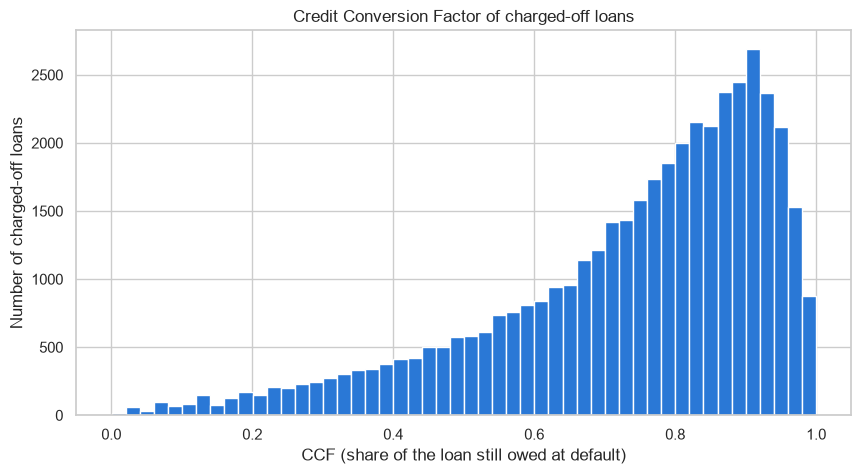

In [102]:
plt.figure(figsize=(10, 5))
plt.hist(loan_data_defaults['CCF'], bins=50, color=MAIN_COLOR, edgecolor='white')
plt.xlabel('CCF (share of the loan still owed at default)')
plt.ylabel('Number of charged-off loans')
plt.title('Credit Conversion Factor of charged-off loans')
plt.show()

**How to read it:** on average about 74% of the original amount was still owed at default. Most borrowers default early in the life of the loan, before repaying much.

### 12.2 Linear regression for the CCF
We reuse exactly the same inputs and the same training and test loans as the LGD model: `.loc[lgd_train.index]` picks the rows of the LGD training loans.

In [103]:
# The CCF of the same training / test loans as in the LGD model
ead_train = loan_data_defaults.loc[lgd_train.index]
ead_test = loan_data_defaults.loc[lgd_test.index]

# ead_model = linear regression (OLS) of the CCF, with the same inputs as the LGD model
ead_model = sm.OLS(ead_train['CCF'], lgd_inputs_train).fit()
print('EAD model R-squared on the training data:', round(ead_model.rsquared, 4))

# ead_summary = coefficient and p-value of every input
ead_summary = pd.DataFrame({'coefficient': ead_model.params, 'p_value': ead_model.pvalues})
ead_summary.round(6)

EAD model R-squared on the training data: 0.1955


,coefficient,p_value
const,0.461609,0.000000
funded_amnt,0.000001,0.000980
term_int,0.004574,0.000000
int_rate,0.003107,0.000010
emp_length_int,-0.001541,0.000000
annual_inc,0.000000,0.178885
dti,0.001319,0.000000
mths_since_earliest_cr_line,0.000014,0.271718
delinq_2yrs,0.006578,0.000059
inq_last_6mths,0.003775,0.000002


**How to read some coefficients:**
- `term_int` is positive: longer loans are repaid more slowly, so more is still owed when they default.
- `grade:A` and `grade:B` are negative: better-grade borrowers who default have usually repaid more before defaulting.

Average actual CCF   : 0.734
Average predicted CCF: 0.7371
Correlation actual vs predicted: 0.4562


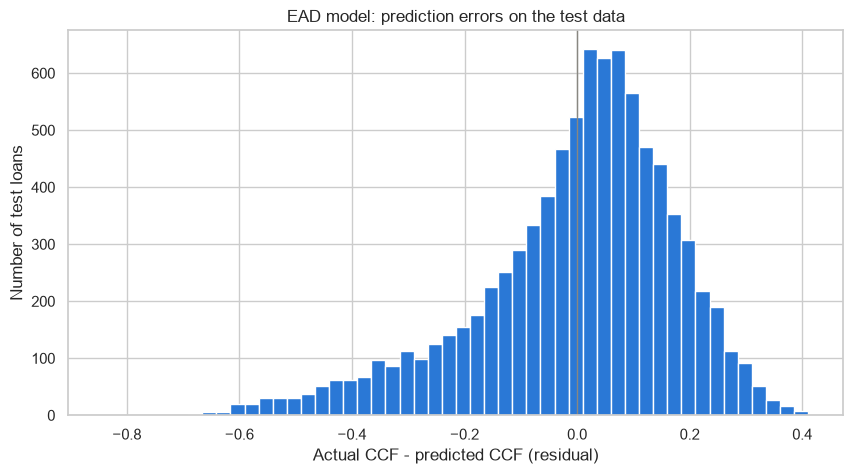

In [104]:
# Predict the CCF of the test loans and keep it between 0 and 1
ead_test_results = pd.DataFrame({'actual_CCF': ead_test['CCF']})
ead_test_results['predicted_CCF'] = ead_model.predict(lgd_inputs_test).clip(0, 1)

print('Average actual CCF   :', round(ead_test_results['actual_CCF'].mean(), 4))
print('Average predicted CCF:', round(ead_test_results['predicted_CCF'].mean(), 4))
print('Correlation actual vs predicted:',
      round(ead_test_results['actual_CCF'].corr(ead_test_results['predicted_CCF']), 4))

# Residual = actual - predicted. A good model has residuals centred around 0.
plt.figure(figsize=(10, 5))
plt.hist(ead_test_results['actual_CCF'] - ead_test_results['predicted_CCF'], bins=50,
         color=MAIN_COLOR, edgecolor='white')
plt.axvline(0, color=GREY, linewidth=1)
plt.xlabel('Actual CCF - predicted CCF (residual)')
plt.ylabel('Number of test loans')
plt.title('EAD model: prediction errors on the test data')
plt.show()

**How to read it:** R² ≈ 0.2 and a correlation of about 0.46 between actual and predicted CCF: a useful, moderate model, clearly better than the LGD model. The average predicted CCF matches the actual average almost exactly, and the errors are centred around 0 (no systematic over- or under-prediction).

## 13. Expected Loss: putting PD, LGD and EAD together

For **every loan** in the portfolio:
- **PD** from the PD model (Part 8),
- **LGD** = 1 − expected recovery rate from the two-stage LGD model (Part 11),
- **EAD** = predicted CCF × funded amount (Part 12),
- **EL = PD × LGD × EAD**, in dollars.

**Common beginner mistakes:**
1. Using P(good) instead of PD, which inflates the loss about 8 times.
2. Mixing up units: LGD and PD must be shares (0.9, not 90), and EAD must be in dollars.
3. Thinking EL is the worst case. EL is the **average** loss to expect. Bad years cause losses far above EL ("unexpected loss"), and that is what bank capital is for.

In [105]:
# PD of every loan: the training and test inputs together contain every loan exactly once
pd_inputs_all = sm.add_constant(pd.concat([loan_data_inputs_train[features],
                                           loan_data_inputs_test[features]]).astype(float))
loan_data['PD'] = 1 - pd_model.predict(pd_inputs_all)     # pandas matches the rows by their index

# LGD and EAD of every loan, with the same inputs as in Parts 11 and 12
#   lgd_ead_inputs_all     = the LGD/EAD inputs (+ 'const') of every loan in the portfolio
#   expected_recovery_rate = P(something recovered) x (how much, if something is recovered), kept between 0 and 1
lgd_ead_inputs_all = sm.add_constant(loan_data[lgd_ead_features].astype(float))
expected_recovery_rate = (lgd_stage_1.predict(lgd_ead_inputs_all)
                          * lgd_stage_2.predict(lgd_ead_inputs_all)).clip(0, 1)
loan_data['LGD'] = 1 - expected_recovery_rate
loan_data['CCF'] = ead_model.predict(lgd_ead_inputs_all).clip(0, 1)
loan_data['EAD'] = loan_data['CCF'] * loan_data['funded_amnt']

# Expected Loss in dollars
loan_data['EL'] = loan_data['PD'] * loan_data['LGD'] * loan_data['EAD']

loan_data[['funded_amnt', 'PD', 'LGD', 'EAD', 'EL']].head()

,funded_amnt,PD,LGD,EAD,EL
0,5000,0.110315,0.930043,3146.437602,322.817258
1,2500,0.221264,0.928820,1927.510878,396.132156
2,2400,0.296888,0.913046,1582.423798,428.951944
3,10000,0.145508,0.925796,6946.174510,935.721722
4,3000,0.109089,0.922246,2312.430770,232.645716


**How to read one row:** the first loan ($5,000) gets a PD of about 11%. If it defaulted, about $3,150 would still be owed (EAD) and about 93% of that would be lost (LGD). EL = 0.110 × 0.930 × $3,146 ≈ **$323**: on average, this is what the lender should expect to lose on such a loan. It works like an insurance premium that the interest rate has to cover.

In [106]:
loan_data[['funded_amnt', 'PD', 'LGD', 'EAD', 'EL']].describe()

,funded_amnt,PD,LGD,EAD,EL
count,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000
mean,14291.801044,0.109342,0.931138,10494.772548,1090.726666
std,8274.371300,0.063896,0.017495,6733.508567,1069.578701
min,500.000000,0.013879,0.104476,264.009292,11.724305
25%,8000.000000,0.060833,0.918997,5326.727673,367.433761
50%,12000.000000,0.097618,0.928903,8937.799501,718.518389
75%,20000.000000,0.144155,0.944819,14284.394902,1432.316059
max,35000.000000,0.734657,0.988292,35000.000000,12419.597869


In [107]:
# total_funded = all the money lent; total_expected_loss = the sum of the Expected Loss of every loan
total_funded = loan_data['funded_amnt'].sum()
total_expected_loss = loan_data['EL'].sum()

print('Total amount lent    : $', round(total_funded / 1e9, 2), 'billion')
print('Total Expected Loss  : $', round(total_expected_loss / 1e6, 1), 'million')
print('Expected Loss as a share of the amount lent:', round(total_expected_loss / total_funded, 4))

Total amount lent    : $ 6.66 billion
Total Expected Loss  : $ 508.6 million
Expected Loss as a share of the amount lent: 0.0763


**How to read it:** over the whole portfolio, the lender (here: Lending Club's investors) should expect to lose about **7.6% of the amount lent**, about $509 million out of $6.66 billion. That is a big number, and it is why Lending Club charged interest rates from about 6% to 26% a year.

**Careful with the time period:** our PD is "bad by the time the data was collected" (Part 4), and many loans were still running then. So this is not a full lifetime loss; the true lifetime loss of these loans would be higher.

### 13.1 Expected Loss by grade

,n_loans,amount_lent,expected_loss,average_PD,actual_bad_rate,average_LGD,average_interest_rate,EL_share_of_amount_lent
grade,,,,,,,,
A,74867,1000867250,2.132345e+07,0.0390,0.0387,0.9350,7.5386,0.0213
B,136929,1793263750,8.376266e+07,0.0790,0.0786,0.9324,11.5033,0.0467
C,125293,1776868750,1.338802e+08,0.1142,0.1148,0.9336,14.6341,0.0753
D,76888,1156838775,1.220502e+08,0.1537,0.1541,0.9278,17.5406,0.1055
E,35757,625042825,8.896898e+07,0.1947,0.1948,0.9251,20.4871,0.1423
F,13229,242924925,4.460898e+07,0.2456,0.2413,0.9129,23.5514,0.1836
G,3322,68246175,1.399506e+07,0.2716,0.2781,0.9148,24.8384,0.2051


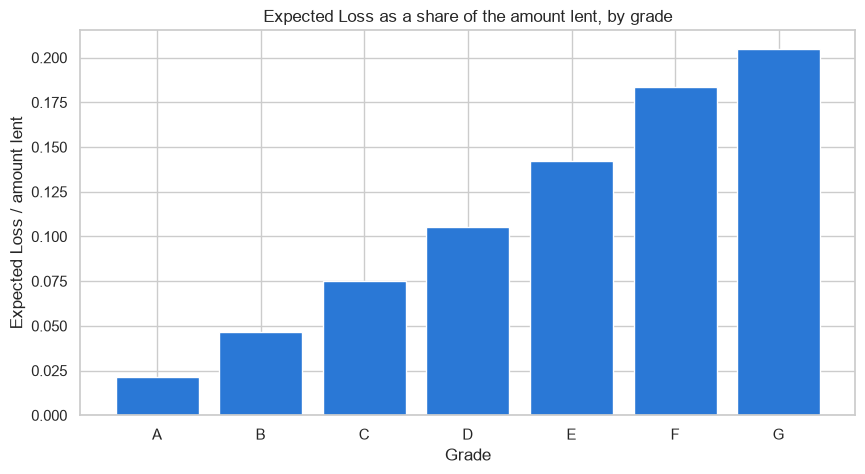

In [108]:
# el_by_grade = one row per grade: number of loans, money lent, Expected Loss, average PD/LGD, interest rate
el_by_grade = loan_data.groupby('grade').agg(
    n_loans=('EL', 'count'),
    amount_lent=('funded_amnt', 'sum'),
    expected_loss=('EL', 'sum'),
    average_PD=('PD', 'mean'),
    actual_bad_rate=('good_bad', lambda good_bad: 1 - good_bad.mean()),   # share of bad loans in the grade
    average_LGD=('LGD', 'mean'),
    average_interest_rate=('int_rate', 'mean'))
el_by_grade['EL_share_of_amount_lent'] = el_by_grade['expected_loss'] / el_by_grade['amount_lent']
display(el_by_grade.round(4))

plt.figure(figsize=(10, 5))
plt.bar(el_by_grade.index, el_by_grade['EL_share_of_amount_lent'], color=MAIN_COLOR, edgecolor='white')
plt.xlabel('Grade')
plt.ylabel('Expected Loss / amount lent')
plt.title('Expected Loss as a share of the amount lent, by grade')
plt.show()

**How to read it:**
- The Expected Loss share rises steadily from grade A to grade G. The riskier the grade, the more of each dollar lent the lender expects to lose.
- The model's average PD per grade is very close to the **actual** bad rate in each grade. Don't over-celebrate this: about 80% of these loans were used to fit the model, and a logistic regression with grade dummies automatically reproduces the bad rate of each grade in its training data. The honest calibration check is Section 9.6, on test data only.
- The interest rate also rises with the grade. Interest is earned every year for 3 to 5 years, while EL is a loss over the life of the loan, so the two are not directly comparable, but the direction matches: risk-based pricing.
- `lambda good_bad: 1 - good_bad.mean()` is a tiny one-line function: for each grade it takes the `good_bad` column and returns the share of bad loans.

## 14. Summary, limitations and next steps

### What we built
| Step | Result |
|---|---|
| PD model (logistic regression, 11 variables, scorecard 300-850) | test AUC ≈ 0.68, Gini ≈ 0.37, KS ≈ 0.27, well calibrated on test data |
| LGD model (two stages) | stage 1 AUC ≈ 0.66; stage 2 R² ≈ 0.03; average recovery rate predicted correctly (≈ 7%) |
| EAD model (linear regression on CCF) | R² ≈ 0.20; average CCF predicted correctly (≈ 0.74) |
| Expected Loss | ≈ 7.6% of the amount lent; from ≈ 2% (grade A) to ≈ 20% (grade G) |

### Limitations: be honest about them
1. **"Current" loans count as good** (Part 4), although some of them will still default. This makes young loans look safer than they are.
2. **PD has no clean time period:** it is "bad by the time the data was collected", a mix of finished and unfinished loans. It is neither a 12-month PD (capital rules) nor a lifetime PD (provisions), and the Expected Loss above is lower than a true lifetime loss would be.
3. **Only approved loans:** applicants Lending Club rejected are not in the data (selection bias). The model has never seen the riskiest applicants.
4. **`int_rate` and `grade` are Lending Club's own decisions:** they are our two strongest inputs, but a lender building its own scorecard from scratch would not have them, and using them to *set* prices would be circular.
5. **Incomplete recoveries:** for loans charged off shortly before the data was collected, collection was still going on, so their recovery rates are too low (LGD too high).
6. **Straight-line models for shares:** LGD and CCF must lie between 0 and 1, but linear regression does not know that. We clip the predictions; more advanced models (for example beta regression) respect the range by design.
7. **One time period (2007-2014):** it includes the financial crisis and its recovery. The risk of a new period can differ.
8. **No monitoring yet:** a real model is checked regularly on new loans, for example with the **Population Stability Index (PSI)**, which measures whether new applicants look different from the training data.

### Ideas for next steps
- Rebuild the PD model with finished loans only (Fully Paid vs. Charged Off), which also gives the PD a clear time period (the life of the loan).
- Monitor the model with PSI on loans from 2015 onwards.
- Try other models (for example gradient boosting) as a **challenger** and compare AUC. Keep in mind that banks often prefer the transparent scorecard.
- Merge neighbouring categories whose points are not significantly different (for example `annual_inc` `<=20K` and `20K-30K`).